# PLA Design of Experiments Notebook


In [1]:
# Install once if needed:
# %pip install pandas matplotlib jinja2

import pandas as pd
from IPython.display import display

from pla_doe_measurements import (
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS,
    FD_I_LEVELS,
    FD_II_LEVELS,
    IRONING_FIXED_SETTINGS,
    IRONING_LEVELS,
    IRONING_MASS_MEASUREMENTS_G,
    IRONING_CONFIRMATION_RUNS,
    IRONING_STRINGING_RUNS,
    IRONING_REPEAT_STRINGING_RUNS,
    IRONING_REPEAT_BLOB_COUNTS,
    IRONING_BLOB_COUNTS,
    IRONING_REPEAT_MASS_MEASUREMENTS_G,
    IRONING_RUN_LABELS,
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    EXTRA_RUN_LABELS,
    FD_I_MASS_1_G,
    FD_I_MASS_MEASUREMENTS_G,
    FD_I_HYDROSTATIC_MEASUREMENTS,
    FD_I_REPEAT_MASS_1_G,
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_MASS_MEASUREMENTS_G,
    FD_II_CONCENTRIC_RUN_LABELS,
    FD_II_CONCENTRIC_MASS_MEASUREMENTS_G,
)
from DoE_old_scale import (
    FD_I_OLD_SCALE_MASS_MEASUREMENTS_G,
    FD_I_OLD_SCALE_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_OLD_SCALE_MASS_MEASUREMENTS_G,
)
from ffd_utils import (
    FACTOR_COLORS,
    build_mass_measurements,
    build_response_measurements,
    build_factor_level_coverage,
    build_repeat_mass_table,
    build_repeat_mass_measurements,
    build_result_matrix,
    build_main_effect_prediction_comparison,
    build_screening_confirmation_comparison,
    plot_mass_quality_tradeoff,
    plot_quality_counts,
    build_mass_quality_tradeoff,
    plot_desirability_ranking,
    build_desirability_table,
    build_ironing_quality_table,
    build_model_anova_table,
    build_term_significance_table,
    build_error_comparison_table,
    build_quadratic_anova_table,
    volume_cm3,
    build_single_mass_table,
    style_extra_run_candidates,
    coded_setting_from_effects,
    build_extra_run_candidates,
    create_box_behnken_design,
    create_two_level_factorial_design,
    calculate_center_point_repeatability,
    calculate_center_curvature,
    calculate_repeatability,
    calculate_pure_error_from_replicates,
    calculate_measurement_error_from_repeated_columns,
    calculate_score_repeatability,
    compute_main_effects,
    fit_quadratic_response_surface,
    format_quadratic_model_formula,
    fit_main_effect_screening_model,
    plot_quadratic_coefficients,
    plot_quadratic_observed_vs_predicted,
    plot_model_anova,
    plot_quadratic_pareto,
    plot_quadratic_response_surface_slices,
    plot_quadratic_surface_and_contour_pairs,
    create_fractional_factorial_design,
    map_coded_to_real,
    plot_main_effects_bar,
    plot_main_effects_line,
    plot_main_effects_line_comparison,
    plot_screening_model_effects,
    plot_combined_screening_model_effects,
    plot_screening_observed_vs_predicted,
    plot_augmented_model_pareto,
    plot_augmented_main_effects,
    plot_augmented_observed_vs_predicted,
    plot_augmented_residuals,
    plot_mass_measurements,
    plot_response_measurements,
    plot_combined_mass_measurement_sets,
    plot_center_point_repeatability,
    plot_center_curvature,
    plot_repeatability_summary_comparison,
    plot_three_level_main_effects,
    randomized_second_run_order,
    style_low_high,
    add_interactions,
    compute_interaction_effects,
    plot_interaction_effects,
    plot_interaction_mean_matrix,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)


In [2]:
DISPLAY_NAMES = {
    "A_flow_ratio": "Flow Ratio (-)",
    "B_nozzle_temp": "Nozzle Temp (deg C)",
    "C_speed": "Print Speed (mm/s)",
    "D_line_width": "Line Width (mm)",
    "E_layer_height": "Layer Height (mm)",
    "F_walls": "Walls (-)",
}


# I) FFD I


## 1) DoE Matrix


### FD_I Screening Matrix With Wall Factors


In [3]:
fd_I_coded_df = create_fractional_factorial_design(include_walls=True)
fd_I_real_df = map_coded_to_real(fd_I_coded_df, FD_I_LEVELS)

fd_I_coded_display = fd_I_coded_df.rename(columns=DISPLAY_NAMES).reset_index()
fd_I_real_display = fd_I_real_df.rename(columns=DISPLAY_NAMES).reset_index()

display(fd_I_coded_display)
#display(fd_I_real_display)


,Run,Flow Ratio (-),Nozzle Temp (deg C),Print Speed (mm/s),Line Width (mm),Layer Height (mm),Walls (-)
0,1,-1,-1,-1,-1,1,1
1,2,-1,-1,-1,1,1,1
2,3,-1,-1,1,-1,1,-1
3,4,-1,-1,1,1,1,-1
4,5,-1,1,-1,-1,-1,1
5,6,-1,1,-1,1,-1,1
6,7,-1,1,1,-1,-1,-1
7,8,-1,1,1,1,-1,-1
8,9,1,-1,-1,-1,-1,-1
9,10,1,-1,-1,1,-1,-1


In [4]:
#style_low_high(fd_I_real_df, FD_I_LEVELS)


In [5]:
rep2 = randomized_second_run_order(random_state=123)
#rep2


## 2) Measurements


### FD_I Mass Measurements


In [6]:
fd_I_mass_measurements_g, fd_I_mass_columns = build_mass_measurements(
    FD_I_MASS_MEASUREMENTS_G,
    run_prefix="R",
)
fd_I_repeat_mass_measurements_g, fd_I_repeat_mass_columns = build_repeat_mass_measurements(
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
)

display(fd_I_mass_measurements_g[["run", *fd_I_mass_columns, "mass_mean_g", "mass_std_g"]])
display(fd_I_repeat_mass_measurements_g[["run", *fd_I_repeat_mass_columns, "mass_mean_g", "mass_std_g"]])


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,R1,13.681,13.505,13.6,0.124451
1,R2,13.657,13.480,13.6,0.125158
2,R3,13.622,13.444,13.5,0.125865
3,R4,13.594,13.414,13.5,0.127279
4,R5,13.796,13.621,13.7,0.123744
5,R6,13.843,13.664,13.8,0.126572
6,R7,13.972,13.793,13.9,0.126572
7,R8,13.973,13.795,13.9,0.125865
8,R9,14.480,14.300,14.4,0.127279
9,R10,14.541,14.357,14.4,0.130108


,run,mass_1_g,mass_mean_g,mass_std_g
0,R2.2,13.795,13.8,NaN
1,R9.2,14.555,14.6,NaN
2,R12.2,14.628,14.6,NaN


#### FD_I Mass Change Between Measurements

This table compares the first FD_I new-scale measurement with the July measurement. `mass_loss_g = mass_1_g - mass_2_g`, so positive values mean the specimen measured lighter in July. This could indicate drying or another systematic scale/handling difference.

In [7]:
fd_I_mass_change_g = fd_I_mass_measurements_g[["run", "mass_1_g", "mass_2_g"]].copy()
fd_I_mass_change_g["mass_loss_g"] = (
    fd_I_mass_change_g["mass_1_g"] - fd_I_mass_change_g["mass_2_g"]
)
fd_I_mass_change_g["mass_loss_percent"] = (
    fd_I_mass_change_g["mass_loss_g"] / fd_I_mass_change_g["mass_1_g"] * 100
)

fd_I_average_mass_loss = pd.DataFrame({
    "specimen_count": [fd_I_mass_change_g["mass_loss_g"].notna().sum()],
    "average_mass_loss_g": [fd_I_mass_change_g["mass_loss_g"].mean()],
    "average_mass_loss_percent": [fd_I_mass_change_g["mass_loss_percent"].mean()],
    "min_mass_loss_g": [fd_I_mass_change_g["mass_loss_g"].min()],
    "max_mass_loss_g": [fd_I_mass_change_g["mass_loss_g"].max()],
})

display(fd_I_mass_change_g.round({
    "mass_1_g": 3,
    "mass_2_g": 3,
    "mass_loss_g": 3,
    "mass_loss_percent": 2,
}))
display(fd_I_average_mass_loss.round({
    "average_mass_loss_g": 3,
    "average_mass_loss_percent": 2,
    "min_mass_loss_g": 3,
    "max_mass_loss_g": 3,
}))


,run,mass_1_g,mass_2_g,mass_loss_g,mass_loss_percent
0,R1,13.681,13.505,0.176,1.29
1,R2,13.657,13.480,0.177,1.30
2,R3,13.622,13.444,0.178,1.31
3,R4,13.594,13.414,0.180,1.32
4,R5,13.796,13.621,0.175,1.27
5,R6,13.843,13.664,0.179,1.29
6,R7,13.972,13.793,0.179,1.28
7,R8,13.973,13.795,0.178,1.27
8,R9,14.480,14.300,0.180,1.24
9,R10,14.541,14.357,0.184,1.27


,specimen_count,average_mass_loss_g,average_mass_loss_percent,min_mass_loss_g,max_mass_loss_g
0,16,0.18,1.27,0.175,0.184


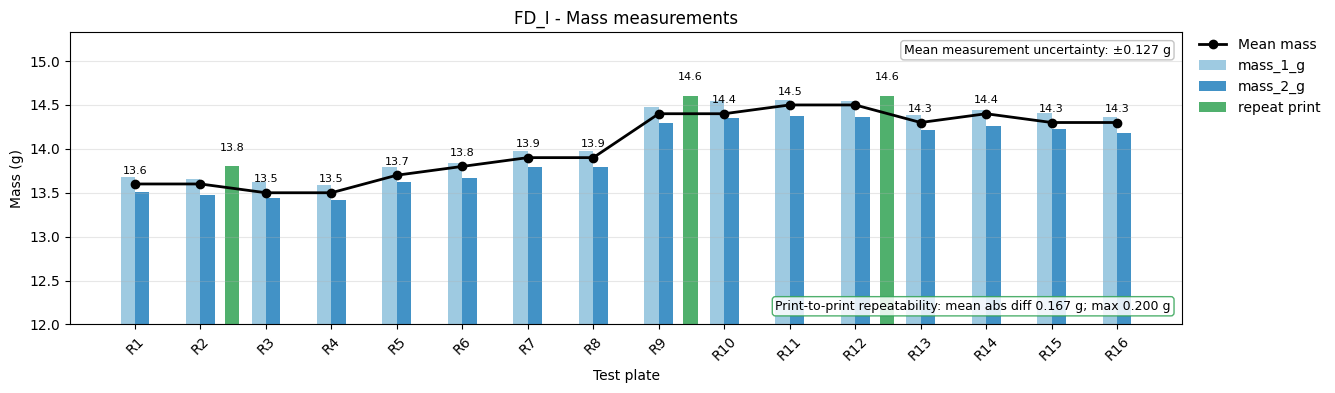

In [8]:
plot_mass_measurements(
    fd_I_mass_measurements_g,
    fd_I_mass_columns,
    y_min=12,
    mean_label="Mean mass",
    experiment="FD_I",
    repeat_measurements_g=fd_I_repeat_mass_measurements_g,
)


#### FD_I Hydrostatic Measurements

These values come from the air/water weighing sheet. Volume is calculated from the buoyancy difference, density is mass divided by volume, and percentage is the relative density compared with the PLA material density.

In [9]:
fd_I_hydrostatic_tables = {}
fd_I_hydrostatic_columns = {}

for response_name, measurements in FD_I_HYDROSTATIC_MEASUREMENTS.items():
    mean_digits = 1 if response_name == "relative_density_percent" else 3
    table, columns = build_response_measurements(
        measurements,
        run_prefix="R",
        response_name=response_name,
        mean_round_digits=mean_digits,
    )
    fd_I_hydrostatic_tables[response_name] = table
    fd_I_hydrostatic_columns[response_name] = columns

fd_I_hydrostatic_summary = fd_I_hydrostatic_tables["weight_in_air_g"][["run"]].copy()
for response_name, table in fd_I_hydrostatic_tables.items():
    fd_I_hydrostatic_summary[f"{response_name}_mean"] = table[f"{response_name}_mean"]
    fd_I_hydrostatic_summary[f"{response_name}_std"] = table[f"{response_name}_std"]

display(fd_I_hydrostatic_summary.round({
    "weight_in_air_g_mean": 3,
    "weight_in_air_g_std": 3,
    "weight_in_water_g_mean": 3,
    "weight_in_water_g_std": 3,
    "volume_cm3_mean": 3,
    "volume_cm3_std": 3,
    "density_g_cm3_mean": 3,
    "density_g_cm3_std": 3,
    "relative_density_percent_mean": 1,
    "relative_density_percent_std": 2,
}))


,run,weight_in_air_g_mean,weight_in_air_g_std,weight_in_water_g_mean,weight_in_water_g_std,volume_cm3_mean,volume_cm3_std,density_g_cm3_mean,density_g_cm3_std,relative_density_percent_mean,relative_density_percent_std
0,R1,13.360,0.014,10.170,0.028,10.190,0.028,1.310,0.000,98.2,0.4
1,R2,13.340,0.014,10.175,0.021,10.195,0.021,1.310,0.000,98.0,0.4
2,R3,13.305,0.007,10.140,0.000,10.160,0.000,1.310,0.000,98.2,0.1
3,R4,13.255,0.035,10.150,0.000,10.170,0.000,1.305,0.007,97.7,0.3
4,R5,13.470,0.014,10.365,0.007,10.385,0.007,1.300,0.000,97.2,0.0
5,R6,13.510,0.028,10.350,0.014,10.370,0.014,1.305,0.007,97.6,0.4
6,R7,13.655,0.007,10.320,0.000,10.340,0.000,1.320,0.000,99.0,0.1
7,R8,13.635,0.021,10.325,0.021,10.345,0.021,1.315,0.007,98.8,0.4
8,R9,14.135,0.021,10.640,0.000,10.660,0.000,1.325,0.007,99.4,0.1
9,R10,14.190,0.014,10.605,0.106,10.625,0.106,1.335,0.007,100.1,0.9


#### FD_I Hydrostatic Volume and Density Plots

These plots use the same repeated air/water measurements as the table above. They are shown separately from mass because volume and density answer different questions: volume shows specimen geometry, while density shows compactness of the printed material.


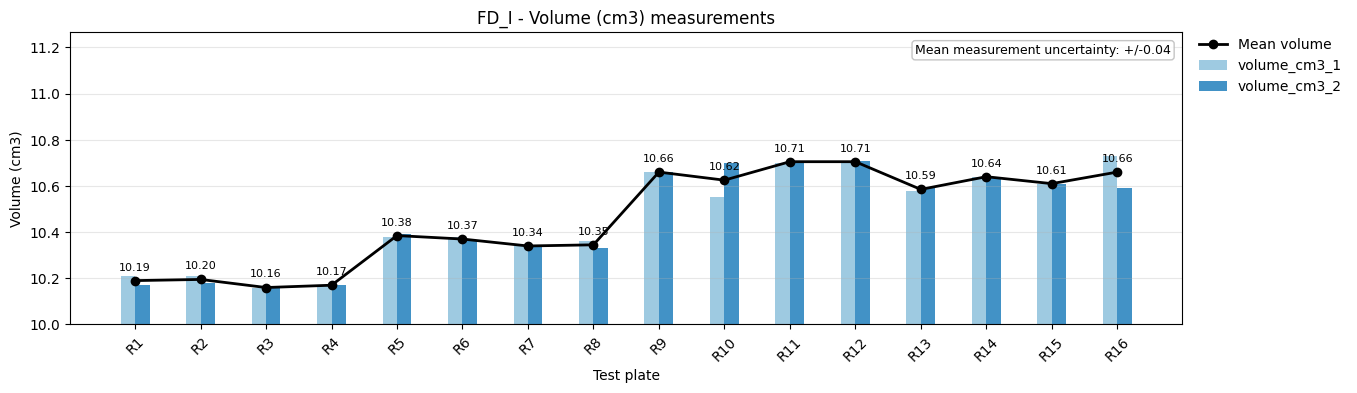

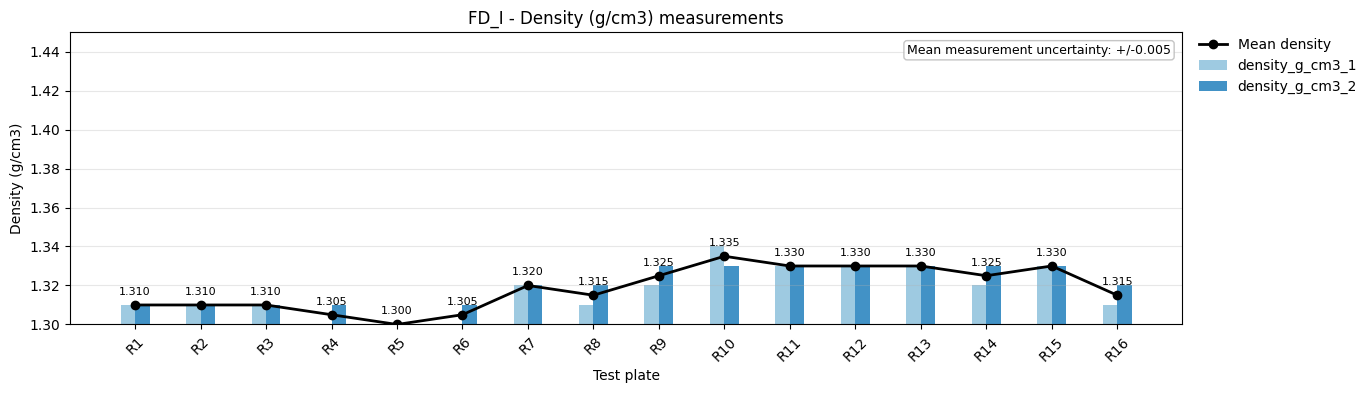

In [10]:
plot_response_measurements(
    fd_I_hydrostatic_tables["volume_cm3"],
    fd_I_hydrostatic_columns["volume_cm3"],
    response_name="volume_cm3",
    y_label="Volume (cm3)",
    y_min=10,
    mean_label="Mean volume",
    experiment="FD_I",
    value_digits=2,
)

plot_response_measurements(
    fd_I_hydrostatic_tables["density_g_cm3"],
    fd_I_hydrostatic_columns["density_g_cm3"],
    response_name="density_g_cm3",
    y_label="Density (g/cm3)",
    y_min=1.25,
    y_max=1.40,
    mean_label="Mean density",
    experiment="FD_I",
    value_digits=3,
)


#### FD_I Weight, Volume, and Density Correlations

These scatter plots check whether the measured responses move together. 
The first three plots use the precision-scale `mass_mean_g` together with the hydrostatic volume and density values. 
The final plot compares the precision-scale mass with the average `weight_in_air_g` used for the Archimedes density calculation.

The Pearson correlation `r` describes linear correlation: values close to +1 increase together, values close to -1 move in opposite directions, and values close to 0 show little linear correlation.


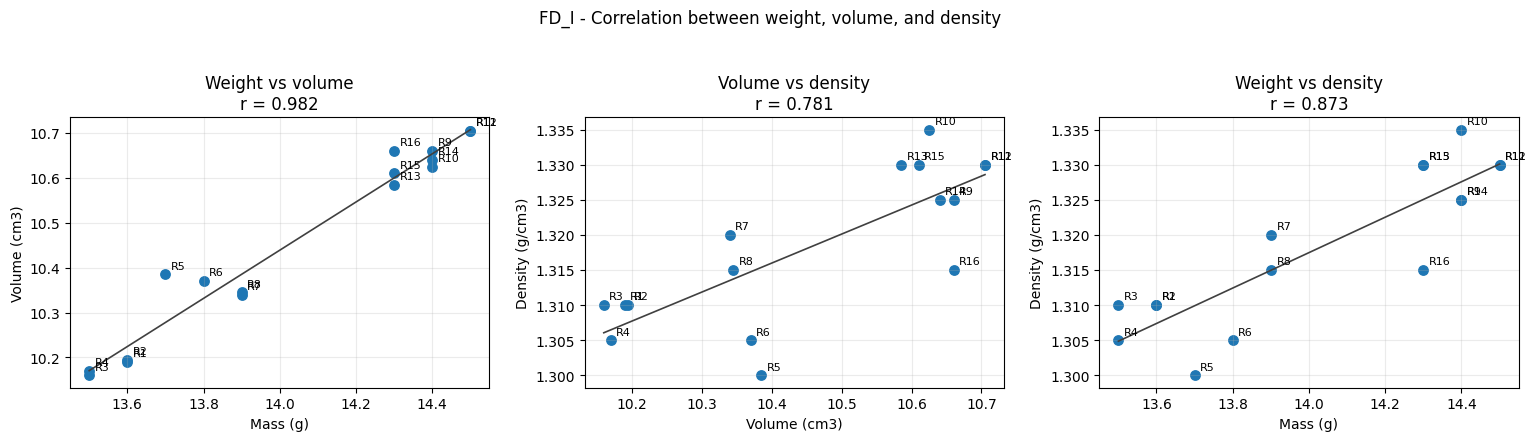

,run,mass_mean_g,volume_cm3_mean,density_g_cm3_mean,archimedes_weight_in_air_g
0,R1,13.6,10.190,1.310,13.360
1,R2,13.6,10.195,1.310,13.340
2,R3,13.5,10.160,1.310,13.305
3,R4,13.5,10.170,1.305,13.255
4,R5,13.7,10.385,1.300,13.470
5,R6,13.8,10.370,1.305,13.510
6,R7,13.9,10.340,1.320,13.655
7,R8,13.9,10.345,1.315,13.635
8,R9,14.4,10.660,1.325,14.135
9,R10,14.4,10.625,1.335,14.190


,comparison,n,pearson_r
0,Weight vs volume,16,0.982
1,Volume vs density,16,0.781
2,Weight vs density,16,0.873


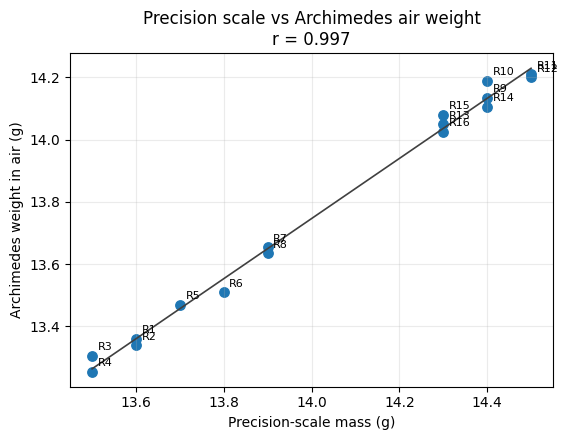

,run,mass_mean_g,archimedes_weight_in_air_g
0,R1,13.6,13.360
1,R2,13.6,13.340
2,R3,13.5,13.305
3,R4,13.5,13.255
4,R5,13.7,13.470
5,R6,13.8,13.510
6,R7,13.9,13.655
7,R8,13.9,13.635
8,R9,14.4,14.135
9,R10,14.4,14.190


,comparison,n,pearson_r
0,Precision-scale mass vs Archimedes air weight,16,0.997


Rank change compares heaviest-to-lightest order. 0 means the plate has the same rank in both measurements; positive means it ranks lighter in the Archimedes air-weight order; negative means it ranks heavier.


,run,mass_mean_g,archimedes_weight_in_air_g,precision_rank_heavy_to_light,archimedes_rank_heavy_to_light,rank_change,same_order_position
1,R2,13.6,13.340,13,14,1,False
3,R4,13.5,13.255,15,16,1,False
7,R8,13.9,13.635,9,10,1,False
8,R9,14.4,14.135,3,4,1,False
11,R12,14.5,14.200,1,2,1,False
12,R13,14.3,14.050,6,7,1,False
13,R14,14.4,14.105,3,5,2,False
15,R16,14.3,14.025,6,8,2,False
0,R1,13.6,13.360,13,13,0,True
2,R3,13.5,13.305,15,15,0,True


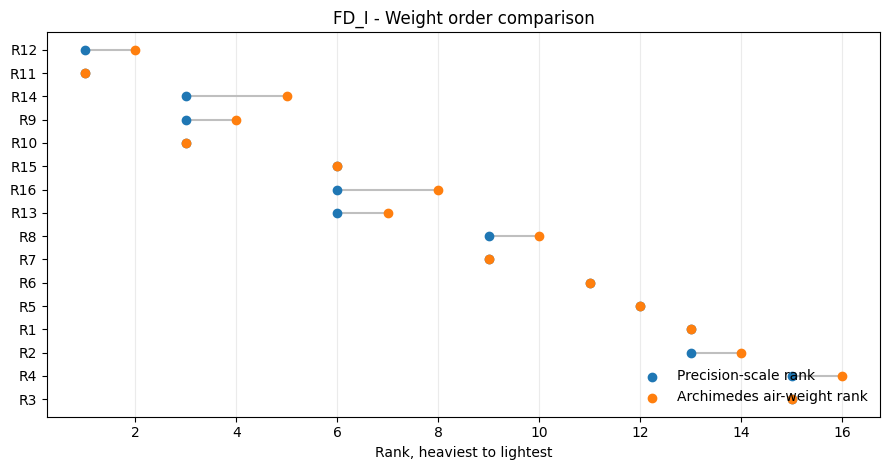

In [11]:
import matplotlib.pyplot as plt
import numpy as np

fd_I_correlation_data = (
    fd_I_mass_measurements_g[["run", "mass_mean_g"]]
    .merge(
        fd_I_hydrostatic_tables["volume_cm3"][["run", "volume_cm3_mean"]],
        on="run",
        how="inner",
    )
    .merge(
        fd_I_hydrostatic_tables["density_g_cm3"][["run", "density_g_cm3_mean"]],
        on="run",
        how="inner",
    )
    .merge(
        fd_I_hydrostatic_tables["weight_in_air_g"][["run", "weight_in_air_g_mean"]],
        on="run",
        how="inner",
    )
    .rename(columns={"weight_in_air_g_mean": "archimedes_weight_in_air_g"})
)

correlation_pairs = [
    ("mass_mean_g", "volume_cm3_mean", "Mass (g)", "Volume (cm3)", "Weight vs volume"),
    ("volume_cm3_mean", "density_g_cm3_mean", "Volume (cm3)", "Density (g/cm3)", "Volume vs density"),
    ("mass_mean_g", "density_g_cm3_mean", "Mass (g)", "Density (g/cm3)", "Weight vs density"),
]

fd_I_correlation_summary = []
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
for ax, (x_col, y_col, x_label, y_label, title) in zip(axes, correlation_pairs):
    plot_df = fd_I_correlation_data[["run", x_col, y_col]].dropna()
    r_value = plot_df[x_col].corr(plot_df[y_col])
    fd_I_correlation_summary.append({
        "comparison": title,
        "n": len(plot_df),
        "pearson_r": r_value,
    })

    ax.scatter(plot_df[x_col], plot_df[y_col], color="#1f77b4", s=46)
    for _, row in plot_df.iterrows():
        ax.annotate(
            row["run"],
            (row[x_col], row[y_col]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

    if len(plot_df) >= 2:
        slope, intercept = np.polyfit(plot_df[x_col], plot_df[y_col], 1)
        x_line = np.linspace(plot_df[x_col].min(), plot_df[x_col].max(), 100)
        ax.plot(x_line, slope * x_line + intercept, color="0.25", linewidth=1.2)

    ax.set_title(f"{title}\nr = {r_value:.3f}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.25)

fig.suptitle("FD_I - Correlation between weight, volume, and density", y=1.04)
plt.tight_layout()
plt.show(block=False)

display(fd_I_correlation_data.round({
    "mass_mean_g": 3,
    "volume_cm3_mean": 3,
    "density_g_cm3_mean": 3,
}))
display(pd.DataFrame(fd_I_correlation_summary).round({"pearson_r": 3}))


archimedes_precision_df = fd_I_correlation_data[[
    "run",
    "mass_mean_g",
    "archimedes_weight_in_air_g",
]].dropna()
archimedes_precision_r = archimedes_precision_df["mass_mean_g"].corr(
    archimedes_precision_df["archimedes_weight_in_air_g"]
)

fig, ax = plt.subplots(figsize=(5.8, 4.5))
ax.scatter(
    archimedes_precision_df["mass_mean_g"],
    archimedes_precision_df["archimedes_weight_in_air_g"],
    color="#1f77b4",
    s=46,
)
for _, row in archimedes_precision_df.iterrows():
    ax.annotate(
        row["run"],
        (row["mass_mean_g"], row["archimedes_weight_in_air_g"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
    )
if len(archimedes_precision_df) >= 2:
    slope, intercept = np.polyfit(
        archimedes_precision_df["mass_mean_g"],
        archimedes_precision_df["archimedes_weight_in_air_g"],
        1,
    )
    x_line = np.linspace(
        archimedes_precision_df["mass_mean_g"].min(),
        archimedes_precision_df["mass_mean_g"].max(),
        100,
    )
    ax.plot(x_line, slope * x_line + intercept, color="0.25", linewidth=1.2)
ax.set_title(f"Precision scale vs Archimedes air weight\nr = {archimedes_precision_r:.3f}")
ax.set_xlabel("Precision-scale mass (g)")
ax.set_ylabel("Archimedes weight in air (g)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show(block=False)

display(archimedes_precision_df.round({
    "mass_mean_g": 3,
    "archimedes_weight_in_air_g": 3,
}))
display(pd.DataFrame([{
    "comparison": "Precision-scale mass vs Archimedes air weight",
    "n": len(archimedes_precision_df),
    "pearson_r": archimedes_precision_r,
}]).round({"pearson_r": 3}))


fd_I_weight_rank_comparison = archimedes_precision_df.copy()
fd_I_weight_rank_comparison["precision_rank_heavy_to_light"] = (
    fd_I_weight_rank_comparison["mass_mean_g"]
    .rank(method="min", ascending=False)
    .astype(int)
)
fd_I_weight_rank_comparison["archimedes_rank_heavy_to_light"] = (
    fd_I_weight_rank_comparison["archimedes_weight_in_air_g"]
    .rank(method="min", ascending=False)
    .astype(int)
)
fd_I_weight_rank_comparison["rank_change"] = (
    fd_I_weight_rank_comparison["archimedes_rank_heavy_to_light"]
    - fd_I_weight_rank_comparison["precision_rank_heavy_to_light"]
)
fd_I_weight_rank_comparison["same_order_position"] = (
    fd_I_weight_rank_comparison["rank_change"] == 0
)
fd_I_weight_rank_comparison = fd_I_weight_rank_comparison.sort_values(
    ["same_order_position", "rank_change"],
    ascending=[True, True],
)

print(
    "Rank change compares heaviest-to-lightest order. "
    "0 means the plate has the same rank in both measurements; "
    "positive means it ranks lighter in the Archimedes air-weight order; "
    "negative means it ranks heavier."
)
display(fd_I_weight_rank_comparison[[
    "run",
    "mass_mean_g",
    "archimedes_weight_in_air_g",
    "precision_rank_heavy_to_light",
    "archimedes_rank_heavy_to_light",
    "rank_change",
    "same_order_position",
]].round({
    "mass_mean_g": 3,
    "archimedes_weight_in_air_g": 3,
}))

rank_plot_df = fd_I_weight_rank_comparison.sort_values("precision_rank_heavy_to_light")
fig, ax = plt.subplots(figsize=(9, 4.8))
y_positions = np.arange(len(rank_plot_df))
ax.hlines(
    y_positions,
    rank_plot_df["precision_rank_heavy_to_light"],
    rank_plot_df["archimedes_rank_heavy_to_light"],
    color="0.75",
    linewidth=1.5,
)
ax.scatter(
    rank_plot_df["precision_rank_heavy_to_light"],
    y_positions,
    color="#1f77b4",
    label="Precision-scale rank",
    zorder=3,
)
ax.scatter(
    rank_plot_df["archimedes_rank_heavy_to_light"],
    y_positions,
    color="#ff7f0e",
    label="Archimedes air-weight rank",
    zorder=3,
)
ax.set_yticks(y_positions)
ax.set_yticklabels(rank_plot_df["run"])
ax.invert_yaxis()
ax.set_xlabel("Rank, heaviest to lightest")
ax.set_title("FD_I - Weight order comparison")
ax.grid(axis="x", alpha=0.25)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show(block=False)


#### FD_I Old-Scale Mass Measurements

This comparison uses the archived old-scale FD_I measurements. The same mass helper is used here: if four measurements are available it drops the lowest and highest values and averages the middle two; with the two archived FD_I measurements it averages both values.

,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,R1,12.907,13.272,13.1,0.258094
1,R2,13.334,13.296,13.3,0.026870
2,R3,13.294,13.286,13.3,0.005657
3,R4,13.259,13.240,13.2,0.013435
4,R5,13.454,13.432,13.4,0.015556
5,R6,13.490,13.448,13.5,0.029698
6,R7,13.622,13.492,13.6,0.091924
7,R8,13.637,13.595,13.6,0.029698
8,R9,14.136,14.126,14.1,0.007071
9,R10,14.188,14.173,14.2,0.010607


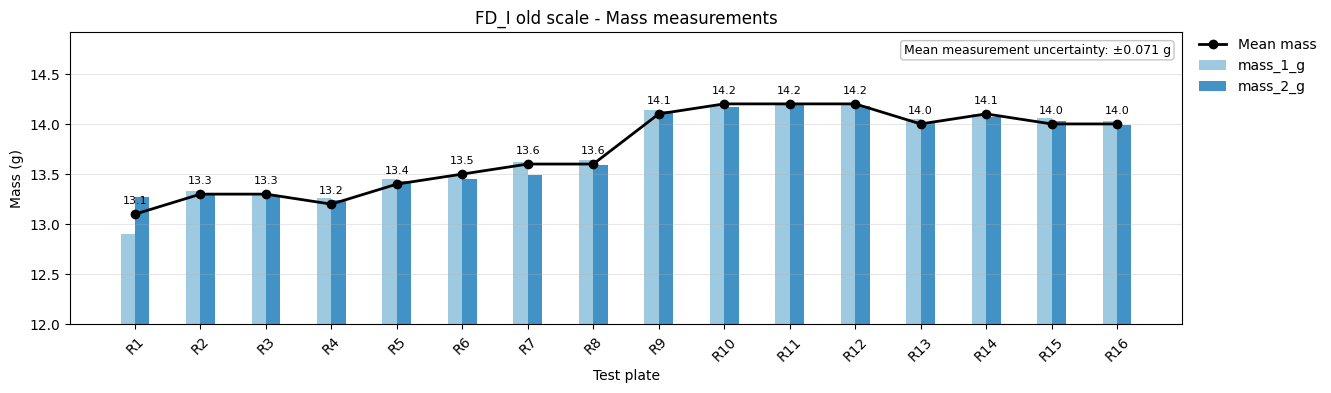

In [12]:
fd_I_old_scale_mass_measurements_g, fd_I_old_scale_mass_columns = build_mass_measurements(
    FD_I_OLD_SCALE_MASS_MEASUREMENTS_G,
    run_prefix="R",
)
display(fd_I_old_scale_mass_measurements_g[[
    "run",
    *fd_I_old_scale_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

plot_mass_measurements(
    fd_I_old_scale_mass_measurements_g,
    fd_I_old_scale_mass_columns,
    y_min=12,
    mean_label="Mean mass",
    experiment="FD_I old scale",
)


#### FD_I Repeatability From Repeated Prints


In [13]:
fd_I_repeatability = calculate_repeatability(
    fd_I_mass_measurements_g,
    fd_I_repeat_mass_measurements_g,
)

display(fd_I_repeatability)
print(
    "Mean absolute repeat difference:",
    f"{fd_I_repeatability['abs_difference_g'].mean():.3f} g",
)


,run_repeat,original_run,original_mass_mean_g,repeat_mass_mean_g,repeat_print_count,difference_g,abs_difference_g,difference_percent
0,R12 repeat print,R12,14.5,14.6,1,0.1,0.1,0.69
1,R2 repeat print,R2,13.6,13.8,1,0.2,0.2,1.47
2,R9 repeat print,R9,14.4,14.6,1,0.2,0.2,1.39


Mean absolute repeat difference: 0.167 g


## 3) Analysis


### FD_I Screening Analysis


#### FD_I Main-Effect Estimates


In [15]:
main_effect_df_I = compute_main_effects(mass_result_matrix_I)
main_effect_df_I


,Effect,Main effect
0,A_flow_ratio,7.000000e-01
1,B_nozzle_temp,7.500000e-02
2,C_speed,2.500000e-02
3,D_line_width,2.500000e-02
4,E_layer_height,-2.000000e-01
5,F_walls,1.776357e-15


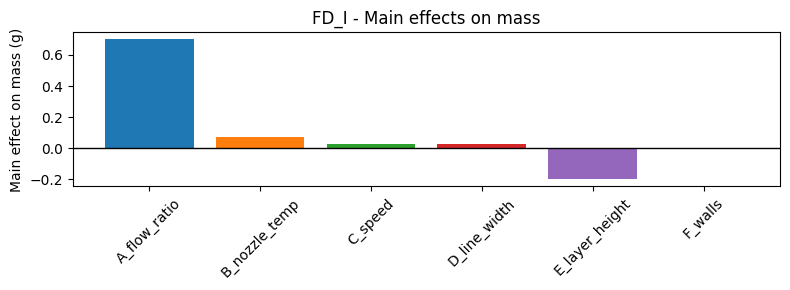

In [16]:
plot_main_effects_bar(
    main_effect_df_I,
    response="mass_mean_g",
    experiment="FD_I",
)


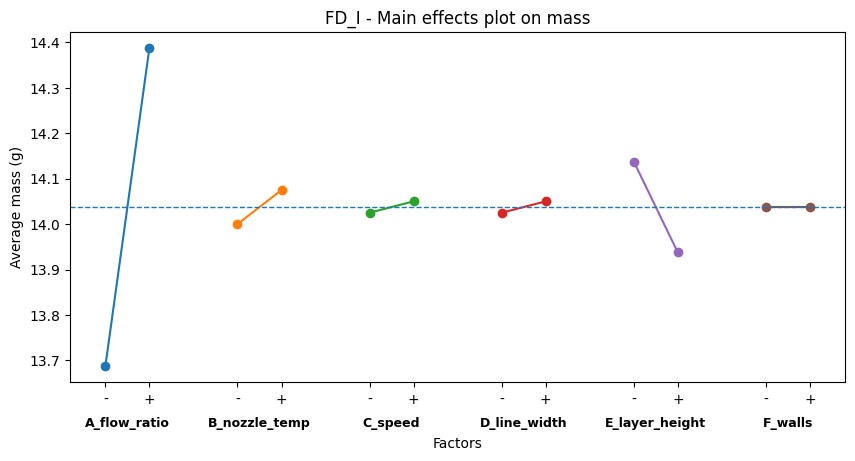

In [17]:
plot_main_effects_line(
    mass_result_matrix_I,
    response="mass_mean_g",
    experiment="FD_I",
)


#### FD_I Regression Main-Effects Plot


This regression-style FD_I analysis fits one main-effects model for each response: mass, hydrostatic volume, and bulk density. 
For the balanced FD_I matrix, the fitted low/high trends match the ordinary main-effect estimates, but the regression model also gives coefficient standard errors, t values, p values, ANOVA tables, and alpha-threshold Pareto charts.


#### Regression term significance and repeatability

The Pareto chart shows which effects are large compared with the estimated uncertainty. Terms above the alpha = 0.10 threshold are considered potentially statistically relevant for this screening experiment. Terms below the threshold should not be interpreted as statistically confirmed, but they may still be practically relevant if they affect print quality.

Repeated scale readings such as `mass_1_g` and `mass_2_g` are measurement repeats of the same printed specimen, so they estimate measurement uncertainty, not independent print-to-print error. Actual repeated prints with identical settings are used for replicate-based pure error. For hydrostatic volume and density, the current repeated readings provide a measurement-based threshold; a true replicate-based threshold would require repeated hydrostatic measurements on repeated prints at the same settings.

The solid threshold uses the regression residual degrees of freedom. A dashed threshold uses print-replicate pure-error degrees of freedom when available. A dotted threshold uses repeated-measurement degrees of freedom when repeated readings are available for that response.


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,16,7,7,True,9,0.9772,0.0745


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
1,A_flow_ratio=-1|B_nozzle_temp=-1|C_speed=-1|D_...,2,13.70,0.020,1
8,A_flow_ratio=1|B_nozzle_temp=-1|C_speed=-1|D_l...,2,14.50,0.020,1
11,A_flow_ratio=1|B_nozzle_temp=-1|C_speed=1|D_li...,2,14.55,0.005,1


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,3,6,0.045,3,0.015,0.1225


,error_basis,SS,df,MSE,s
0,regression residual,0.050,9.0,0.0056,0.0745
1,replicate pure error,0.045,3.0,0.0150,0.1225


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,6,2.1475,0.3579,64.425,0.0
1,Residual,9,0.0500,0.0056,NaN,NaN
2,Total,15,2.1975,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.3500,0.0186,18.7830,352.80,0.0000,0.0306,11.4310,130.6667,0.0014,NaN,NaN,NaN,NaN
2,B_nozzle_temp,0.0375,0.0186,2.0125,4.05,0.0750,0.0306,1.2247,1.5000,0.3081,NaN,NaN,NaN,NaN
3,C_speed,0.0125,0.0186,0.6708,0.45,0.5192,0.0306,0.4082,0.1667,0.7105,NaN,NaN,NaN,NaN
4,D_line_width,0.0125,0.0186,0.6708,0.45,0.5192,0.0306,0.4082,0.1667,0.7105,NaN,NaN,NaN,NaN
5,E_layer_height,-0.1000,0.0186,-5.3666,28.80,0.0005,0.0306,-3.2660,10.6667,0.0469,NaN,NaN,NaN,NaN
6,F_walls,0.0000,0.0186,0.0000,0.00,1.0000,0.0306,0.0000,0.0000,1.0000,NaN,NaN,NaN,NaN


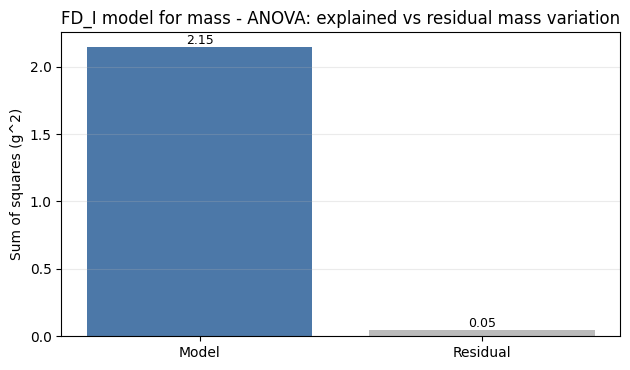

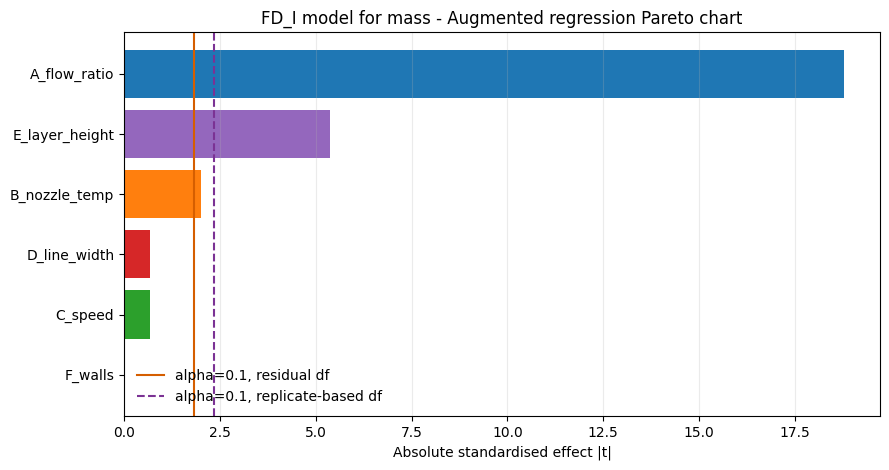

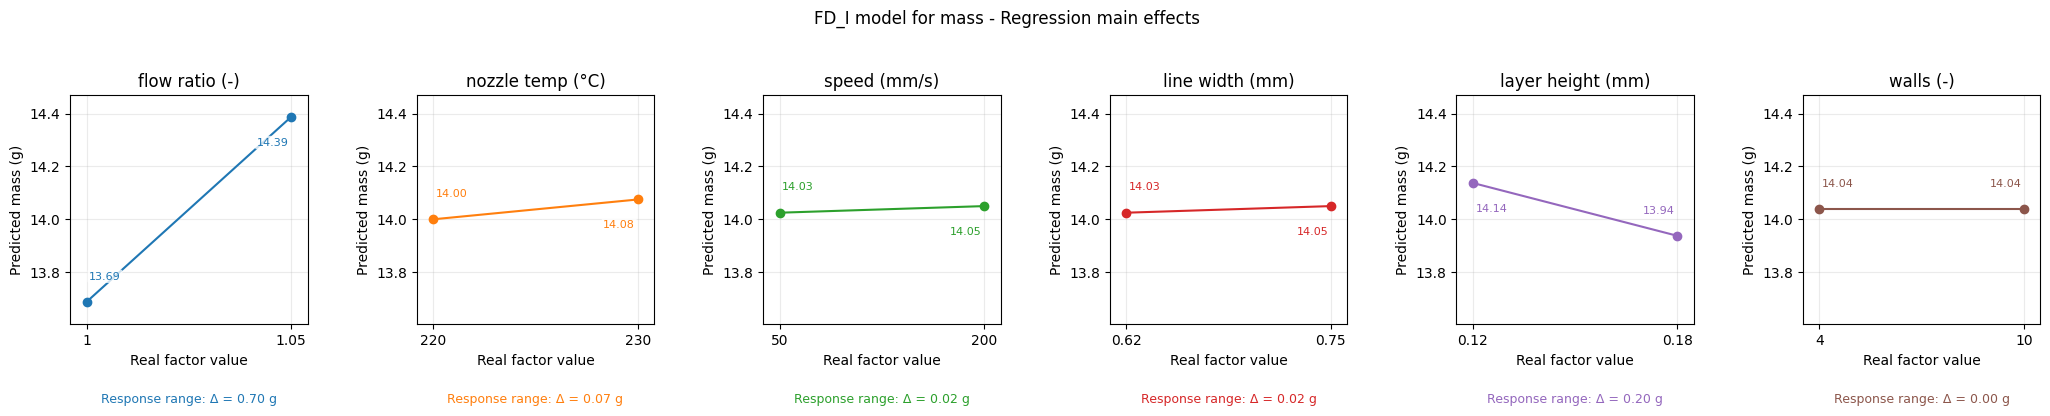

,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,6,0.6523,0.1087,242.2549,0.0
1,Residual,9,0.0040,0.0004,NaN,NaN
2,Total,15,0.6564,NaN,NaN,NaN


,run,n_group,group_mean,SS_measurement_group,df_measurement_group
0,R1,2,10.190,0.0008,1
1,R10,2,10.625,0.0112,1
2,R11,2,10.705,0.0001,1
3,R12,2,10.705,0.0001,1
4,R13,2,10.585,0.0000,1
5,R14,2,10.640,0.0000,1
6,R15,2,10.610,0.0000,1
7,R16,2,10.660,0.0098,1
8,R2,2,10.195,0.0005,1
9,R3,2,10.160,0.0000,1


,measurement_groups,measurement_observations,SS_measurement,df_measurement,MSE_measurement,s_measurement
0,16,32,0.0231,16,0.0014,0.038


,error_basis,SS,df,MSE,s
0,regression residual,0.0040,9.0,0.0004,0.0212
1,measurement repeatability,0.0231,16.0,0.0014,0.0380


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.1897,0.0053,35.8162,1282.8012,0.0000,NaN,NaN,NaN,NaN,0.0095,19.9473,397.8931,0.0000
2,B_nozzle_temp,0.0328,0.0053,6.1956,38.3849,0.0002,NaN,NaN,NaN,NaN,0.0095,3.4505,11.9060,0.0033
3,C_speed,0.0028,0.0053,0.5310,0.2820,0.6082,NaN,NaN,NaN,NaN,0.0095,0.2958,0.0875,0.7712
4,D_line_width,0.0047,0.0053,0.8851,0.7834,0.3991,NaN,NaN,NaN,NaN,0.0095,0.4929,0.2430,0.6288
5,E_layer_height,-0.0578,0.0053,-10.9160,119.1586,0.0000,NaN,NaN,NaN,NaN,0.0095,-6.0795,36.9600,0.0000
6,F_walls,0.0184,0.0053,3.4813,12.1195,0.0069,NaN,NaN,NaN,NaN,0.0095,1.9389,3.7592,0.0704


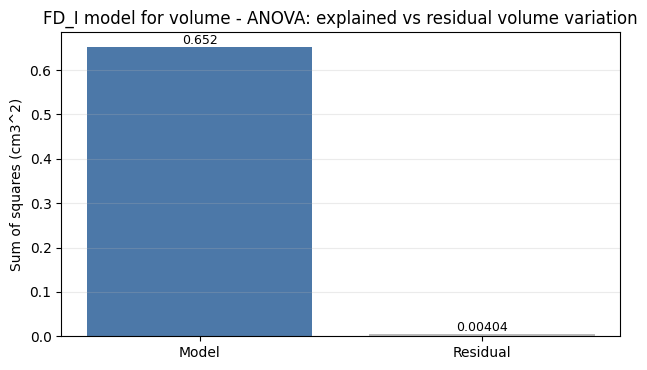

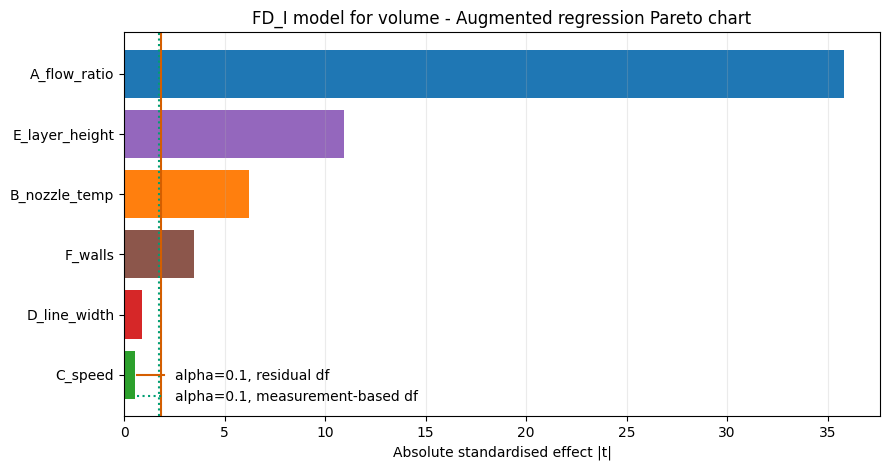

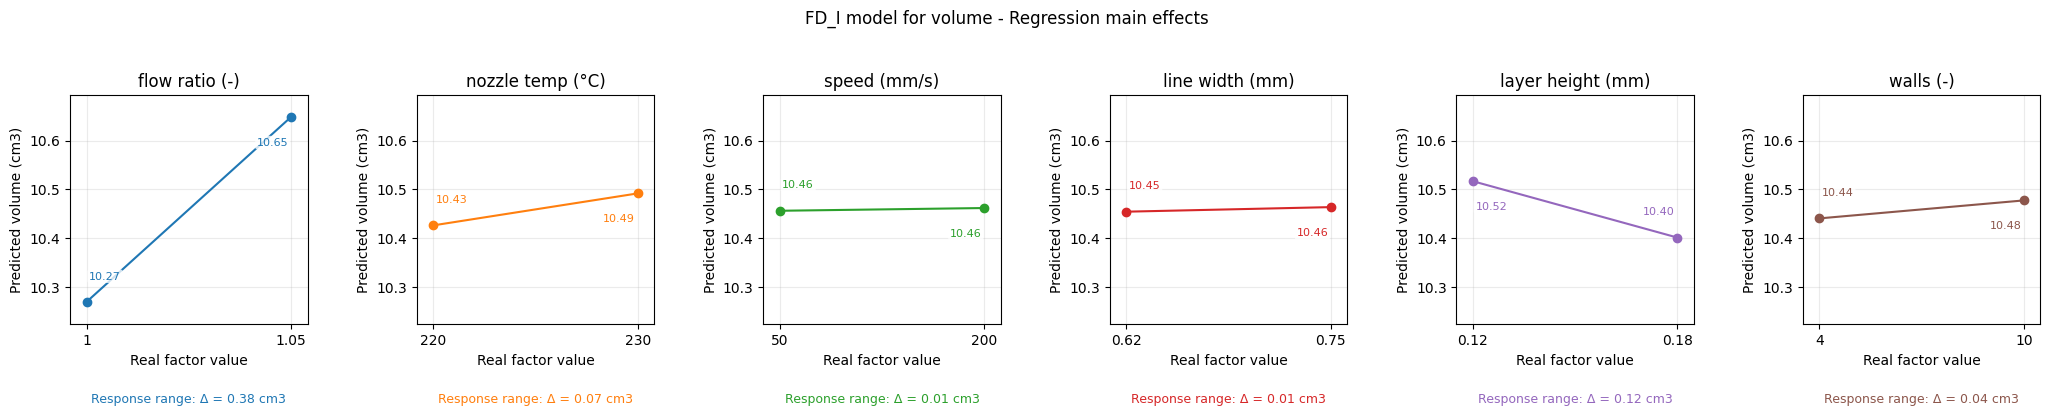

,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,6,0.0015,0.0002,6.0644,0.0086
1,Residual,9,0.0004,0.0000,NaN,NaN
2,Total,15,0.0018,NaN,NaN,NaN


,run,n_group,group_mean,SS_measurement_group,df_measurement_group
0,R1,2,1.310,0.0000,1
1,R10,2,1.335,0.0001,1
2,R11,2,1.330,0.0000,1
3,R12,2,1.330,0.0000,1
4,R13,2,1.330,0.0000,1
5,R14,2,1.325,0.0001,1
6,R15,2,1.330,0.0000,1
7,R16,2,1.315,0.0001,1
8,R2,2,1.310,0.0000,1
9,R3,2,1.310,0.0000,1


,measurement_groups,measurement_observations,SS_measurement,df_measurement,MSE_measurement,s_measurement
0,16,32,0.0004,16,0.0,0.0047


,error_basis,SS,df,MSE,s
0,regression residual,0.0004,9.0,0.0,0.0064
1,measurement repeatability,0.0004,16.0,0.0,0.0047


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.0091,0.0016,5.6996,32.4850,0.0003,NaN,NaN,NaN,NaN,0.0012,7.7506,60.0714,0.0000
2,B_nozzle_temp,-0.0009,0.0016,-0.5896,0.3476,0.5700,NaN,NaN,NaN,NaN,0.0012,-0.8018,0.6429,0.4344
3,C_speed,0.0009,0.0016,0.5896,0.3476,0.5700,NaN,NaN,NaN,NaN,0.0012,0.8018,0.6429,0.4344
4,D_line_width,-0.0009,0.0016,-0.5896,0.3476,0.5700,NaN,NaN,NaN,NaN,0.0012,-0.8018,0.6429,0.4344
5,E_layer_height,-0.0016,0.0016,-0.9827,0.9657,0.3514,NaN,NaN,NaN,NaN,0.0012,-1.3363,1.7857,0.2001
6,F_walls,-0.0022,0.0016,-1.3758,1.8927,0.2022,NaN,NaN,NaN,NaN,0.0012,-1.8708,3.5000,0.0798


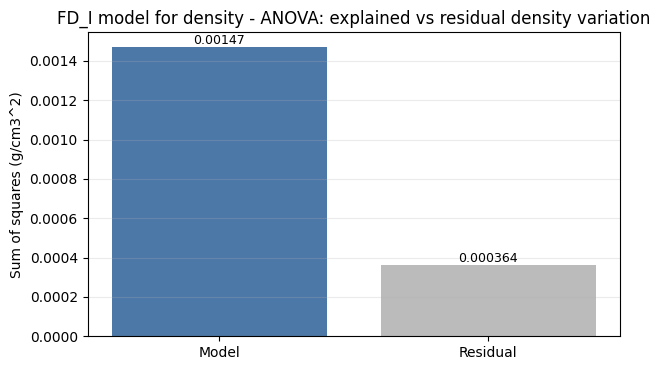

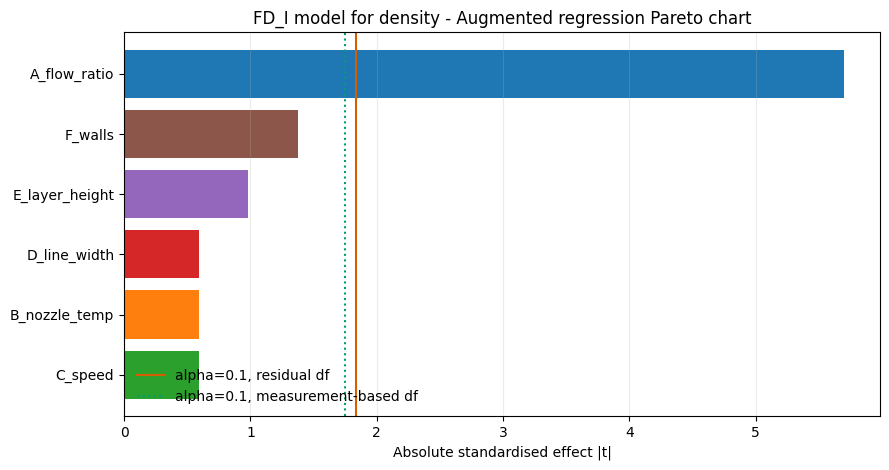

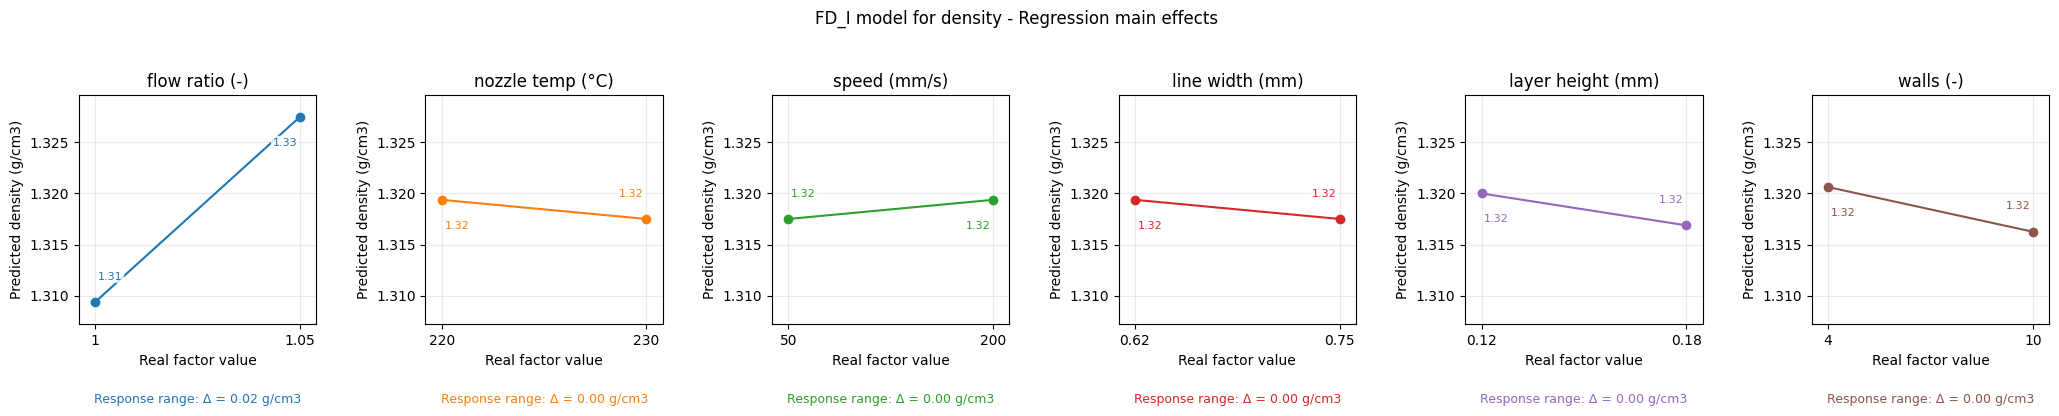

In [18]:
FD_I_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
    "F_walls",
]

FD_I_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
    "F_walls": ("A_flow_ratio", "C_speed"),  # F = AC
}

if "fd_I_hydrostatic_result_matrices" not in globals():
    fd_I_hydrostatic_result_matrices = {}
    for response_name in ["volume_cm3", "density_g_cm3"]:
        response_col = f"{response_name}_mean"
        fd_I_hydrostatic_result_matrices[response_name] = build_result_matrix(
            fd_I_coded_df,
            fd_I_hydrostatic_tables[response_name][["run", response_col]],
            response=response_col,
        )

fd_I_mass_regression_model = fit_main_effect_screening_model(
    mass_result_matrix_I,
    response="mass_mean_g",
    factor_cols=FD_I_FACTOR_COLUMNS,
)

display(fd_I_mass_regression_model["info_df"].round(4))
fd_I_mass_replicate_observations, fd_I_mass_pure_error_groups, fd_I_mass_pure_error_summary = (
    calculate_pure_error_from_replicates(
        mass_result_matrix_I,
        response="mass_mean_g",
        factor_cols=FD_I_FACTOR_COLUMNS,
        repeat_measurements_g=fd_I_repeat_mass_measurements_g,
    )
)
display(fd_I_mass_pure_error_groups.round(4))
display(fd_I_mass_pure_error_summary.round(4))
display(build_error_comparison_table(
    fd_I_mass_regression_model,
    fd_I_mass_pure_error_summary,
).round(4))
fd_I_mass_anova_table = build_model_anova_table(fd_I_mass_regression_model)
display(fd_I_mass_anova_table.round(4))
display(
    build_term_significance_table(
        fd_I_mass_regression_model,
        pure_error_summary=fd_I_mass_pure_error_summary,
    ).round(4)
)
plot_model_anova(
    fd_I_mass_anova_table,
    response="mass_mean_g",
    experiment="FD_I model for mass",
)
plot_augmented_model_pareto(
    fd_I_mass_regression_model,
    experiment="FD_I model for mass",
    pure_error_summary=fd_I_mass_pure_error_summary,
)
plot_augmented_main_effects(
    fd_I_mass_regression_model,
    FD_I_LEVELS,
    experiment="FD_I model for mass",
    plot_label="Regression main effects",
)

fd_I_volume_result_matrix = fd_I_hydrostatic_result_matrices["volume_cm3"]
fd_I_density_result_matrix = fd_I_hydrostatic_result_matrices["density_g_cm3"]
FD_I_VOLUME_RESPONSE = "volume_cm3_mean"
FD_I_DENSITY_RESPONSE = "density_g_cm3_mean"

fd_I_volume_regression_model = fit_main_effect_screening_model(
    fd_I_volume_result_matrix,
    response=FD_I_VOLUME_RESPONSE,
    factor_cols=FD_I_FACTOR_COLUMNS,
)

fd_I_density_regression_model = fit_main_effect_screening_model(
    fd_I_density_result_matrix,
    response=FD_I_DENSITY_RESPONSE,
    factor_cols=FD_I_FACTOR_COLUMNS,
)

fd_I_volume_measurement_observations, fd_I_volume_measurement_groups, fd_I_volume_measurement_summary = (
    calculate_measurement_error_from_repeated_columns(
        fd_I_hydrostatic_tables["volume_cm3"],
        fd_I_hydrostatic_columns["volume_cm3"],
        FD_I_VOLUME_RESPONSE,
    )
)
fd_I_density_measurement_observations, fd_I_density_measurement_groups, fd_I_density_measurement_summary = (
    calculate_measurement_error_from_repeated_columns(
        fd_I_hydrostatic_tables["density_g_cm3"],
        fd_I_hydrostatic_columns["density_g_cm3"],
        FD_I_DENSITY_RESPONSE,
    )
)

fd_I_volume_anova_table = build_model_anova_table(fd_I_volume_regression_model)
display(fd_I_volume_anova_table.round(4))
display(fd_I_volume_measurement_groups.round(4))
display(fd_I_volume_measurement_summary.round(4))
display(build_error_comparison_table(
    fd_I_volume_regression_model,
    measurement_error_summary=fd_I_volume_measurement_summary,
).round(4))
display(build_term_significance_table(
    fd_I_volume_regression_model,
    measurement_error_summary=fd_I_volume_measurement_summary,
).round(4))
plot_model_anova(
    fd_I_volume_anova_table,
    response=FD_I_VOLUME_RESPONSE,
    experiment="FD_I model for volume",
)
plot_augmented_model_pareto(
    fd_I_volume_regression_model,
    experiment="FD_I model for volume",
    measurement_error_summary=fd_I_volume_measurement_summary,
)

plot_augmented_main_effects(
    fd_I_volume_regression_model,
    FD_I_LEVELS,
    experiment="FD_I model for volume",
    plot_label="Regression main effects",
)

fd_I_density_anova_table = build_model_anova_table(fd_I_density_regression_model)
display(fd_I_density_anova_table.round(4))
display(fd_I_density_measurement_groups.round(4))
display(fd_I_density_measurement_summary.round(4))
display(build_error_comparison_table(
    fd_I_density_regression_model,
    measurement_error_summary=fd_I_density_measurement_summary,
).round(4))
display(build_term_significance_table(
    fd_I_density_regression_model,
    measurement_error_summary=fd_I_density_measurement_summary,
).round(4))
plot_model_anova(
    fd_I_density_anova_table,
    response=FD_I_DENSITY_RESPONSE,
    experiment="FD_I model for density",
)
plot_augmented_model_pareto(
    fd_I_density_regression_model,
    experiment="FD_I model for density",
    measurement_error_summary=fd_I_density_measurement_summary,
)

plot_augmented_main_effects(
    fd_I_density_regression_model,
    FD_I_LEVELS,
    experiment="FD_I model for density",
    plot_label="Regression main effects",
)


#### FD_I Aliased Interaction Estimates


In [19]:
mass_interaction_matrix = add_interactions(mass_result_matrix_I)

#mass_interaction_matrix


In [20]:
FD_I_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
    "F_walls": ("A_flow_ratio", "C_speed"),  # F = AC
}

interaction_effects_I = compute_interaction_effects(
    mass_result_matrix_I,
    response="mass_mean_g",
    generators=FD_I_GENERATORS,
)

interaction_effects_I


,Interaction,Alias / generator note,Effect
7,B_nozzle_temp x E_layer_height,,7.000000e-01
11,C_speed x F_walls,,7.000000e-01
0,A_flow_ratio x B_nozzle_temp,E_layer_height; generator E=AB,-2.000000e-01
8,B_nozzle_temp x F_walls,,-1.000000e-01
10,C_speed x E_layer_height,,-1.000000e-01
3,A_flow_ratio x E_layer_height,,7.500000e-02
4,A_flow_ratio x F_walls,,2.500000e-02
9,C_speed x D_line_width,,-2.500000e-02
14,E_layer_height x F_walls,,2.500000e-02
6,B_nozzle_temp x D_line_width,,2.500000e-02


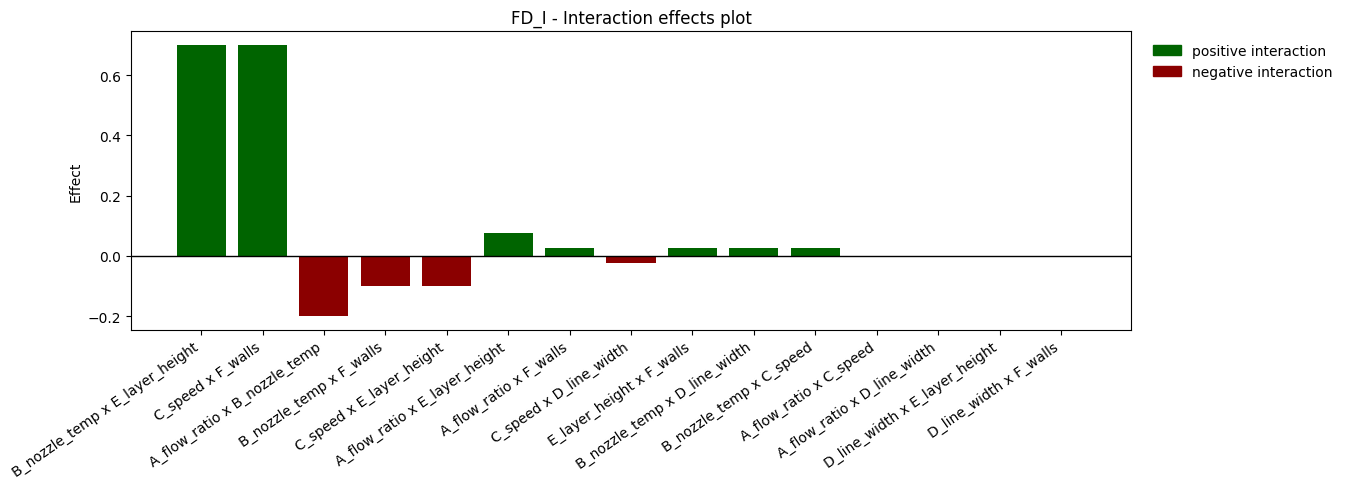

In [21]:
plot_interaction_effects(
    interaction_effects_I,
    experiment="FD_I",
)


#### FD_I Pairwise Interaction Plot Of Data Means


This plot shows the mean mass for each pair of coded factor levels. 
Non-parallel or crossing lines indicate a possible interaction pattern. 
Because FD_I is fractional, these visual interactions can still be aliased with generator relations such as `E = AB` and `F = AC`.


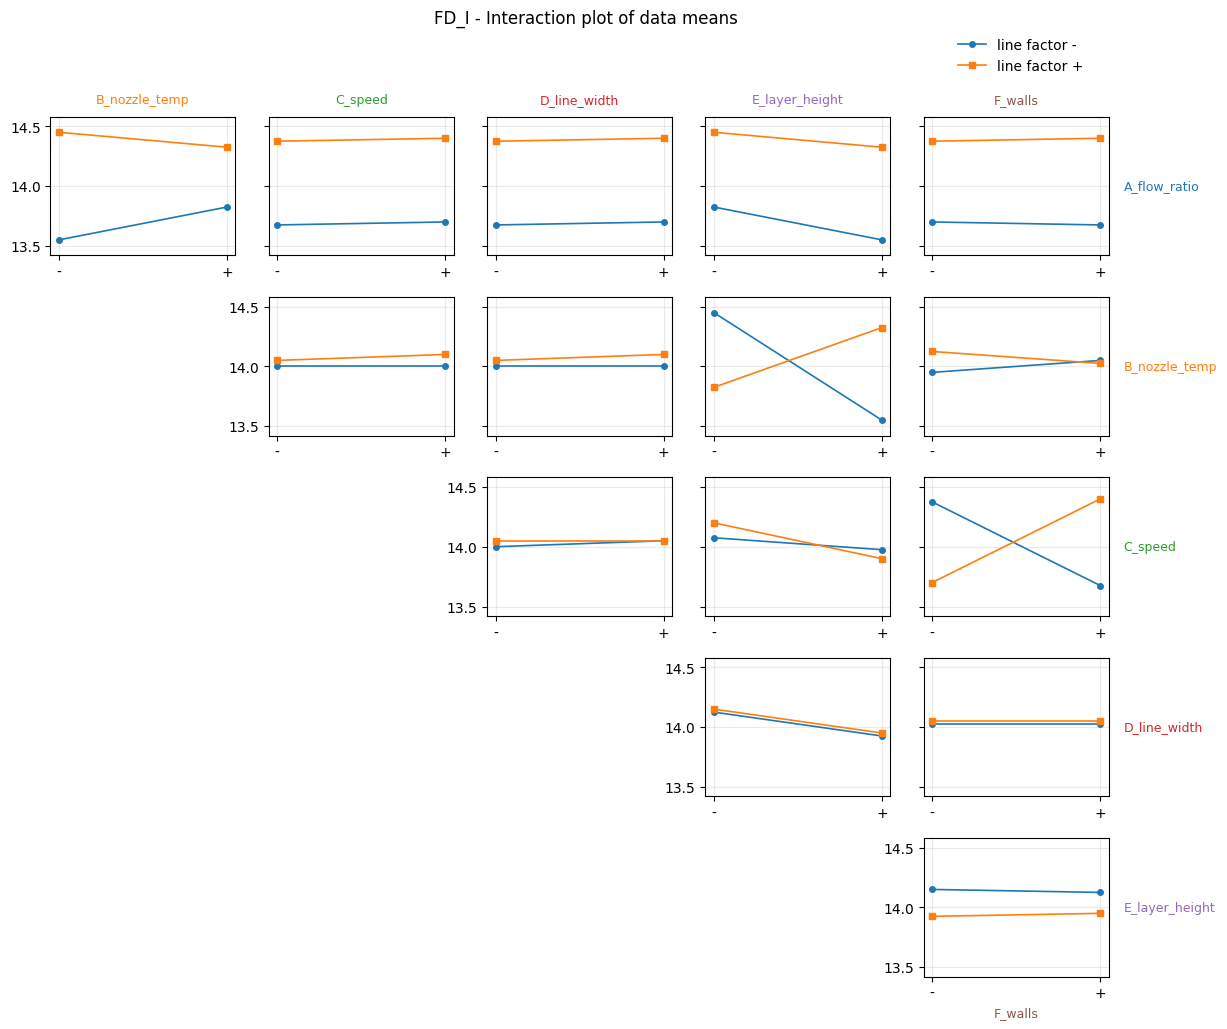

In [22]:
plot_interaction_mean_matrix(
    mass_result_matrix_I,
    response="mass_mean_g",
    experiment="FD_I",
)


# II) FD II


## 1) DoE Matrix


### FD_II Screening Matrix Without Wall Factors


In [23]:
fd_II_coded_df = create_fractional_factorial_design(include_walls=False)
fd_II_real_df = map_coded_to_real(fd_II_coded_df, FD_II_LEVELS)

display(fd_II_coded_df)
#display(fd_II_real_df)


,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height
Run,,,,,
1,-1,-1,-1,-1,1
2,-1,-1,-1,1,1
3,-1,-1,1,-1,1
4,-1,-1,1,1,1
5,-1,1,-1,-1,-1
6,-1,1,-1,1,-1
7,-1,1,1,-1,-1
8,-1,1,1,1,-1
9,1,-1,-1,-1,-1


## 2) Measurements


### FD_II Mass Measurements - RR Rectilinear Pattern


In [24]:
FD_II_RR_RUN_LABELS = [f"RR{run_no}" for run_no in range(1, 17)]
FD_II_RR_MASS_MEASUREMENTS_G = {
    column: values[:16]
    for column, values in FD_II_MASS_MEASUREMENTS_G.items()
}

mass_measurements_g, mass_columns = build_mass_measurements(
    FD_II_RR_MASS_MEASUREMENTS_G,
    run_labels=FD_II_RR_RUN_LABELS,
)

fd_II_e1_inline_mass_values = [
    values[16]
    for values in FD_II_MASS_MEASUREMENTS_G.values()
    if len(values) > 16 and values[16] is not None
]
fd_II_e1_mass_measurement_g = pd.DataFrame({
    "run": ["E1"],
    "mass_mean_g": [pd.Series(fd_II_e1_inline_mass_values, dtype=float).mean()],
}) if fd_II_e1_inline_mass_values else pd.DataFrame(columns=["run", "mass_mean_g"])

display(mass_measurements_g[["run", *mass_columns, "mass_mean_g", "mass_std_g"]])
if not fd_II_e1_mass_measurement_g.empty:
    display(fd_II_e1_mass_measurement_g.round(3))


,run,mass_1_g,mass_mean_g,mass_std_g
0,RR1,84.536,84.5,NaN
1,RR2,84.550,84.6,NaN
2,RR3,84.349,84.3,NaN
3,RR4,84.496,84.5,NaN
4,RR5,85.314,85.3,NaN
5,RR6,84.483,84.5,NaN
6,RR7,85.337,85.3,NaN
7,RR8,84.320,84.3,NaN
8,RR9,88.351,88.4,NaN
9,RR10,87.760,87.8,NaN


,run,mass_mean_g
0,E1,89.077


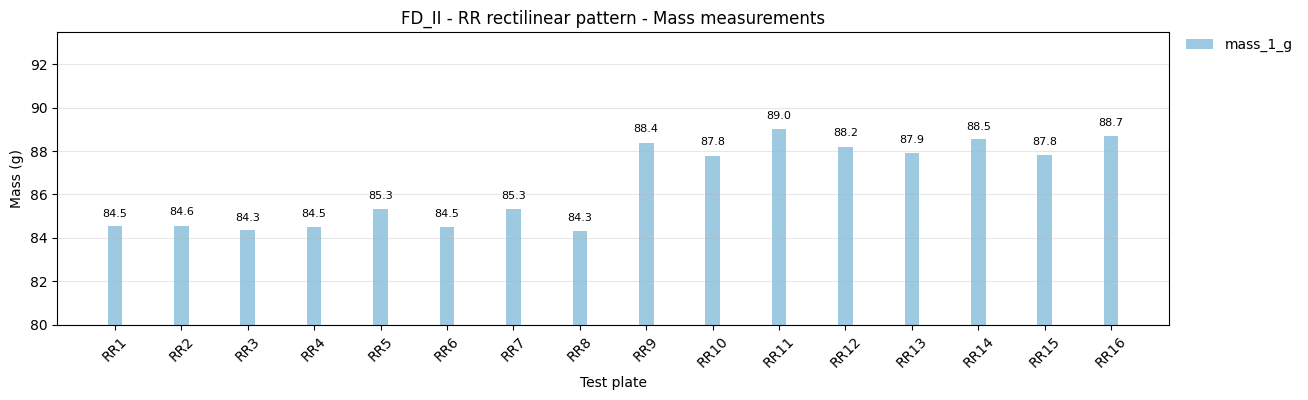

In [25]:
plot_mass_measurements(
    mass_measurements_g,
    mass_columns,
    y_min=80,
    mean_label="Trimmed mean",
    experiment="FD_II - RR rectilinear pattern",
    show_mean_line=False,
)


### FD_II Old-Scale Mass Measurements - RR Rectilinear Pattern

This comparison uses the archived old-scale FD_II measurements. Because four measurements are available, the plotted mean is the cropped mean: the lowest and highest values are discarded and the middle two values are averaged.

,run,mass_1_g,mass_2_g,mass_3_g,mass_4_g,mass_middle_1_g,mass_middle_2_g,mass_mean_g,mass_std_g
0,RR1,82.556,82.670,82.777,82.398,82.556,82.670,82.6,0.080610
1,RR2,83.023,82.844,82.683,82.818,82.818,82.844,82.8,0.018385
2,RR3,82.284,81.861,81.894,81.901,81.894,81.901,81.9,0.004950
3,RR4,82.416,82.028,82.255,81.960,82.028,82.255,82.1,0.160513
4,RR5,83.200,82.788,82.790,82.762,82.788,82.790,82.8,0.001414
5,RR6,83.047,82.046,82.062,82.078,82.062,82.078,82.1,0.011314
6,RR7,83.093,83.138,82.875,82.846,82.875,83.093,83.0,0.154149
7,RR8,82.062,81.796,81.847,82.304,81.847,82.062,82.0,0.152028
8,RR9,86.030,85.997,86.050,85.682,85.997,86.030,86.0,0.023335
9,RR10,85.403,85.419,85.470,85.200,85.403,85.419,85.4,0.011314


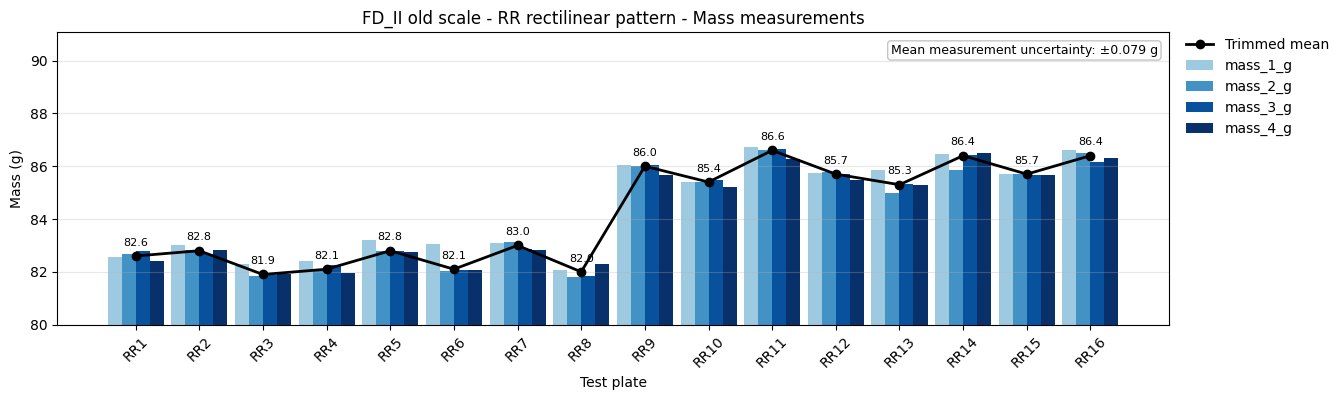

In [26]:
fd_II_old_scale_mass_measurements_g, fd_II_old_scale_mass_columns = build_mass_measurements(
    FD_II_OLD_SCALE_MASS_MEASUREMENTS_G,
)

display(fd_II_old_scale_mass_measurements_g[[
    "run",
    *fd_II_old_scale_mass_columns,
    "mass_middle_1_g",
    "mass_middle_2_g",
    "mass_mean_g",
    "mass_std_g",
]])

plot_mass_measurements(
    fd_II_old_scale_mass_measurements_g,
    fd_II_old_scale_mass_columns,
    y_min=80,
    mean_label="Trimmed mean",
    experiment="FD_II old scale - RR rectilinear pattern",
)


### FD_II Mass Measurements - RR Rectilinear Pattern Sorted by Mass

This is the same FD_II rectilinear mass plot, but the runs are ordered from lowest to highest mean mass.

,run,mass_1_g,mass_mean_g,mass_std_g
0,RR3,84.349,84.300,NaN
1,RR8,84.320,84.300,NaN
2,RR4,84.496,84.500,NaN
3,RR1,84.536,84.500,NaN
4,RR6,84.483,84.500,NaN
5,RR2,84.550,84.600,NaN
6,RR5,85.314,85.300,NaN
7,RR7,85.337,85.300,NaN
8,RR10,87.760,87.800,NaN
9,RR15,87.809,87.800,NaN


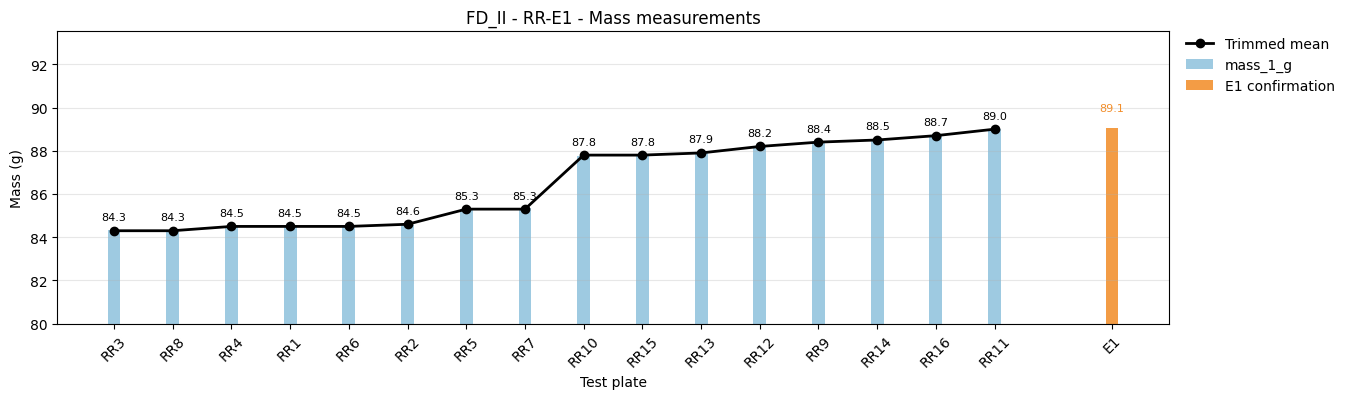

In [27]:
mass_measurements_g_sorted = mass_measurements_g.sort_values(
    "mass_mean_g",
    ascending=True,
)

if not fd_II_e1_mass_measurement_g.empty:
    e1_mass_measurement_g = fd_II_e1_mass_measurement_g.copy()
else:
    e1_index = EXTRA_RUN_LABELS.index("E1")
    e1_measurements_g = [
        values[e1_index]
        for values in EXTRA_RUN_MASS_MEASUREMENTS_G.values()
        if values[e1_index] is not None
    ]
    e1_mass_measurement_g = pd.DataFrame({
        "run": ["E1"],
        "mass_mean_g": [pd.Series(e1_measurements_g, dtype=float).mean()],
    })

sorted_with_e1 = pd.concat(
    [
        mass_measurements_g_sorted[["run", *mass_columns, "mass_mean_g", "mass_std_g"]],
        e1_mass_measurement_g.assign(mass_std_g=pd.NA),
    ],
    ignore_index=True,
)

display(sorted_with_e1)

plot_mass_measurements(
    mass_measurements_g_sorted,
    mass_columns,
    y_min=80,
    mean_label="Trimmed mean",
    experiment="FD_II - RR-E1",
    extra_measurements_g=e1_mass_measurement_g,
    extra_label="E1 confirmation",
    extra_color="#f28e2b",
)


### FD_II Mass Measurements - RC Concentric Pattern


In [28]:
fd_II_concentric_mass_measurements_g, fd_II_concentric_mass_columns = build_mass_measurements(
    FD_II_CONCENTRIC_MASS_MEASUREMENTS_G,
    run_labels=FD_II_CONCENTRIC_RUN_LABELS,
)

display(fd_II_concentric_mass_measurements_g[[
    "run",
    *fd_II_concentric_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])


,run,mass_1_g,mass_mean_g,mass_std_g
0,RC1,83.862,83.9,NaN
1,RC2,NaN,NaN,NaN
2,RC3,NaN,NaN,NaN
3,RC4,NaN,NaN,NaN
4,RC5,NaN,NaN,NaN
5,RC6,NaN,NaN,NaN
6,RC7,NaN,NaN,NaN
7,RC8,NaN,NaN,NaN
8,RC9,NaN,NaN,NaN
9,RC10,NaN,NaN,NaN


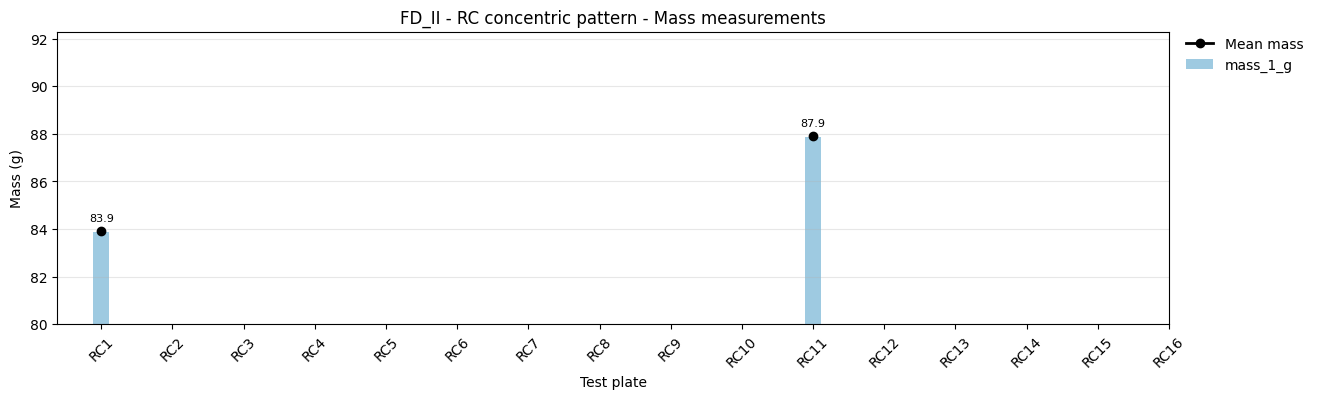

In [29]:
plot_mass_measurements(
    fd_II_concentric_mass_measurements_g,
    fd_II_concentric_mass_columns,
    y_min=80,
    mean_label="Mean mass",
    experiment="FD_II - RC concentric pattern",
)


#### FD_II Repeatability Placeholder


In [30]:
# TODO: Build FD_II repeat measurements and calculate repeatability.
# fd_II_repeatability = calculate_repeatability(
#     mass_measurements_g,
#     fd_II_repeat_mass_measurements_g,
# )
# display(fd_II_repeatability)


## 3) Analysis


### FD_II Screening Analysis


#### FD_II Main-Effect Estimates


In [31]:
mass_result_matrix_II = build_result_matrix(
    fd_II_coded_df,
    mass_measurements_g,
    response="mass_mean_g",
)
#mass_result_matrix_II


In [32]:
main_effect_df = compute_main_effects(mass_result_matrix_II, response="mass_mean_g")
main_effect_df


,Effect,Main effect
0,A_flow_ratio,3.625
1,B_nozzle_temp,0.125
2,C_speed,0.075
3,D_line_width,-0.175
4,E_layer_height,-0.250


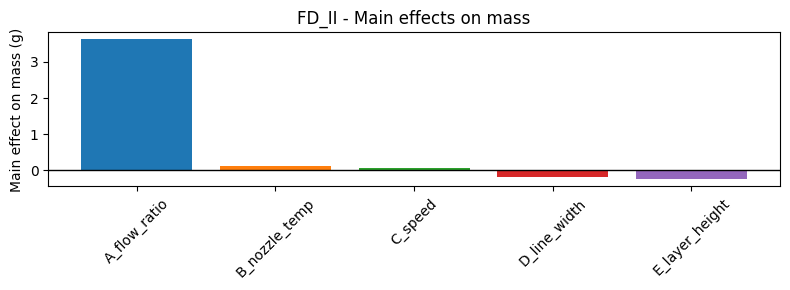

In [33]:
plot_main_effects_bar(
    main_effect_df,
    response="mass_mean_g",
    experiment="FD_II",
)


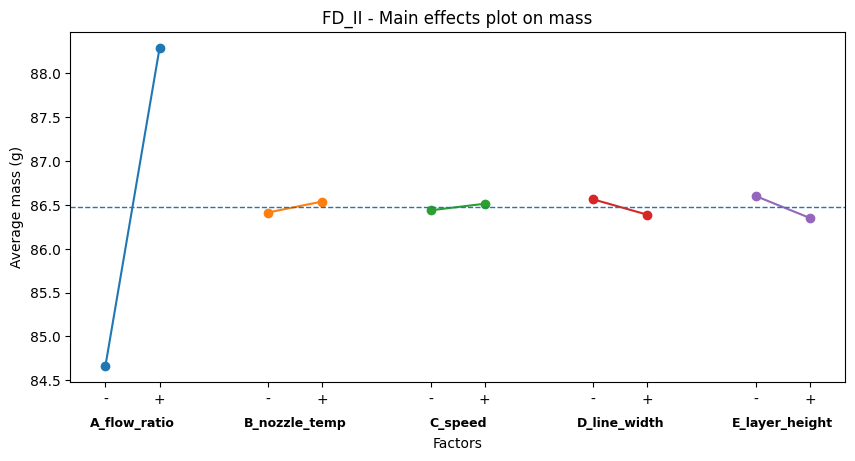

In [34]:
plot_main_effects_line(
    mass_result_matrix_II,
    response="mass_mean_g",
    experiment="FD_II",
)


#### FD_II RR-Only Regression Main-Effects Plot


This plot uses ordinary regression on the original `RR1` to `RR16` FD_II runs only. 
It does not include E1, so it is the comparable pre-confirmation model.


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,16,6,6,True,10,0.9624,0.455


,term,coefficient,effect,standard_error,t_value,F_value,p_value
0,Intercept,86.4750,86.475,0.1137,760.2657,578003.9130,0.0000
1,A_flow_ratio,1.8125,3.625,0.1137,15.9350,253.9251,0.0000
2,B_nozzle_temp,0.0625,0.125,0.1137,0.5495,0.3019,0.5947
3,C_speed,0.0375,0.075,0.1137,0.3297,0.1087,0.7484
4,D_line_width,-0.0875,-0.175,0.1137,-0.7693,0.5918,0.4595
5,E_layer_height,-0.1250,-0.250,0.1137,-1.0990,1.2077,0.2975


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,5,53.02,10.604,51.2271,0.0
1,Residual,10,2.07,0.207,NaN,NaN
2,Total,15,55.09,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,1.8125,0.1137,15.9350,253.9251,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,B_nozzle_temp,0.0625,0.1137,0.5495,0.3019,0.5947,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C_speed,0.0375,0.1137,0.3297,0.1087,0.7484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,D_line_width,-0.0875,0.1137,-0.7693,0.5918,0.4595,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,E_layer_height,-0.1250,0.1137,-1.0990,1.2077,0.2975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


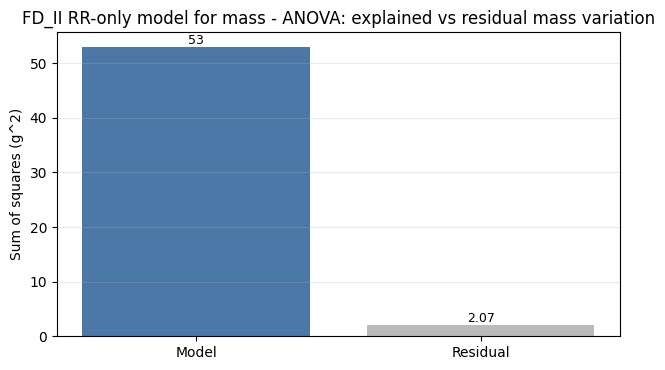

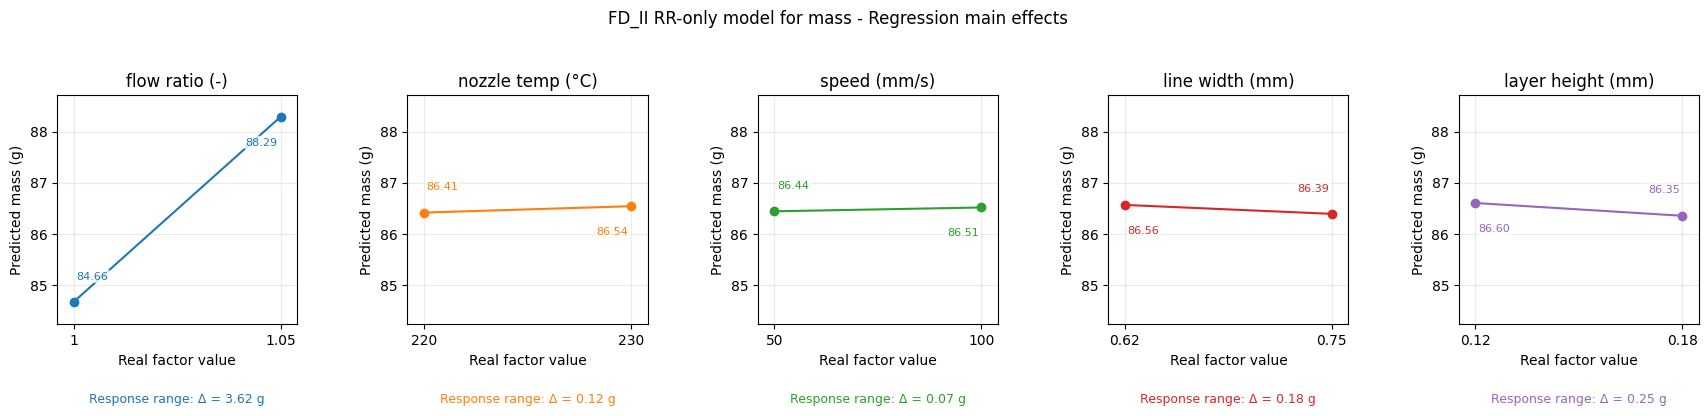

In [35]:
FD_II_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
]

fd_II_rr_only_model = fit_main_effect_screening_model(
    mass_result_matrix_II,
    response="mass_mean_g",
    factor_cols=FD_II_FACTOR_COLUMNS,
)

fd_II_rr_only_anova_table = build_model_anova_table(fd_II_rr_only_model)
display(fd_II_rr_only_model["info_df"].round(4))
display(fd_II_rr_only_model["statistics_df"].round(4))
display(fd_II_rr_only_anova_table.round(4))
display(build_term_significance_table(fd_II_rr_only_model).round(4))
plot_model_anova(
    fd_II_rr_only_anova_table,
    response="mass_mean_g",
    experiment="FD_II RR-only model for mass",
)

plot_augmented_main_effects(
    fd_II_rr_only_model,
    FD_II_LEVELS,
    experiment="FD_II RR-only model for mass",
    plot_label="Regression main effects",
)


#### FD_II RR-Only Regression Pareto Plot


This Pareto chart uses the ordinary regression model fitted only to `RR1` to `RR16`. 
It ranks the FD_II main effects by their absolute regression `t` value, so it is directly comparable to the augmented FD_II Pareto plot with E1 added.


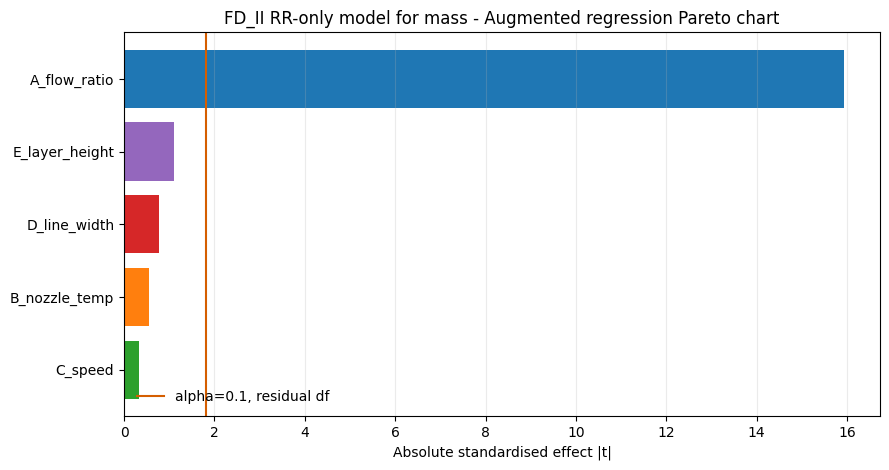

In [36]:
plot_augmented_model_pareto(
    fd_II_rr_only_model,
    experiment="FD_II RR-only model for mass",
)


#### FD_II Main-Effect Estimates Excluding Flow Ratio


In [37]:
main_effect_df_no_flow = main_effect_df[
    main_effect_df["Effect"] != "A_flow_ratio"
].copy()

mass_result_matrix_II_no_flow = mass_result_matrix_II.drop(
    columns=["A_flow_ratio"]
)

main_effect_df_no_flow


,Effect,Main effect
1,B_nozzle_temp,0.125
2,C_speed,0.075
3,D_line_width,-0.175
4,E_layer_height,-0.250


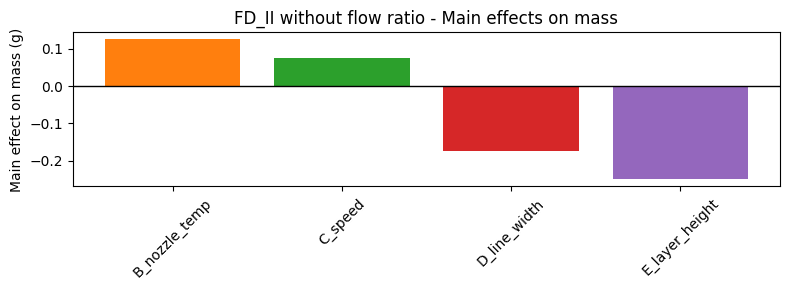

In [38]:
plot_main_effects_bar(
    main_effect_df_no_flow,
    response="mass_mean_g",
    experiment="FD_II without flow ratio",
)


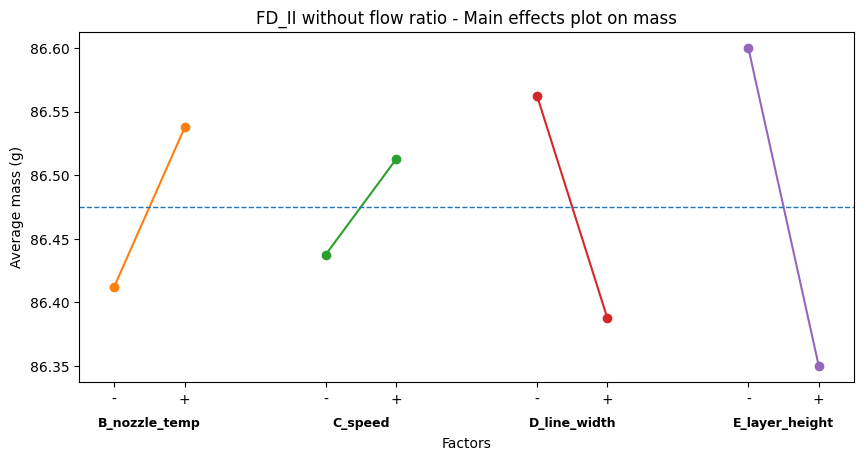

In [39]:
plot_main_effects_line(
    mass_result_matrix_II_no_flow,
    response="mass_mean_g",
    experiment="FD_II without flow ratio",
)


#### FD_II Aliased Interaction Estimates


In [40]:
FD_II_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
}

interaction_effects_II = compute_interaction_effects(
    mass_result_matrix_II,
    response="mass_mean_g",
    generators=FD_II_GENERATORS,
)

interaction_effects_II


,Interaction,Alias / generator note,Effect
6,B_nozzle_temp x E_layer_height,,3.625000e+00
9,D_line_width x E_layer_height,,6.250000e-01
0,A_flow_ratio x B_nozzle_temp,E_layer_height; generator E=AB,-2.500000e-01
1,A_flow_ratio x C_speed,,2.000000e-01
2,A_flow_ratio x D_line_width,,2.000000e-01
3,A_flow_ratio x E_layer_height,,1.250000e-01
8,C_speed x E_layer_height,,-1.250000e-01
4,B_nozzle_temp x C_speed,,-1.000000e-01
5,B_nozzle_temp x D_line_width,,1.000000e-01
7,C_speed x D_line_width,,1.421085e-14


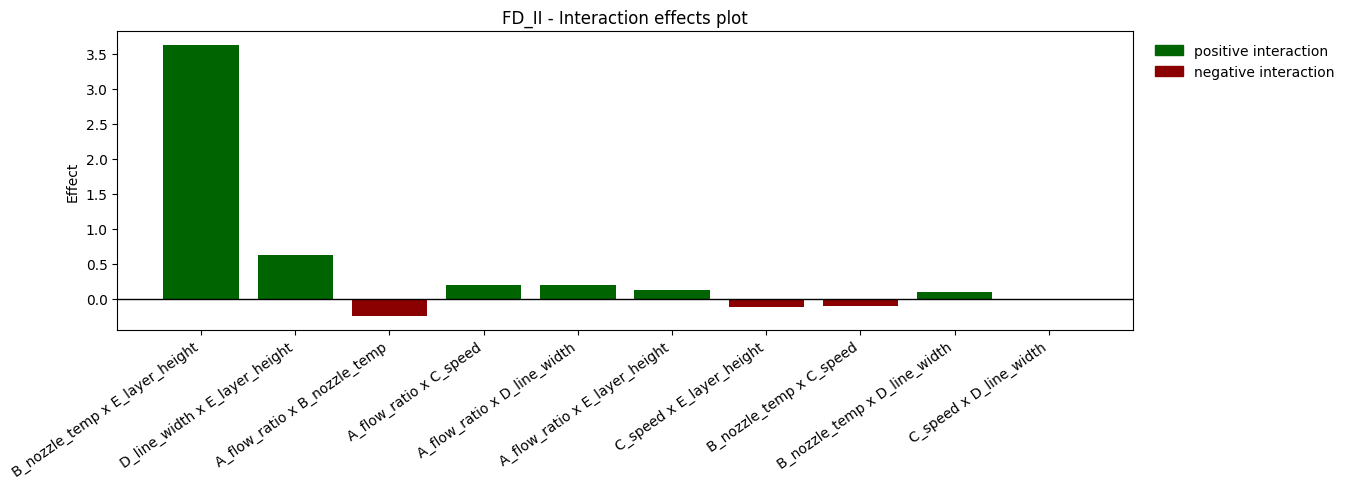

In [41]:
plot_interaction_effects(
    interaction_effects_II,
    experiment="FD_II",
)


#### FD_II Pairwise Interaction Plot Of Data Means


This is the same interaction-matrix view used for FD_I, but applied to the FD_II RR rectilinear mass results. 
Non-parallel or crossing lines suggest possible interaction behavior. 
Because FD_II is also fractional, the visible pairwise patterns should still be interpreted together with the aliasing relation `E = AB`.


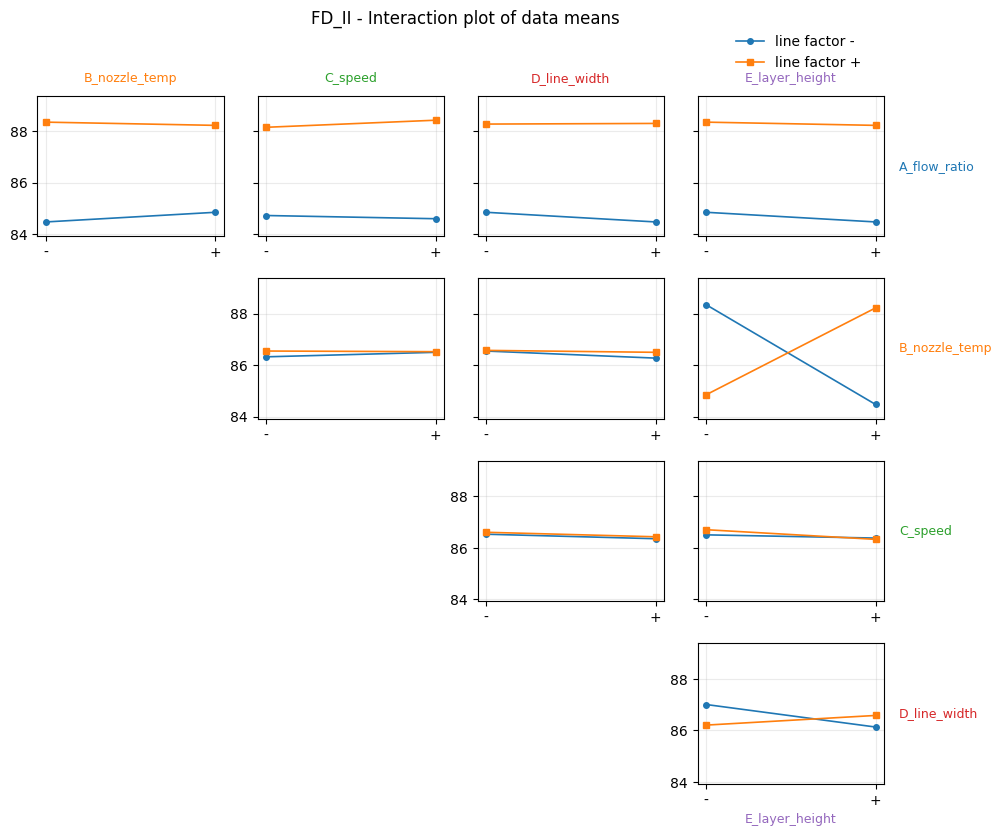

In [42]:
plot_interaction_mean_matrix(
    mass_result_matrix_II,
    response="mass_mean_g",
    experiment="FD_II",
)


#### FD_II Conditional Main Effects: Normal vs Overextrusion Runs


In [43]:
conditional_factor_cols = ["C_speed", "D_line_width"]

mass_result_matrix_II_RR1_8 = mass_result_matrix_II.iloc[:8][
    conditional_factor_cols + ["mass_mean_g"]
].copy()
mass_result_matrix_II_RR9_16 = mass_result_matrix_II.iloc[8:16][
    conditional_factor_cols + ["mass_mean_g"]
].copy()

conditional_effect_df_II_RR1_8 = compute_main_effects(
    mass_result_matrix_II_RR1_8,
    response="mass_mean_g",
)
conditional_effect_df_II_RR9_16 = compute_main_effects(
    mass_result_matrix_II_RR9_16,
    response="mass_mean_g",
)

display(conditional_effect_df_II_RR1_8)
display(conditional_effect_df_II_RR9_16)


,Effect,Main effect
0,C_speed,-0.125
1,D_line_width,-0.375


,Effect,Main effect
0,C_speed,0.275
1,D_line_width,0.025


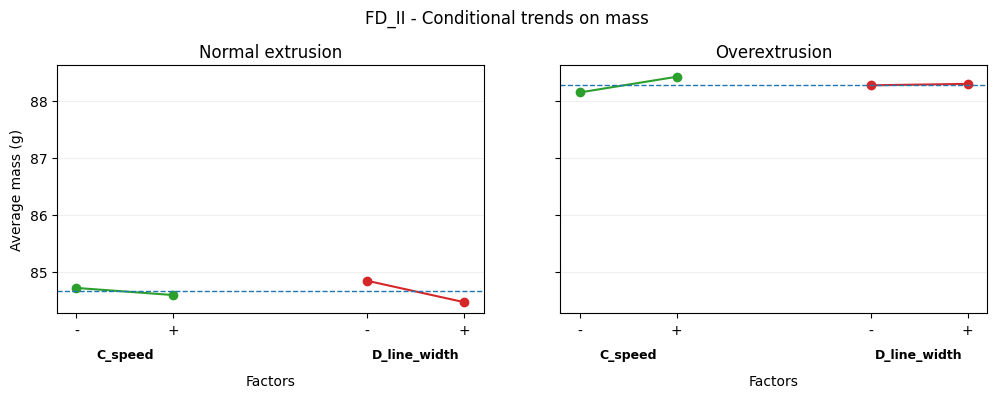

In [44]:
plot_main_effects_line_comparison(
    [mass_result_matrix_II_RR1_8, mass_result_matrix_II_RR9_16],
    labels=["Normal extrusion", "Overextrusion"],
    response="mass_mean_g",
    experiment="FD_II",
)


### E1 Confirmation Run for FD_II


E1 is first treated as an independent confirmation run. The original FD_II model is fitted using only the rectilinear `RR1` to `RR16` runs, then E1 is predicted from its coded settings. 
The confirmation error is `measured E1 - predicted E1`. After this comparison, E1 is added as one extra experimental row in an augmented FD_II model. 
Because the augmented design is no longer perfectly balanced, the augmented effects and Pareto chart use ordinary regression coefficients and regression `t` values, not the original orthogonal factorial effect formulas.


#### Independent E1 Confirmation From RR1-RR16 Only


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,5,53.02,10.604,51.2271,0.0
1,Residual,10,2.07,0.207,NaN,NaN
2,Total,15,55.09,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,1.8125,0.1137,15.9350,253.9251,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,B_nozzle_temp,0.0625,0.1137,0.5495,0.3019,0.5947,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C_speed,0.0375,0.1137,0.3297,0.1087,0.7484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,D_line_width,-0.0875,0.1137,-0.7693,0.5918,0.4595,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,E_layer_height,-0.1250,0.1137,-1.0990,1.2077,0.2975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


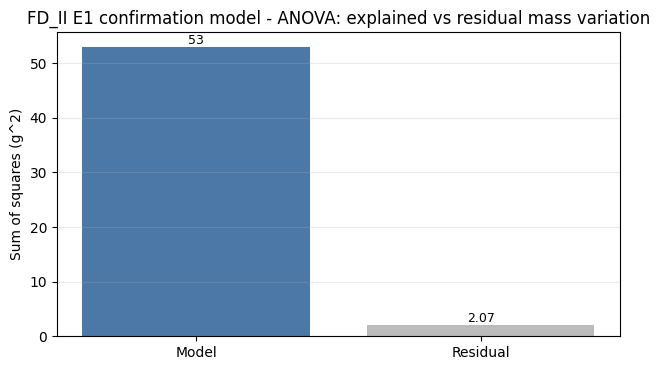

,case,coded_setting,real_setting,predicted_mass_g,measured_mass_g,confirmation_error_g,confirmation_error_percent,fit_data
0,E1 independent confirmation,"{'A_flow_ratio': 1, 'B_nozzle_temp': 1, 'C_spe...","{'A_flow_ratio': 1.05, 'B_nozzle_temp': 230, '...",88.525,89.077,0.552,0.62,RR1-RR16 only


In [45]:
FD_II_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
]

# E1 uses the FD_II best-setting confirmation point from the main effects.
# It differs from RR13 only in layer height: E1 has low layer height, RR13 has high layer height.
E1_CODED_SETTING = {
    "A_flow_ratio": 1,
    "B_nozzle_temp": 1,
    "C_speed": -1,
    "D_line_width": -1,
    "E_layer_height": -1,
}

def predict_from_screening_model(model, coded_setting):
    prediction = model["coefficients"]["Intercept"]
    for factor in model["factor_cols"]:
        prediction += model["coefficients"][factor] * coded_setting[factor]
    return prediction

fd_II_e1_inline_mass_values = [
    values[16]
    for values in FD_II_MASS_MEASUREMENTS_G.values()
    if len(values) > 16 and values[16] is not None
]
if fd_II_e1_inline_mass_values:
    e1_raw_mass_values = fd_II_e1_inline_mass_values
else:
    e1_index = EXTRA_RUN_LABELS.index("E1")
    e1_raw_mass_values = [
        values[e1_index]
        for values in EXTRA_RUN_MASS_MEASUREMENTS_G.values()
        if values[e1_index] is not None
    ]
e1_observed_mass_g = pd.Series(e1_raw_mass_values, dtype=float).mean()

# Original confirmation model: fit only RR1-RR16.
fd_II_rr_only_model = fit_main_effect_screening_model(
    mass_result_matrix_II,
    response="mass_mean_g",
    factor_cols=FD_II_FACTOR_COLUMNS,
)
fd_II_e1_confirmation_anova_table = build_model_anova_table(fd_II_rr_only_model)
display(fd_II_e1_confirmation_anova_table.round(4))
display(build_term_significance_table(fd_II_rr_only_model).round(4))
plot_model_anova(
    fd_II_e1_confirmation_anova_table,
    response="mass_mean_g",
    experiment="FD_II E1 confirmation model",
)

e1_predicted_from_rr_only = predict_from_screening_model(
    fd_II_rr_only_model,
    E1_CODED_SETTING,
)

fd_II_e1_confirmation = pd.DataFrame([
    {
        "case": "E1 independent confirmation",
        "coded_setting": E1_CODED_SETTING,
        "real_setting": {
            factor: FD_II_LEVELS[factor][coded]
            for factor, coded in E1_CODED_SETTING.items()
        },
        "predicted_mass_g": e1_predicted_from_rr_only,
        "measured_mass_g": e1_observed_mass_g,
        "confirmation_error_g": e1_observed_mass_g - e1_predicted_from_rr_only,
        "confirmation_error_percent": 100 * (e1_observed_mass_g - e1_predicted_from_rr_only) / e1_observed_mass_g,
        "fit_data": "RR1-RR16 only",
    }
])

display(fd_II_e1_confirmation.round({
    "predicted_mass_g": 3,
    "measured_mass_g": 3,
    "confirmation_error_g": 3,
    "confirmation_error_percent": 2,
}))


#### Augmented FD_II Model With E1 Added


In [46]:
fd_II_rr_labeled_result_matrix = mass_result_matrix_II.copy()
fd_II_rr_labeled_result_matrix["Run"] = [
    f"RR{run_no}" for run_no in range(1, len(fd_II_rr_labeled_result_matrix) + 1)
]

e1_augmented_row = pd.DataFrame([{
    "Run": "E1",
    **E1_CODED_SETTING,
    "mass_mean_g": e1_observed_mass_g,
}])
fd_II_augmented_result_matrix = pd.concat(
    [fd_II_rr_labeled_result_matrix, e1_augmented_row],
    ignore_index=True,
)

display(fd_II_augmented_result_matrix.tail())

# Augmented fractional factorial model: ordinary regression on RR1-RR16 + E1.
fd_II_augmented_model = fit_main_effect_screening_model(
    fd_II_augmented_result_matrix,
    response="mass_mean_g",
    factor_cols=FD_II_FACTOR_COLUMNS,
)

display(fd_II_augmented_model["info_df"].round(4))

fd_II_augmented_anova_table = build_model_anova_table(fd_II_augmented_model)
display(fd_II_augmented_anova_table.round(4))
display(build_term_significance_table(fd_II_augmented_model).round(4))

fd_II_augmented_effects = (
    fd_II_augmented_model["statistics_df"]
    .query("term != 'Intercept'")
    .copy()
)
fd_II_augmented_effects = fd_II_augmented_effects.rename(
    columns={"effect": "effect_low_to_high"}
)
fd_II_augmented_effects["absolute_t"] = fd_II_augmented_effects["t_value"].abs()
fd_II_augmented_effects = fd_II_augmented_effects.sort_values(
    "absolute_t",
    ascending=False,
)

display(fd_II_augmented_effects.round({
    "coefficient": 4,
    "effect_low_to_high": 4,
    "standard_error": 4,
    "t_value": 3,
    "p_value": 4,
    "absolute_t": 3,
}))


,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height,mass_mean_g,Run
12,1,1,-1,-1,1,87.900,RR13
13,1,1,-1,1,1,88.500,RR14
14,1,1,1,-1,1,87.800,RR15
15,1,1,1,1,1,88.700,RR16
16,1,1,-1,-1,-1,89.077,E1


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,17,6,6,True,11,0.9627,0.4564


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,5,59.1705,11.8341,56.8053,0.0
1,Residual,11,2.2916,0.2083,NaN,NaN
2,Total,16,61.4621,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,1.8376,0.1115,16.4830,271.6904,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,B_nozzle_temp,0.0876,0.1115,0.7857,0.6173,0.4486,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C_speed,0.0124,0.1115,0.1113,0.0124,0.9134,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,D_line_width,-0.1126,0.1115,-1.0099,1.0200,0.3342,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,E_layer_height,-0.1501,0.1115,-1.3463,1.8125,0.2053,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,term,coefficient,effect_low_to_high,standard_error,t_value,F_value,p_value,absolute_t
1,A_flow_ratio,1.8376,3.6752,0.1115,16.483,271.690439,0.0000,16.483
5,E_layer_height,-0.1501,-0.3002,0.1115,-1.346,1.812531,0.2053,1.346
4,D_line_width,-0.1126,-0.2252,0.1115,-1.010,1.019960,0.3342,1.010
2,B_nozzle_temp,0.0876,0.1752,0.1115,0.786,0.617298,0.4486,0.786
3,C_speed,0.0124,0.0248,0.1115,0.111,0.012390,0.9134,0.111


#### Augmented FD_II Regression Plots


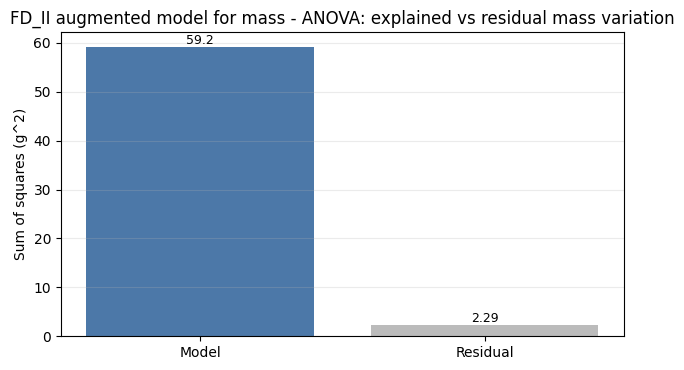

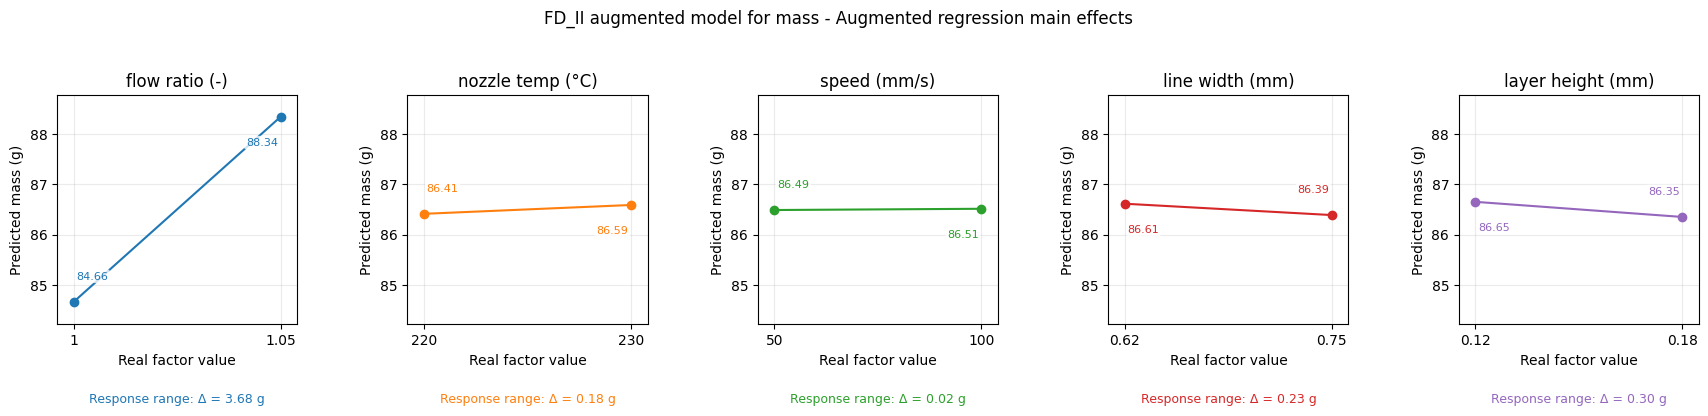

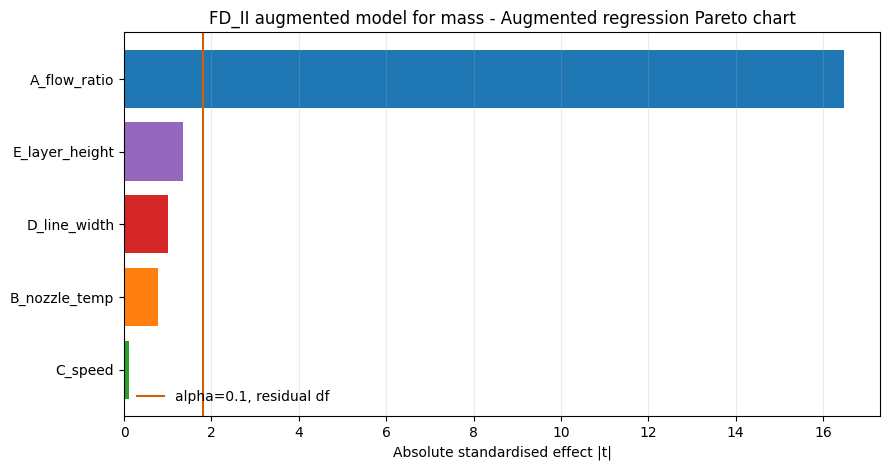

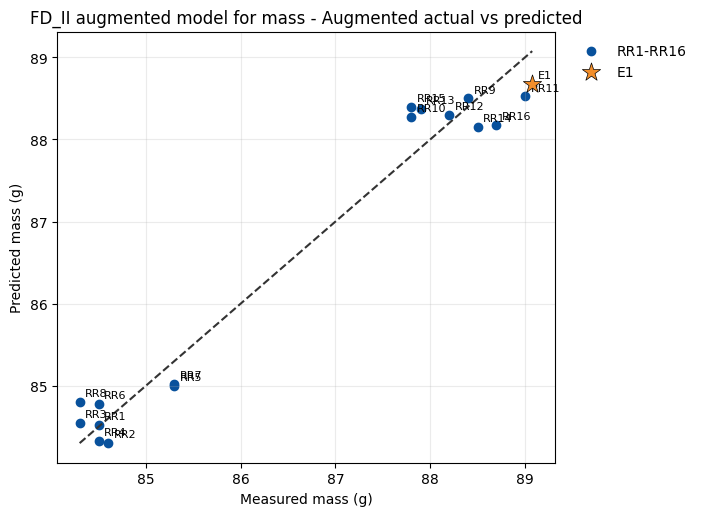

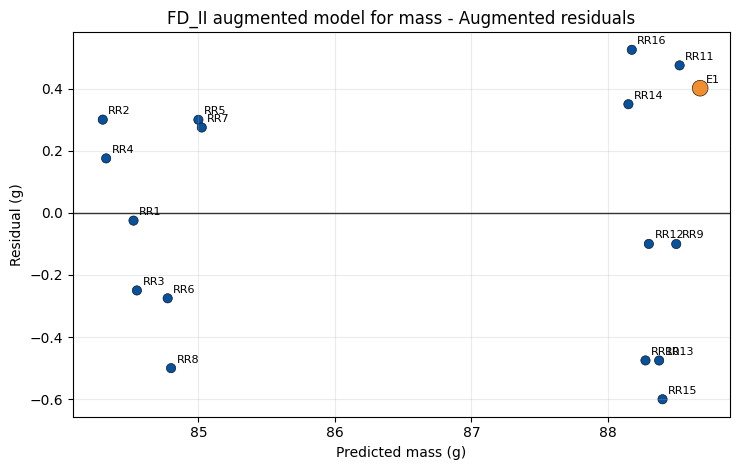

In [47]:
plot_model_anova(
    fd_II_augmented_anova_table,
    response="mass_mean_g",
    experiment="FD_II augmented model for mass",
)

plot_augmented_main_effects(
    fd_II_augmented_model,
    FD_II_LEVELS,
    experiment="FD_II augmented model for mass",
)
plot_augmented_model_pareto(
    fd_II_augmented_model,
    experiment="FD_II augmented model for mass",
)
plot_augmented_observed_vs_predicted(
    fd_II_augmented_model,
    confirmation_run="E1",
    experiment="FD_II augmented model for mass",
)
plot_augmented_residuals(
    fd_II_augmented_model,
    confirmation_run="E1",
    experiment="FD_II augmented model for mass",
)


#### E1 Compared With RR13


In [48]:
fd_II_e1_vs_rr13 = fd_II_augmented_result_matrix.loc[
    fd_II_augmented_result_matrix["Run"].isin(["RR13", "E1"]),
    ["Run", *FD_II_FACTOR_COLUMNS, "mass_mean_g"],
].copy()
for factor in FD_II_FACTOR_COLUMNS:
    fd_II_e1_vs_rr13[f"{factor}_real"] = fd_II_e1_vs_rr13[factor].map(FD_II_LEVELS[factor])

display(fd_II_e1_vs_rr13[[
    "Run",
    *[f"{factor}_real" for factor in FD_II_FACTOR_COLUMNS],
    "mass_mean_g",
]].round(3))


,Run,A_flow_ratio_real,B_nozzle_temp_real,C_speed_real,D_line_width_real,E_layer_height_real,mass_mean_g
12,RR13,1.05,230,50,0.62,0.18,87.900
16,E1,1.05,230,50,0.62,0.12,89.077


### FD II Vacuum Response Effect Screening for RR Runs

This section links the vacuum overview score table back to the PLA FD_II / RR screening settings. 
The vacuum overview labels use `PLA R01`, `PLA R02`, etc.; here these are interpreted as `RR1`, `RR2`, etc. from FD_II. 
For each overview row, the raw effect is the average response at the high factor level minus the average response at the low factor level. 
The plot shows this as a percent change relative to the low-level mean, which keeps very small vacuum values readable. 
Positive values therefore mean that increasing the factor also increases that response. For the vacuum metrics and the overview score, lower values are better, so a positive effect is usually unfavorable. 
The `n_low` and `n_high` columns in the table show how many runs were available at each factor level for that estimate. 
The current pressure-rise dataset only contains a subset of RR runs, so these plots should be read as screening indications, not final fitted DoE conclusions.


Using PLA vacuum overview scores from: ..\Vacuum_pump-Project\vacuum_pump_chamber_outputs\R_series\pump_down\tables\r_series_overview_metric_scores.csv


,experiment,run,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height,weight_g,average_score,Q_pressure_rise_mbar_L_s_value,desorption_24h_mbar_L_s_cm2_value,pressure_40h_avg_mbar_value
0,PLA R03,RR3,-1,-1,1,-1,1,84.3,0.896126,NaN,1.954877e-06,1.363917e-06
1,PLA R05,RR5,-1,1,-1,-1,-1,85.3,0.779324,1.231644e-10,2.459739e-06,1.307772e-06
2,PLA R08,RR8,-1,1,1,1,-1,84.3,0.728592,2.691660e-10,1.350029e-06,8.877639e-07
3,PLA R07,RR7,-1,1,1,-1,-1,85.3,0.696498,1.400158e-10,1.967264e-06,1.151480e-06
4,PLA R09,RR9,1,-1,-1,-1,-1,88.4,0.587641,NaN,1.008524e-06,1.060913e-06
5,PLA R04,RR4,-1,-1,1,1,1,84.5,0.508725,7.952887e-11,1.435885e-06,1.034495e-06
6,PLA R02,RR2,-1,-1,-1,1,1,84.6,0.498390,5.598627e-11,1.697436e-06,9.829886e-07
7,PLA R01,RR1,-1,-1,-1,-1,1,84.5,0.454298,3.362779e-11,1.732324e-06,9.141343e-07
8,PLA R06,RR6,-1,1,-1,1,-1,84.5,0.069370,5.412942e-11,1.165511e-07,1.458820e-07


,metric,factor,low_mean,high_mean,effect_high_minus_low,effect_percent_of_low_mean,n_low,n_high
0,Weight [g],A_flow_ratio,8.466250e+01,8.840000e+01,3.737500e+00,4.414587,8,1
1,Weight [g],B_nozzle_temp,8.526000e+01,8.485000e+01,-4.100000e-01,-0.480882,5,4
2,Weight [g],C_speed,8.546000e+01,8.460000e+01,-8.600000e-01,-1.006319,5,4
3,Weight [g],D_line_width,8.556000e+01,8.447500e+01,-1.085000e+00,-1.268116,5,4
4,Weight [g],E_layer_height,8.556000e+01,8.447500e+01,-1.085000e+00,-1.268116,5,4
5,"Average overview score (0 best, 1 worst)",A_flow_ratio,5.789154e-01,5.876408e-01,8.725387e-03,1.507196,8,1
6,"Average overview score (0 best, 1 worst)",B_nozzle_temp,5.890360e-01,5.684460e-01,-2.059005e-02,-3.495550,5,4
7,"Average overview score (0 best, 1 worst)",C_speed,4.778045e-01,7.074853e-01,2.296808e-01,48.070042,5,4
8,"Average overview score (0 best, 1 worst)",D_line_width,6.827772e-01,4.512694e-01,-2.315078e-01,-33.906784,5,4
9,"Average overview score (0 best, 1 worst)",E_layer_height,5.722849e-01,5.893848e-01,1.709989e-02,2.988003,5,4


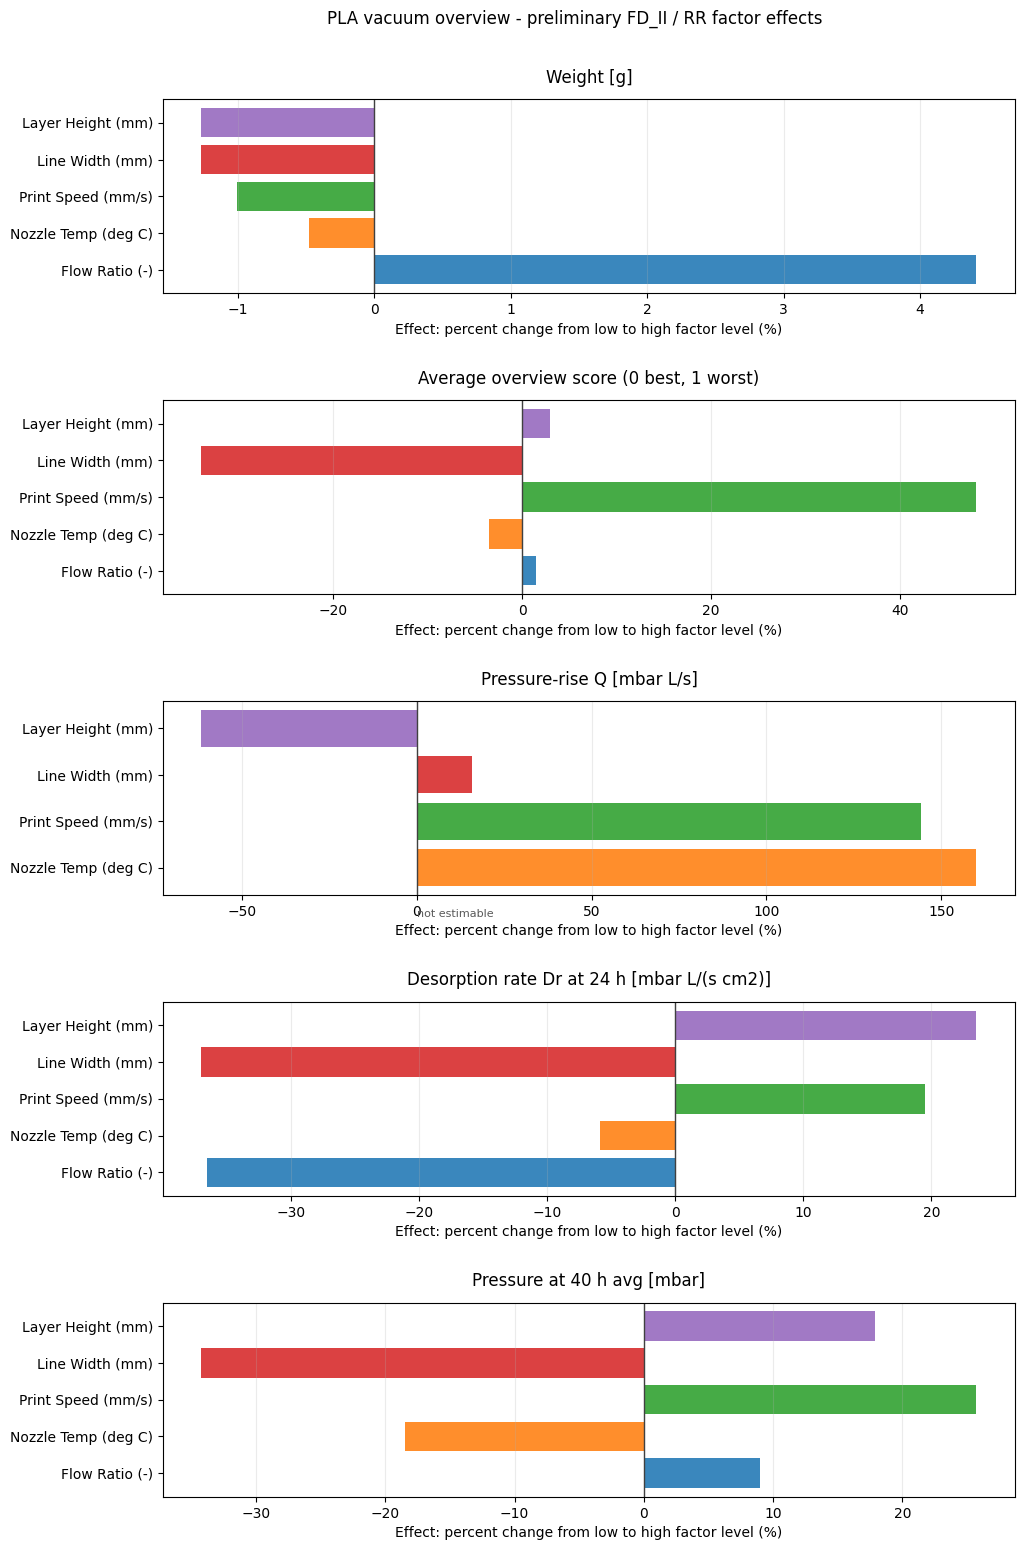

In [49]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pla_doe_measurements import FD_II_MASS_MEASUREMENTS_G, FD_II_RUNS

PLA_VACUUM_OVERVIEW_SCORE_PATHS = [
    Path("../Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/pump_down/tables/r_series_overview_metric_scores.csv"),
    Path("Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/pump_down/tables/r_series_overview_metric_scores.csv"),
    Path("../Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/tables/r_series_overview_metric_scores.csv"),
    Path("Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/tables/r_series_overview_metric_scores.csv"),
]
PLA_VACUUM_OVERVIEW_SEARCH_ROOTS = [
    Path("../Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series"),
    Path("Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series"),
]

pla_vacuum_overview_score_path = next(
    (path for path in PLA_VACUUM_OVERVIEW_SCORE_PATHS if path.exists()),
    None,
)
if pla_vacuum_overview_score_path is None:
    pla_vacuum_overview_score_path = next(
        (
            candidate
            for root in PLA_VACUUM_OVERVIEW_SEARCH_ROOTS
            if root.exists()
            for candidate in root.rglob("r_series_overview_metric_scores.csv")
        ),
        None,
    )
if pla_vacuum_overview_score_path is None:
    searched_paths = [str(path) for path in PLA_VACUUM_OVERVIEW_SCORE_PATHS]
    searched_roots = [str(path) for path in PLA_VACUUM_OVERVIEW_SEARCH_ROOTS]
    raise FileNotFoundError(
        "Could not find r_series_overview_metric_scores.csv. "
        f"Checked paths: {searched_paths}; searched roots: {searched_roots}"
    )

print(f"Using PLA vacuum overview scores from: {pla_vacuum_overview_score_path}")

pla_vacuum_scores = pd.read_csv(pla_vacuum_overview_score_path)

FD_II_WEIGHT_RESPONSE = "weight_g"
fd_ii_weight_measurements_g, _ = build_mass_measurements(
    FD_II_MASS_MEASUREMENTS_G,
    run_labels=[run["run"] for run in FD_II_RUNS],
)
fd_ii_weight_measurements_g = fd_ii_weight_measurements_g.rename(
    columns={"mass_mean_g": FD_II_WEIGHT_RESPONSE}
)[["run", FD_II_WEIGHT_RESPONSE]]

PLA_VACUUM_METRICS = {
    "Weight [g]": FD_II_WEIGHT_RESPONSE,
    "Average overview score (0 best, 1 worst)": "average_score",
    "Pressure-rise Q [mbar L/s]": "Q_pressure_rise_mbar_L_s_value",
    "Desorption rate Dr at 24 h [mbar L/(s cm2)]": "desorption_24h_mbar_L_s_cm2_value",
    "Pressure at 40 h avg [mbar]": "pressure_40h_avg_mbar_value",
}

def pla_run_label(experiment):
    match = re.fullmatch(r"PLA R0?(\d+)", str(experiment).strip())
    if not match:
        return None
    return f"RR{int(match.group(1))}"

fd_ii_design_rows = []
for run in FD_II_RUNS:
    row = {"run": run["run"]}
    row.update(run["coded_parameters"])
    row.update({f"{factor}_real": value for factor, value in run["parameters"].items()})
    fd_ii_design_rows.append(row)

fd_ii_design_for_vacuum = pd.DataFrame(fd_ii_design_rows)
pla_vacuum_scores = pla_vacuum_scores.assign(run=pla_vacuum_scores["experiment"].map(pla_run_label))
pla_vacuum_effect_data = pla_vacuum_scores.dropna(subset=["run"]).merge(
    fd_ii_design_for_vacuum,
    on="run",
    how="left",
).merge(
    fd_ii_weight_measurements_g,
    on="run",
    how="left",
)

factor_cols = list(FD_II_LEVELS)
effect_rows = []
for metric_label, metric_col in PLA_VACUUM_METRICS.items():
    for factor in factor_cols:
        low_values = pla_vacuum_effect_data.loc[
            pla_vacuum_effect_data[factor] == -1, metric_col
        ].dropna()
        high_values = pla_vacuum_effect_data.loc[
            pla_vacuum_effect_data[factor] == 1, metric_col
        ].dropna()
        low_mean = low_values.mean() if len(low_values) else np.nan
        high_mean = high_values.mean() if len(high_values) else np.nan
        effect = np.nan
        effect_percent = np.nan
        if len(low_values) and len(high_values):
            effect = high_mean - low_mean
            if low_mean != 0 and np.isfinite(low_mean):
                effect_percent = 100 * effect / abs(low_mean)
        effect_rows.append({
            "metric": metric_label,
            "factor": factor,
            "low_mean": low_mean,
            "high_mean": high_mean,
            "effect_high_minus_low": effect,
            "effect_percent_of_low_mean": effect_percent,
            "n_low": len(low_values),
            "n_high": len(high_values),
        })

pla_vacuum_effects = pd.DataFrame(effect_rows)

display(pla_vacuum_effect_data[[
    "experiment",
    "run",
    *factor_cols,
    *PLA_VACUUM_METRICS.values(),
]])
display(pla_vacuum_effects)

fig, axes = plt.subplots(
    len(PLA_VACUUM_METRICS),
    1,
    figsize=(11, 3.25 * len(PLA_VACUUM_METRICS)),
    constrained_layout=False,
)
if len(PLA_VACUUM_METRICS) == 1:
    axes = [axes]

factor_labels = [DISPLAY_NAMES.get(factor, factor) for factor in factor_cols]
for ax, metric_label in zip(axes, PLA_VACUUM_METRICS):
    plot_df = pla_vacuum_effects[pla_vacuum_effects["metric"] == metric_label].copy()
    plot_values = plot_df["effect_percent_of_low_mean"]
    colors = [FACTOR_COLORS.get(factor, "#7f7f7f") for factor in factor_cols]
    bars = ax.barh(factor_labels, plot_values, color=colors, alpha=0.88)
    ax.axvline(0, color="0.25", linewidth=1)
    ax.set_title(metric_label, pad=12)
    ax.set_xlabel("Effect: percent change from low to high factor level (%)")
    ax.grid(axis="x", alpha=0.25)
    for bar, effect in zip(bars, plot_values):
        if pd.isna(effect):
            ax.text(
                0,
                bar.get_y() + bar.get_height() / 2,
                "not estimable",
                va="center",
                ha="left",
                fontsize=8,
                color="0.35",
            )

fig.suptitle("PLA vacuum overview - preliminary FD_II / RR factor effects", y=0.985)
fig.subplots_adjust(top=0.93, bottom=0.07, hspace=0.55)
plt.show()


# III) Optimization


## 1) DoE Matrix


### Extra Confirmation And Optimization Candidate Runs


#### 2-Factor 3-Level Candidate Matrix


In [50]:
# 2-parameter option: 9 runs.
# This is a full 3 x 3 grid and does not use Box-Behnken.
# Levels are loaded from the compact experiment dictionaries in ffd_measurements.py.

extra_run_9_real = pd.MultiIndex.from_product(
    EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS.values(),
    names=EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS.keys(),
).to_frame(index=False)
extra_run_9_real.index += 1
extra_run_9_real.index.name = "Run"

display(extra_run_9_real)


,B_nozzle_temp,D_line_width
Run,,
1,225,0.62
2,225,0.70
3,225,0.80
4,230,0.62
5,230,0.70
6,230,0.80
7,235,0.62
8,235,0.70
9,235,0.80


#### 3-Factor Box-Behnken Candidate Matrix


In [51]:
# 3-parameter option: 15 runs.
# Box-Behnken needs exactly 3 factors, so keep layer height included here.

# Levels are loaded from the compact experiment dictionaries in ffd_measurements.py.

extra_run_15_coded, extra_run_15_real = create_box_behnken_design(
    EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    center_repeats=3,
)

display(extra_run_15_coded)
display(extra_run_15_real)


,B_nozzle_temp,D_line_width,E_layer_height
Run,,,
1,0,-1,-1
2,0,-1,1
3,0,1,-1
4,0,1,1
5,-1,0,-1
6,-1,0,1
7,1,0,-1
8,1,0,1
9,-1,-1,0


,B_nozzle_temp,D_line_width,E_layer_height
Run,,,
1,230,0.62,0.10
2,230,0.62,0.14
3,230,0.80,0.10
4,230,0.80,0.14
5,225,0.70,0.10
6,225,0.70,0.14
7,235,0.70,0.10
8,235,0.70,0.14
9,225,0.62,0.12


## 2) Measurements


### Extra-Run Mass Measurements


,run,mass_1_g,mass_2_g,mass_3_g,mass_4_g,mass_mean_g,mass_std_g
0,LD,NaN,None,None,None,NaN,NaN
1,HD,NaN,None,None,None,NaN,NaN
2,E1,88.964,None,None,None,89.0,NaN
3,E2,NaN,None,None,None,NaN,NaN
4,E3,NaN,None,None,None,NaN,NaN
5,E4,NaN,None,None,None,NaN,NaN
6,E5,NaN,None,None,None,NaN,NaN
7,E6,NaN,None,None,None,NaN,NaN


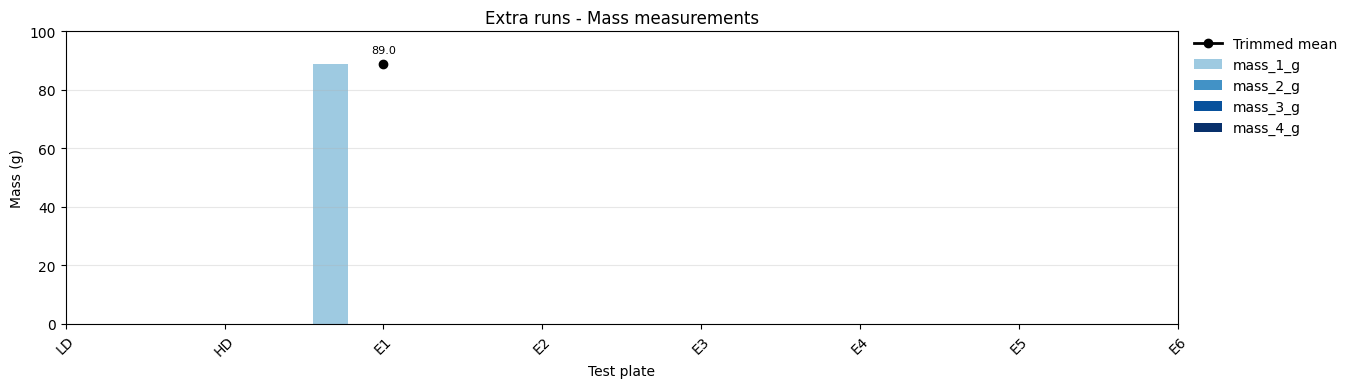

In [52]:
extra_run_mass_measurements_g, extra_run_mass_columns = build_mass_measurements(
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    run_labels=EXTRA_RUN_LABELS,
)

display(extra_run_mass_measurements_g[[
    "run",
    *extra_run_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

plot_mass_measurements(
    extra_run_mass_measurements_g,
    extra_run_mass_columns,
    y_min=0,
    y_max=100,
    mean_label="Trimmed mean",
    experiment="Extra runs",
)

### Box-Behnken Mass Measurements From New Scale


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,B1,89.090,89.100,89.1,0.007071
1,B2,89.015,89.022,89.0,0.004950
2,B3,88.986,88.996,89.0,0.007071
3,B4,89.171,89.183,89.2,0.008485
4,B5,89.313,89.316,89.3,0.002121
5,B6,89.789,89.796,89.8,0.004950
6,B7,89.720,89.730,89.7,0.007071
7,B8,89.306,89.312,89.3,0.004243
8,B9,88.868,88.863,88.9,0.003536
9,B10,89.093,89.105,89.1,0.008485


,runs_with_repeated_measurements,mean_measurement_std_g,rms_measurement_uncertainty_g,max_measurement_std_g
0,15,0.0058,0.0063,0.0092


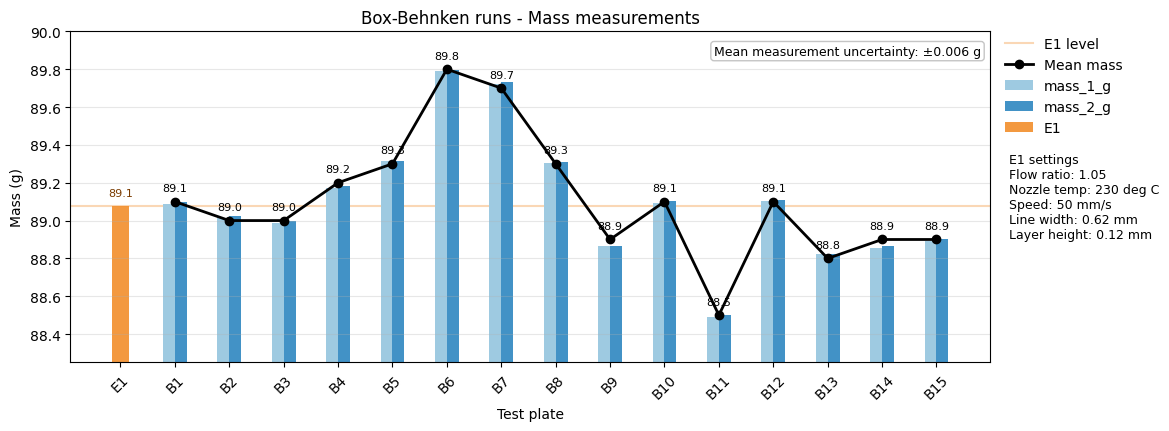

In [53]:
box_behnken_mass_measurements_g, box_behnken_mass_columns = build_mass_measurements(
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    run_labels=BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
)

display(box_behnken_mass_measurements_g[[
    "run",
    *box_behnken_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

box_behnken_repeated_measurements_g = box_behnken_mass_measurements_g.dropna(
    subset=["mass_std_g"]
)
box_behnken_measurement_uncertainty_summary = pd.DataFrame([{
    "runs_with_repeated_measurements": len(box_behnken_repeated_measurements_g),
    "mean_measurement_std_g": box_behnken_repeated_measurements_g["mass_std_g"].mean(),
    "rms_measurement_uncertainty_g": (
        (box_behnken_repeated_measurements_g["mass_std_g"] ** 2).mean() ** 0.5
    ),
    "max_measurement_std_g": box_behnken_repeated_measurements_g["mass_std_g"].max(),
}])
display(box_behnken_measurement_uncertainty_summary.round(4))

e1_reference_mass_g = 89.077

plot_mass_measurements(
    box_behnken_mass_measurements_g,
    box_behnken_mass_columns,
    y_min=88.25,
    y_max=90,
    mean_label="Mean mass",
    experiment="Box-Behnken runs",
    reference_mass_g=e1_reference_mass_g,
    reference_label="E1",
    reference_details=(
        "E1 settings\n"
        "Flow ratio: 1.05\n"
        "Nozzle temp: 230 deg C\n"
        "Speed: 50 mm/s\n"
        "Line width: 0.62 mm\n"
        "Layer height: 0.12 mm"
    ),
)


### FD_II and Box-Behnken Combined Mass Comparison


This plot combines the FD_II RR runs and Box-Behnken runs because they use the same specimen geometry. Only runs with a mean mass above 80 g are included. Box-Behnken error bars show the standard deviation of its repeated scale measurements where available.


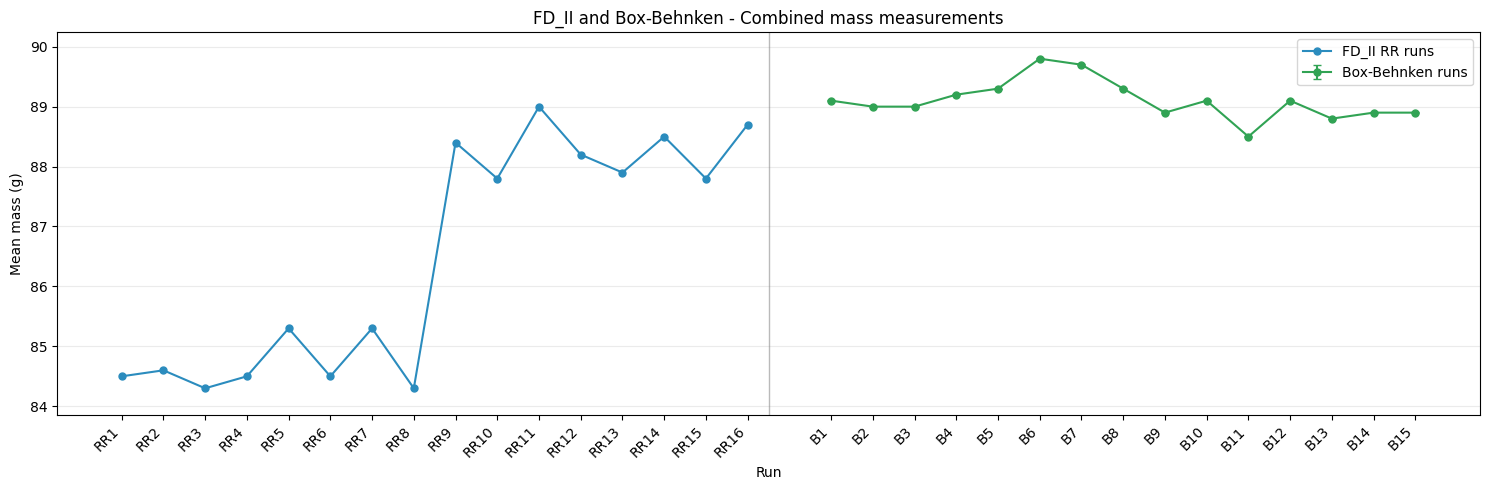

In [54]:
plot_combined_mass_measurement_sets(
    {
        "FD_II RR runs": mass_measurements_g,
        "Box-Behnken runs": box_behnken_mass_measurements_g,
    },
    minimum_mass=80,
    experiment="FD_II and Box-Behnken",
)


## 3) Analysis


### Box-Behnken Response-Surface Analysis


The surface/contour plots visualize the fitted quadratic model. Each figure shows two factors changing across their real setting range while the third factor is held at the middle level. The 3D-style surface shows the predicted mass height; the 2D contour plot is the same surface viewed from above, where contour lines connect settings with equal predicted mass. Red points mark measured runs that lie on that slice.


The Box-Behnken analysis below uses only the new mass measurements. A quadratic response-surface model is fitted as `mass = b0 + b1*x1 + b2*x2 + b3*x3 + b11*x1^2 + b22*x2^2 + b33*x3^2 + b12*x1*x2 + b13*x1*x3 + b23*x2*x3`, where the `x` values are the coded factor levels. The center-point repeats estimate print-to-print repeatability at identical settings.


In [55]:
if "extra_run_15_coded" not in globals():
    extra_run_15_coded, extra_run_15_real = create_box_behnken_design(
        EXTRA_RUN_BOX_BEHNKEN_LEVELS,
        center_repeats=3,
    )

if "box_behnken_mass_measurements_g" not in globals():
    box_behnken_mass_measurements_g, box_behnken_mass_columns = build_mass_measurements(
        BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
        run_labels=BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    )

box_behnken_result_matrix = build_result_matrix(
    extra_run_15_coded,
    box_behnken_mass_measurements_g,
    response="mass_mean_g",
)

display(box_behnken_result_matrix.dropna(subset=["mass_mean_g"]))


,B_nozzle_temp,D_line_width,E_layer_height,mass_mean_g
Run,,,,
1,0,-1,-1,89.1
2,0,-1,1,89.0
3,0,1,-1,89.0
4,0,1,1,89.2
5,-1,0,-1,89.3
6,-1,0,1,89.8
7,1,0,-1,89.7
8,1,0,1,89.3
9,-1,-1,0,88.9


,B_nozzle_temp,D_line_width,E_layer_height,run,mass_mean_g,mass_std_g,difference_from_center_mean_g,abs_difference_from_center_mean_g
Run,,,,,,,,
13,0,0,0,B13,88.8,0.000,-0.067,0.067
14,0,0,0,B14,88.9,0.006,0.033,0.033
15,0,0,0,B15,88.9,0.009,0.033,0.033


,center_repeats_with_data,center_mean_g,between_print_std_g,center_range_g,max_pair_difference_g,max_pair_difference_percent,mean_within_print_std_g
0,3,88.867,0.058,0.1,0.1,0.11,0.005


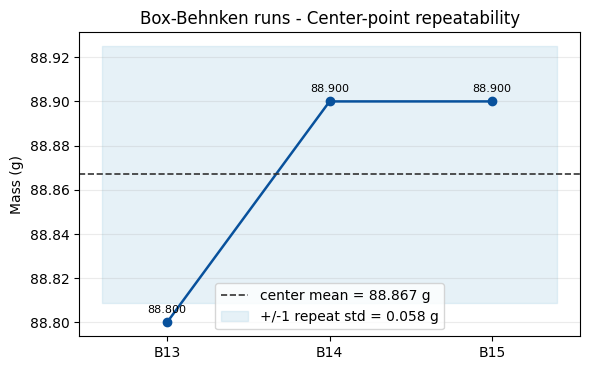

In [56]:
box_behnken_center_repeatability, box_behnken_repeatability_summary = calculate_center_point_repeatability(
    extra_run_15_coded,
    box_behnken_mass_measurements_g,
    response="mass_mean_g",
)

display(box_behnken_center_repeatability)
display(box_behnken_repeatability_summary)

plot_center_point_repeatability(
    box_behnken_center_repeatability,
    box_behnken_repeatability_summary,
    response="mass_mean_g",
    experiment="Box-Behnken runs",
)


The ANOVA table separates the variation explained by the quadratic Box-Behnken model from the unexplained residual variation. The Pareto plot ranks the fitted linear, quadratic, and interaction terms by their absolute standardized effect, so longer bars indicate terms that are more influential relative to the residual scatter.


,measured_runs,model_terms,rank,residual_df,r_squared,residual_std
0,15,10,10,5,0.9482,0.1258


,term,coefficient
0,Intercept,88.8667
1,B_nozzle_temp,-0.0625
2,D_line_width,0.1125
3,E_layer_height,0.0250
4,B_nozzle_temp^2,0.2417
5,D_line_width^2,-0.2083
6,E_layer_height^2,0.4167
7,B_nozzle_temp:D_line_width,0.1000
8,B_nozzle_temp:E_layer_height,-0.2250
9,D_line_width:E_layer_height,0.0750


Quadratic regression model in coded units (-1, 0, +1):
predicted_mass_g = 88.8667 - 0.0625*B_nozzle_temp + 0.1125*D_line_width + 0.0250*E_layer_height + 0.2417*B_nozzle_temp^2 - 0.2083*D_line_width^2 + 0.4167*E_layer_height^2 + 0.1000*B_nozzle_temp*D_line_width - 0.2250*B_nozzle_temp*E_layer_height + 0.0750*D_line_width*E_layer_height
Here B_nozzle_temp, D_line_width, and E_layer_height are coded factor levels; the observed-vs-predicted plot compares measured mass_mean_g with values calculated from this equation.


,run,B_nozzle_temp,D_line_width,E_layer_height,mass_mean_g,predicted_response,residual
Run,,,,,,,
1,1,0,-1,-1,89.1,89.012,0.088
2,2,0,-1,1,89.0,88.912,0.088
3,3,0,1,-1,89.0,89.087,-0.087
4,4,0,1,1,89.2,89.288,-0.087
5,5,-1,0,-1,89.3,89.337,-0.037
6,6,-1,0,1,89.8,89.838,-0.038
7,7,1,0,-1,89.7,89.662,0.038
8,8,1,0,1,89.3,89.262,0.038
9,9,-1,-1,0,88.9,88.950,-0.050


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
6,B_nozzle_temp=0|D_line_width=0|E_layer_height=0,3,88.8667,0.0067,2


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,1,3,0.0067,2,0.0033,0.0577


,error_basis,SS,df,MSE,s
0,regression residual,0.0792,5.0,0.0158,0.1258
1,replicate pure error,0.0067,2.0,0.0033,0.0577


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,9,1.4502,0.1611,10.1766,0.01
1,Residual,5,0.0792,0.0158,NaN,NaN
2,Total,14,1.5293,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,B_nozzle_temp,-0.0625,0.0445,-1.4049,1.9737,0.2190,0.0204,-3.0619,9.3750,0.0922,NaN,NaN,NaN,NaN
2,D_line_width,0.1125,0.0445,2.5288,6.3947,0.0526,0.0204,5.5114,30.3750,0.0314,NaN,NaN,NaN,NaN
3,E_layer_height,0.0250,0.0445,0.5620,0.3158,0.5984,0.0204,1.2247,1.5000,0.3453,NaN,NaN,NaN,NaN
4,B_nozzle_temp^2,0.2417,0.0655,3.6905,13.6194,0.0141,0.0300,8.0432,64.6923,0.0151,NaN,NaN,NaN,NaN
5,D_line_width^2,-0.2083,0.0655,-3.1814,10.1215,0.0245,0.0300,-6.9338,48.0769,0.0202,NaN,NaN,NaN,NaN
6,E_layer_height^2,0.4167,0.0655,6.3628,40.4858,0.0014,0.0300,13.8675,192.3077,0.0052,NaN,NaN,NaN,NaN
7,B_nozzle_temp:D_line_width,0.1000,0.0629,1.5894,2.5263,0.1728,0.0289,3.4641,12.0000,0.0742,NaN,NaN,NaN,NaN
8,B_nozzle_temp:E_layer_height,-0.2250,0.0629,-3.5762,12.7895,0.0159,0.0289,-7.7942,60.7500,0.0161,NaN,NaN,NaN,NaN
9,D_line_width:E_layer_height,0.0750,0.0629,1.1921,1.4211,0.2867,0.0289,2.5981,6.7500,0.1217,NaN,NaN,NaN,NaN


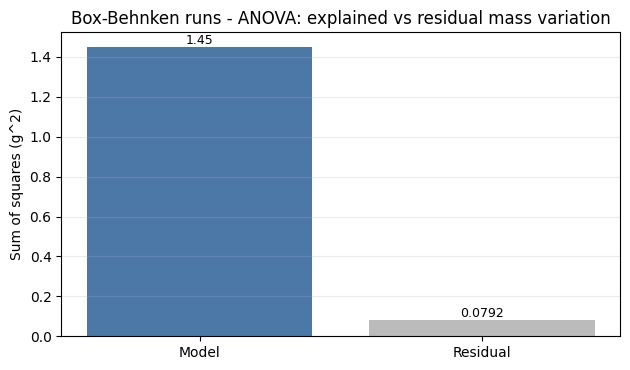

,term,coefficient,standard_error,t_value,absolute_t_value,F_value,p_value
0,Intercept,88.8667,0.0726,1223.2447,1223.2447,1.496328e+06,0.0000
1,B_nozzle_temp,-0.0625,0.0445,-1.4049,1.4049,1.973700e+00,0.2190
2,D_line_width,0.1125,0.0445,2.5288,2.5288,6.394700e+00,0.0526
3,E_layer_height,0.0250,0.0445,0.5620,0.5620,3.158000e-01,0.5984
4,B_nozzle_temp^2,0.2417,0.0655,3.6905,3.6905,1.361940e+01,0.0141
5,D_line_width^2,-0.2083,0.0655,-3.1814,3.1814,1.012150e+01,0.0245
6,E_layer_height^2,0.4167,0.0655,6.3628,6.3628,4.048580e+01,0.0014
7,B_nozzle_temp:D_line_width,0.1000,0.0629,1.5894,1.5894,2.526300e+00,0.1728
8,B_nozzle_temp:E_layer_height,-0.2250,0.0629,-3.5762,3.5762,1.278950e+01,0.0159
9,D_line_width:E_layer_height,0.0750,0.0629,1.1921,1.1921,1.421100e+00,0.2867


In [57]:
box_behnken_mass_model = fit_quadratic_response_surface(
    box_behnken_result_matrix,
    response="mass_mean_g",
)

display(box_behnken_mass_model["info_df"].round(4))
display(box_behnken_mass_model["coefficient_df"].round(4))
print("Quadratic regression model in coded units (-1, 0, +1):")
print(format_quadratic_model_formula(
    box_behnken_mass_model,
    response_label="predicted_mass_g",
    digits=4,
))
print(
    "Here B_nozzle_temp, D_line_width, and E_layer_height are coded factor levels; "
    "the observed-vs-predicted plot compares measured mass_mean_g with values calculated from this equation."
)
display(box_behnken_mass_model["fitted_df"].round(3))

box_behnken_replicate_observations, box_behnken_pure_error_groups, box_behnken_pure_error_summary = (
    calculate_pure_error_from_replicates(
        box_behnken_result_matrix,
        response="mass_mean_g",
        factor_cols=list(EXTRA_RUN_BOX_BEHNKEN_LEVELS),
    )
)
display(box_behnken_pure_error_groups.round(4))
display(box_behnken_pure_error_summary.round(4))
display(build_error_comparison_table(
    box_behnken_mass_model,
    box_behnken_pure_error_summary,
).round(4))

box_behnken_anova_table = build_quadratic_anova_table(box_behnken_mass_model)
display(box_behnken_anova_table.round(4))
display(
    build_term_significance_table(
        box_behnken_mass_model,
        pure_error_summary=box_behnken_pure_error_summary,
    ).round(4)
)
plot_model_anova(
    box_behnken_anova_table,
    response="mass_mean_g",
    experiment="Box-Behnken runs",
)
display(box_behnken_mass_model["term_statistics_df"].round(4))


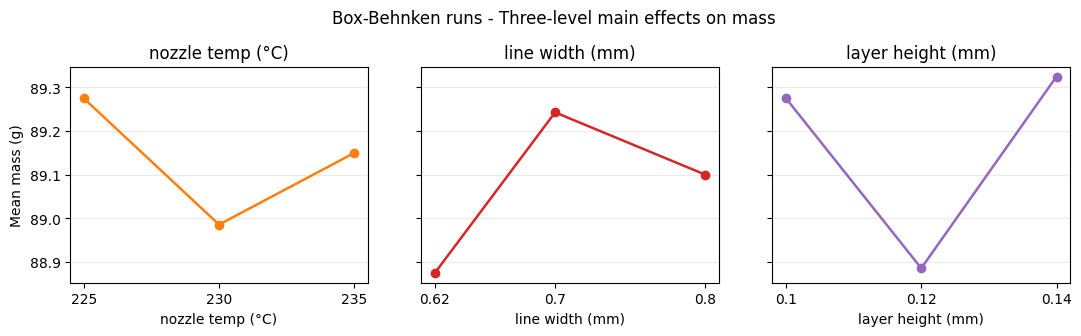

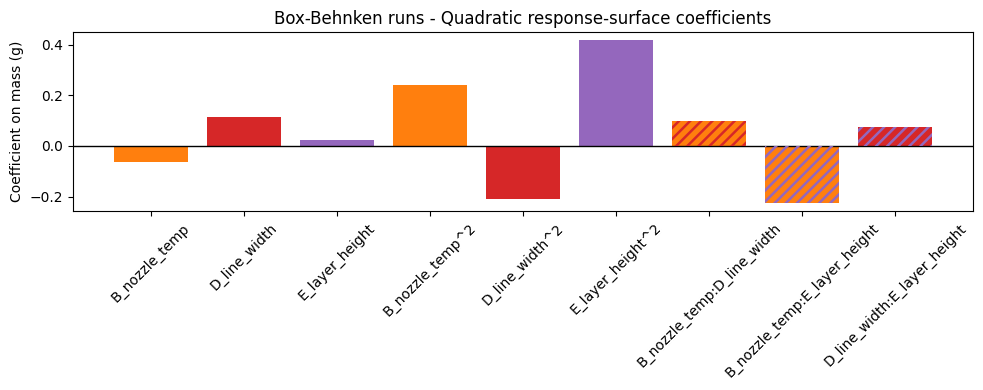

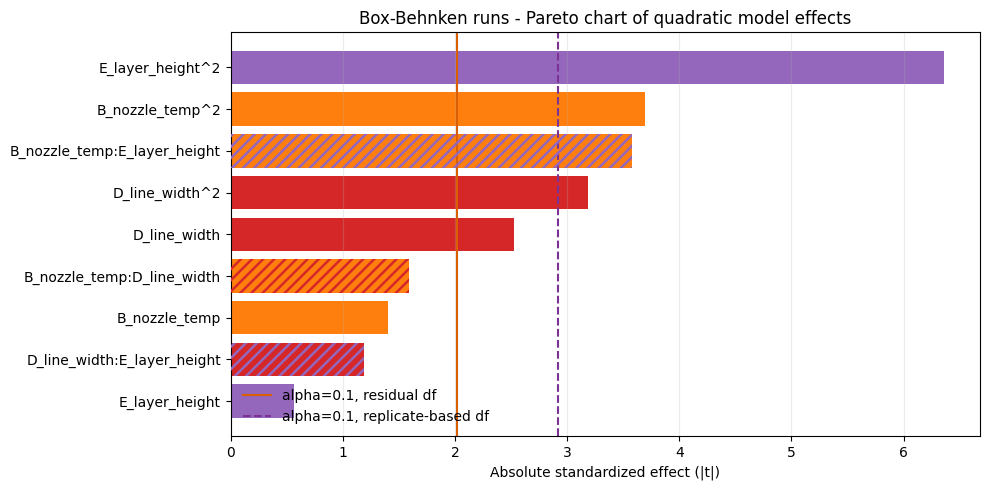

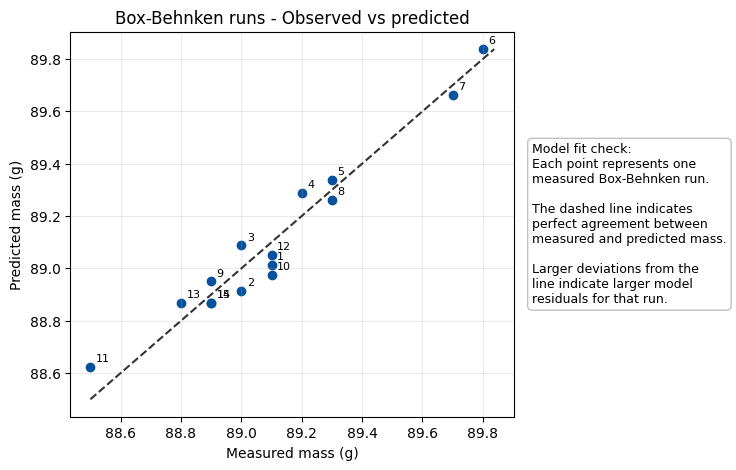

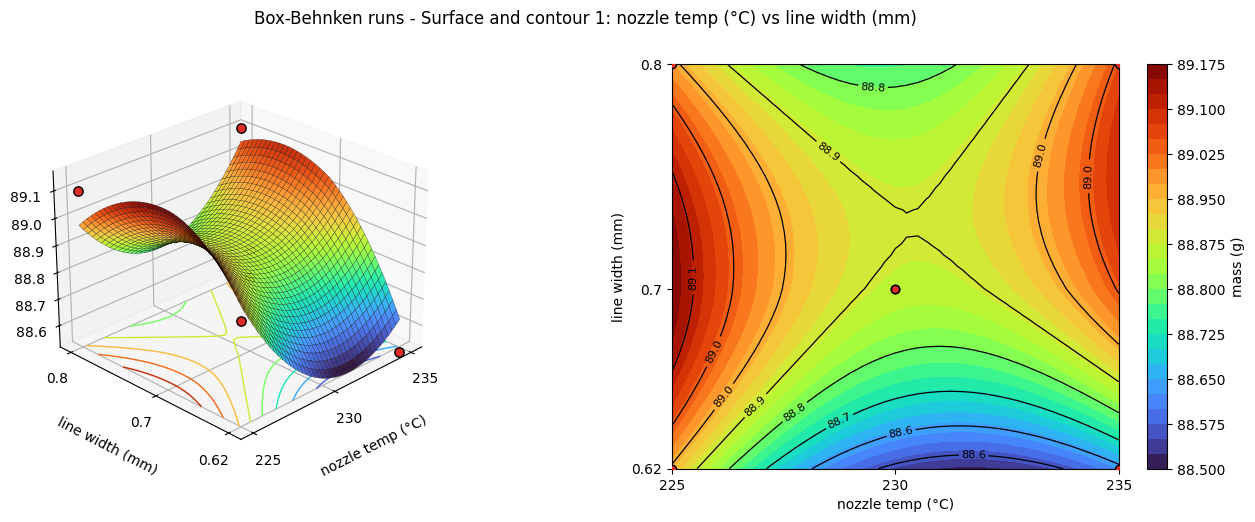

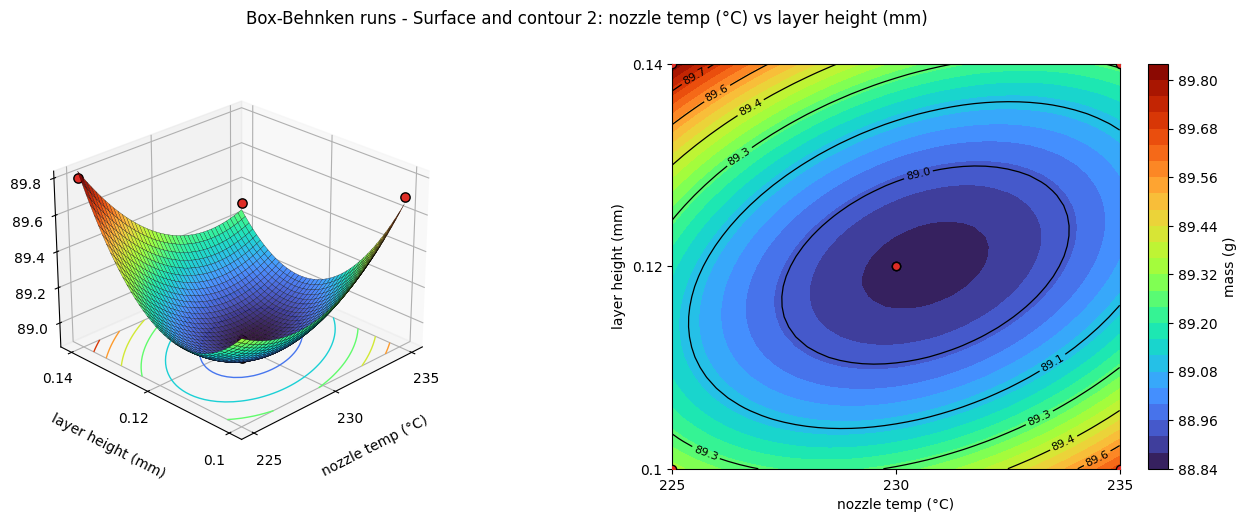

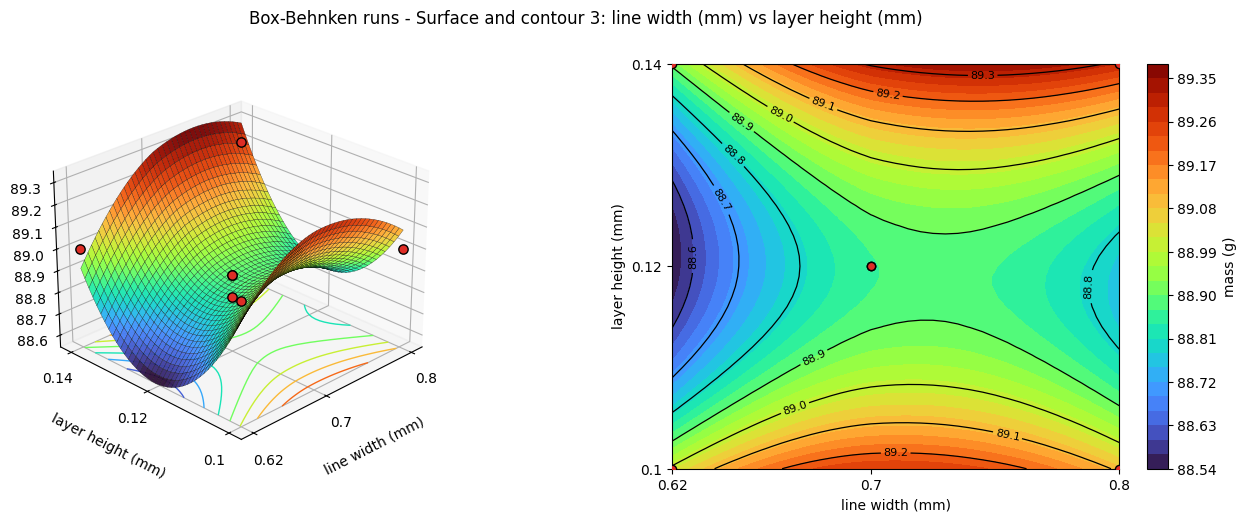

In [58]:
plot_three_level_main_effects(
    box_behnken_result_matrix,
    response="mass_mean_g",
    levels=EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    experiment="Box-Behnken runs",
)

plot_quadratic_coefficients(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_pareto(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
    pure_error_summary=box_behnken_pure_error_summary,
)

plot_quadratic_observed_vs_predicted(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_surface_and_contour_pairs(
    box_behnken_mass_model,
    levels=EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    fixed_level=0,
    experiment="Box-Behnken runs",
)


# IV) Ironing


## 1) DoE Matrix


### Ironing Trial Matrix


In [59]:
# Levels and fixed settings are loaded from the compact experiment dictionaries in ffd_measurements.py.

# 4-factor half-fraction screening design plus center runs.
# Generator: D = A*B*C, so the defining relation is I = A*B*C*D.
# This gives 8 factorial runs + 3 center repeats = 11 runs total.
# Main effects are not aliased with two-factor interactions, but two-factor
# interactions are aliased in pairs: AB=CD, AC=BD, AD=BC.
ironing_base_factors = [
    "A_flow_ratio",
    "B_nozzle_temp_C",
    "C_ironing_flow_percent",
]
ironing_factorial_coded = pd.MultiIndex.from_product(
    [[-1, 1], [-1, 1], [-1, 1]],
    names=ironing_base_factors,
).to_frame(index=False)
ironing_factorial_coded["D_ironing_speed_mm_s"] = (
    ironing_factorial_coded["A_flow_ratio"]
    * ironing_factorial_coded["B_nozzle_temp_C"]
    * ironing_factorial_coded["C_ironing_flow_percent"]
)
ironing_factorial_coded = ironing_factorial_coded[list(IRONING_LEVELS)]

ironing_center_coded = pd.DataFrame([
    {factor: 0 for factor in IRONING_LEVELS}
    for _ in range(3)
])

ironing_coded = pd.concat(
    [ironing_factorial_coded, ironing_center_coded],
    ignore_index=True,
)
ironing_coded.index += 1
ironing_coded.index.name = "Run"

ironing_real = map_coded_to_real(ironing_coded, IRONING_LEVELS)
for setting, value in IRONING_FIXED_SETTINGS.items():
    ironing_real[setting] = value

print(f"Ironing design runs: {len(ironing_coded)}")
display(ironing_coded)
display(ironing_real)


Ironing design runs: 11


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s
Run,,,,
1,-1,-1,-1,-1
2,-1,-1,1,1
3,-1,1,-1,1
4,-1,1,1,-1
5,1,-1,-1,1
6,1,-1,1,-1
7,1,1,-1,-1
8,1,1,1,1
9,0,0,0,0


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,C_ironing_line_spacing_mm,E_layer_height,F_line_width_mm
Run,,,,,,,
1,0.99,215,0,30,0.15,0.12,0.62
2,0.99,215,2,60,0.15,0.12,0.62
3,0.99,225,0,60,0.15,0.12,0.62
4,0.99,225,2,30,0.15,0.12,0.62
5,1.01,215,0,60,0.15,0.12,0.62
6,1.01,215,2,30,0.15,0.12,0.62
7,1.01,225,0,30,0.15,0.12,0.62
8,1.01,225,2,60,0.15,0.12,0.62
9,1.00,220,1,45,0.15,0.12,0.62


## 2) Measurements


### Ironing-Run Mass Measurement Placeholders


Ideal mass for ironing runs: 9.48 g


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,I1,9.452,None,9.45,NaN
1,I2,9.623,None,9.62,NaN
2,I3,9.477,None,9.48,NaN
3,I4,9.537,None,9.54,NaN
4,I5,9.551,None,9.55,NaN
5,I6,9.678,None,9.68,NaN
6,I7,9.558,None,9.56,NaN
7,I8,9.718,None,9.72,NaN
8,I9,9.500,None,9.50,NaN
9,I10,9.477,None,9.48,NaN


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
7,I8.2,9.734,None,9.73,NaN
8,I8.3,9.729,None,9.73,NaN
9,I8.4,9.690,None,9.69,NaN


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,I8.repeat mean,9.717667,NaN,9.72,0.023094


,run_repeat,original_run,original_mass_mean_g,repeat_mass_mean_g,repeat_print_count,difference_g,abs_difference_g,difference_percent
0,I8 repeat print,I8,9.72,9.72,1,0.0,0.0,0.0


Mean absolute repeat difference: 0.000 g


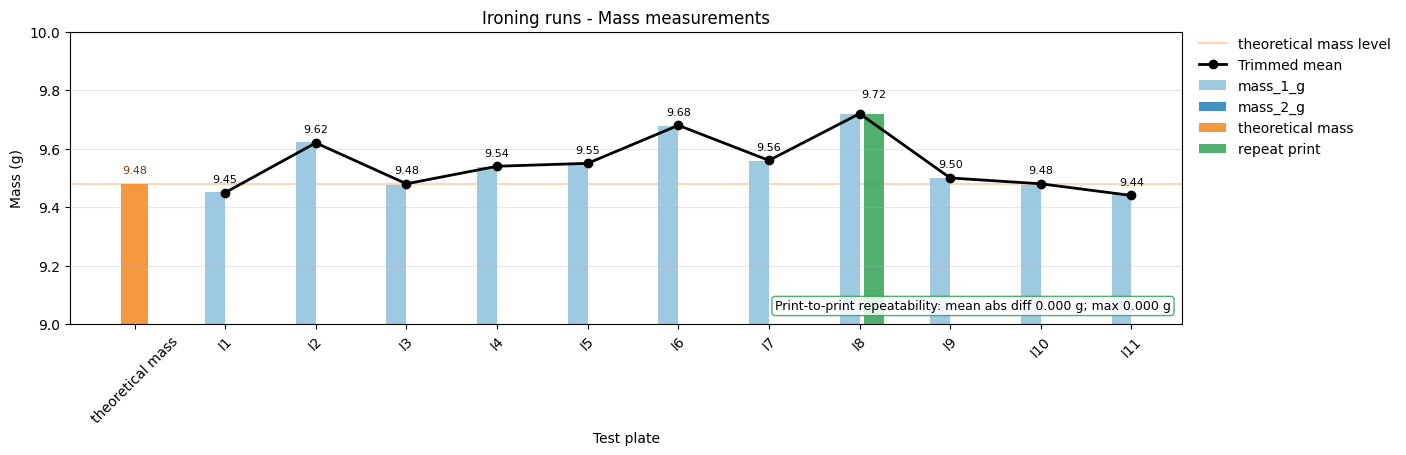

In [60]:
from ffd_utils import ideal_mass_g


ironing_mass_measurements_g, ironing_mass_columns = build_mass_measurements(
    IRONING_MASS_MEASUREMENTS_G,
    run_labels=IRONING_RUN_LABELS,
    mean_round_digits=2,
)
ironing_repeat_mass_measurements_g, ironing_repeat_mass_columns = (
    build_repeat_mass_measurements(
        IRONING_REPEAT_MASS_MEASUREMENTS_G,
        mean_round_digits=2,
    )
)
_ironing_repeat_nonempty = ironing_repeat_mass_measurements_g.dropna(
    subset=["mass_mean_g"]
).copy()
_ironing_repeat_nonempty["original_run"] = (
    _ironing_repeat_nonempty["run"].str.split(".").str[0]
)

# Average multiple repeat prints of the same original run before plotting.
ironing_repeat_mass_plot_g = (
    _ironing_repeat_nonempty
    .groupby("original_run", as_index=False)
    .agg({
        **{column: "mean" for column in ironing_repeat_mass_columns},
        "mass_mean_g": "mean",
    })
)
ironing_repeat_mass_plot_g["run"] = (
    ironing_repeat_mass_plot_g["original_run"] + ".repeat mean"
)
ironing_repeat_mass_plot_g["mass_mean_g"] = (
    ironing_repeat_mass_plot_g["mass_mean_g"].round(2)
)
ironing_repeat_mass_plot_g["mass_std_g"] = (
    _ironing_repeat_nonempty
    .groupby("original_run")["mass_mean_g"]
    .std(ddof=1)
    .reindex(ironing_repeat_mass_plot_g["original_run"])
    .to_numpy()
)
ironing_repeat_mass_plot_g = ironing_repeat_mass_plot_g[[
    "run",
    *ironing_repeat_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]]

ironing_repeatability = calculate_repeatability(
    ironing_mass_measurements_g,
    ironing_repeat_mass_plot_g,
)

volume_ironing_mm3 = 60 * 30 * 4.02
ideal_mass_ironing_g = ideal_mass_g(volume_ironing_mm3, density_g_cm3=1.31)
print(f"Ideal mass for ironing runs: {ideal_mass_ironing_g:.2f} g")

display(ironing_mass_measurements_g[[
    "run",
    *ironing_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])
display(
    ironing_repeat_mass_measurements_g.dropna(subset=["mass_mean_g"])[[
        "run",
        *ironing_repeat_mass_columns,
        "mass_mean_g",
        "mass_std_g",
    ]]
)
display(ironing_repeat_mass_plot_g)
display(ironing_repeatability)
if not ironing_repeatability.empty:
    print(
        "Mean absolute repeat difference:",
        f"{ironing_repeatability['abs_difference_g'].mean():.3f} g",
    )

plot_mass_measurements(
    ironing_mass_measurements_g,
    ironing_mass_columns,
    y_min=9,
    y_max=10,
    mean_label="Trimmed mean",
    experiment="Ironing runs",
    repeat_measurements_g=ironing_repeat_mass_plot_g,
    repeat_bar_offset=0.16,
    reference_mass_g=ideal_mass_ironing_g,
    reference_label="theoretical mass",
    value_digits=2,
)


### Ironing Confirmation-Run Mass Measurements


,run,mass_1_g,mass_mean_g,mass_std_g
0,IA,9.650,9.650,<NA>
1,IB,9.627,9.627,<NA>
2,I8-lowT,9.670,9.670,<NA>
3,I8-medT,9.656,9.656,<NA>
4,I8-T1,9.753,9.753,<NA>
5,I8-T2,9.735,9.735,<NA>
6,I8-T3,9.688,9.688,<NA>


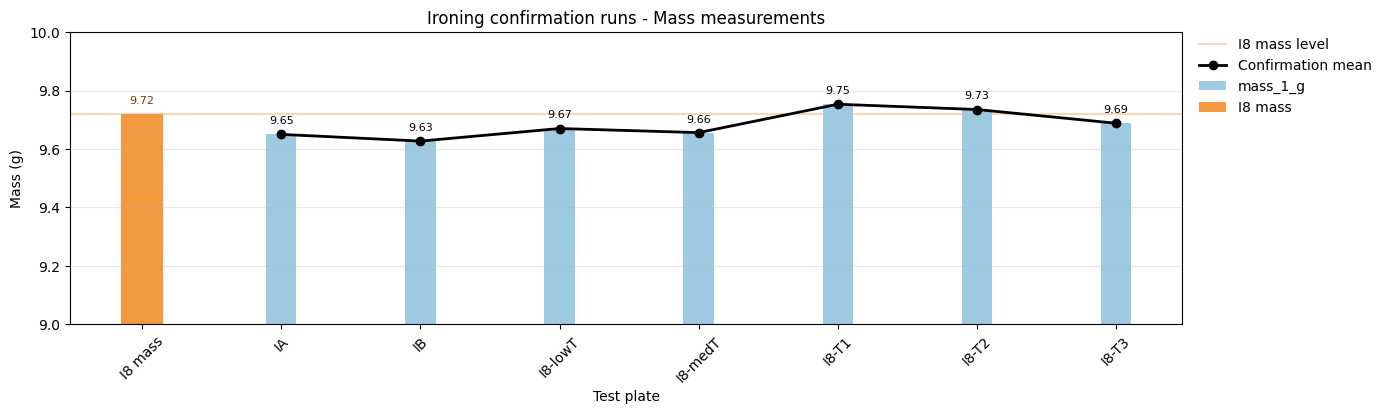

In [61]:
ironing_confirmation_mass_measurements_g = pd.DataFrame(
    IRONING_CONFIRMATION_RUNS
)[["run", "mass_mean_g"]].copy()
ironing_confirmation_mass_measurements_g["mass_1_g"] = (
    ironing_confirmation_mass_measurements_g["mass_mean_g"]
)
ironing_confirmation_mass_measurements_g["mass_std_g"] = pd.NA

i8_reference_mass_g = ironing_mass_measurements_g.loc[
    ironing_mass_measurements_g["run"] == "I8",
    "mass_mean_g",
].iloc[0]

display(ironing_confirmation_mass_measurements_g[[
    "run",
    "mass_1_g",
    "mass_mean_g",
    "mass_std_g",
]])
plot_mass_measurements(
    ironing_confirmation_mass_measurements_g,
    ["mass_1_g"],
    y_min=9,
    y_max=10,
    mean_label="Confirmation mean",
    experiment="Ironing confirmation runs",
    reference_mass_g=i8_reference_mass_g,
    reference_label="I8 mass",
    value_digits=2,
)


### Ironing Confirmation Runs


The confirmation and optimization runs are additional checks at selected settings. They are appended to an augmented ironing matrix and included in the mass-quality/desirability comparison where matching measurements are available. The original I1-I11 rows are still used alone to estimate the planned half-fraction effects, while confirmation runs remain independent checks of those estimates.


In [62]:
ironing_confirmation_runs = pd.DataFrame(IRONING_CONFIRMATION_RUNS)
display(ironing_confirmation_runs)


,run,mass_g,responses,coded_parameters,parameters,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,C_ironing_line_spacing_mm,E_layer_height,F_line_width_mm,visual_defects,has_stringing,quality_score,notes,mass_mean_g,extra_extrusion
0,IA,[9.65],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': False, '...",False,2.5,,9.650,NaN
1,IB,[9.627],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,45,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,8.0,,9.627,NaN
2,I8-lowT,[9.67],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 215,...",1.01,215,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': None, 'q...",NaN,NaN,,9.670,NaN
3,I8-medT,[9.656],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': None, 'q...",NaN,NaN,,9.656,NaN
4,I8-T1,[9.753],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 225,...",1.01,225,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,8.0,,9.753,True
5,I8-T2,[9.735],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 215,...",1.01,215,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,15.0,,9.735,True
6,I8-T3,[9.688],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 225,...",1.01,225,2,45,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': False, '...",False,8.0,,9.688,True


### Ironing Visual Quality Measurements


Blob count and stringing are treated as a second response. The visual quality score is calculated as `blob count + stringing penalty`; lower values are better. The default stringing penalty is 5, so one stringing observation is treated like five additional blobs. Change `STRINGING_PENALTY` if this weighting feels too strong or too weak.


,run,blob_count,has_stringing,stringing_penalty,quality_score
0,I1,7,False,0,7
1,I2,11,False,0,11
2,I3,2,False,0,2
3,I4,3,False,0,3
4,I5,6,False,0,6
5,I6,10,True,5,15
6,I7,1,False,0,1
7,I8,1,False,0,1
8,I9,2,False,0,2
9,I10,2,False,0,2


,run,blob_count,has_stringing,stringing_penalty,quality_score
0,I8.2,2,False,0,2


,run,repeat_quality_score,original_run,original_quality_score,difference,abs_difference
0,I8.2,2,I8,1,1,1


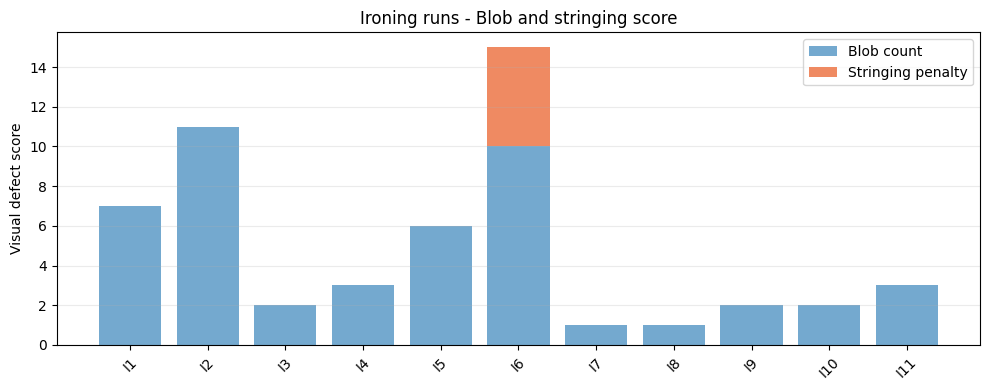

In [63]:
STRINGING_PENALTY = 5

ironing_quality_table = build_ironing_quality_table(
    IRONING_BLOB_COUNTS,
    run_labels=IRONING_RUN_LABELS,
    stringing_runs=IRONING_STRINGING_RUNS,
    stringing_penalty=STRINGING_PENALTY,
)
ironing_repeat_quality_table = build_ironing_quality_table(
    IRONING_REPEAT_BLOB_COUNTS,
    stringing_runs=IRONING_REPEAT_STRINGING_RUNS,
    stringing_penalty=STRINGING_PENALTY,
)

ironing_quality_repeatability = calculate_score_repeatability(
    ironing_quality_table,
    ironing_repeat_quality_table,
    score_col="quality_score",
)

display(ironing_quality_table)
display(ironing_repeat_quality_table)
display(ironing_quality_repeatability)
plot_quality_counts(ironing_quality_table, experiment="Ironing runs")


### Ironing Confirmation-Run Visual Quality


,run,blob_count,has_stringing,stringing_penalty,quality_score
0,IA,2.5,False,0,2.5
1,IB,3.0,True,5,8.0
2,I8-T1,3.0,True,5,8.0
3,I8-T2,10.0,True,5,15.0
4,I8-T3,8.0,False,0,8.0


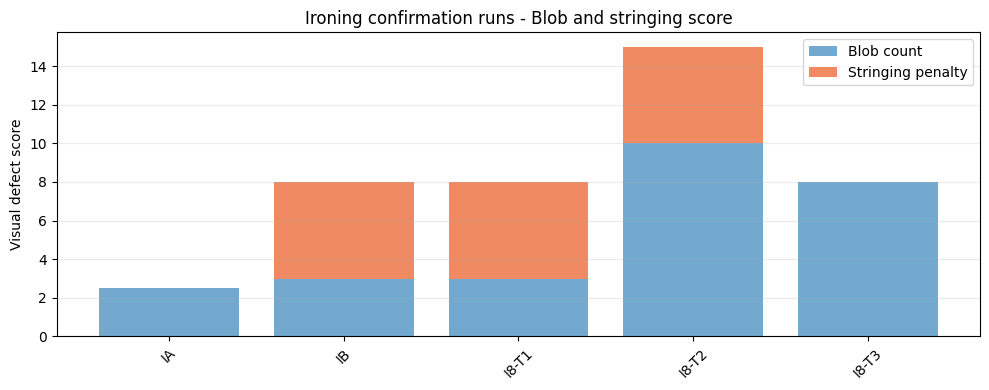

In [64]:
ironing_confirmation_quality_table = pd.DataFrame(
    IRONING_CONFIRMATION_RUNS
)[["run", "quality_score", "has_stringing"]].copy()
ironing_confirmation_quality_table = (
    ironing_confirmation_quality_table
    .dropna(subset=["quality_score"])
    .reset_index(drop=True)
)
ironing_confirmation_quality_table["stringing_penalty"] = (
    ironing_confirmation_quality_table["has_stringing"]
    .fillna(False)
    .astype(bool)
    .map({True: STRINGING_PENALTY, False: 0})
)
ironing_confirmation_quality_table["blob_count"] = (
    ironing_confirmation_quality_table["quality_score"]
    - ironing_confirmation_quality_table["stringing_penalty"]
)
ironing_confirmation_quality_table["blob_count"] = (
    ironing_confirmation_quality_table["blob_count"].clip(lower=0)
)

display(ironing_confirmation_quality_table[[
    "run",
    "blob_count",
    "has_stringing",
    "stringing_penalty",
    "quality_score",
]])
plot_quality_counts(
    ironing_confirmation_quality_table,
    experiment="Ironing confirmation runs",
)


In [65]:
ironing_design_tradeoff = build_mass_quality_tradeoff(
    ironing_mass_measurements_g,
    ironing_quality_table,
    target_mass_g=ideal_mass_ironing_g,
    mass_weight=0.5,
    quality_weight=0.5,
)

ironing_confirmation_tradeoff = ironing_confirmation_runs[[
    "run",
    "mass_mean_g",
    "quality_score",
    "has_stringing",
]].copy()
ironing_confirmation_tradeoff["blob_count"] = pd.NA

ironing_mass_quality_tradeoff = pd.concat(
    [ironing_design_tradeoff, ironing_confirmation_tradeoff],
    ignore_index=True,
    sort=False,
)

display(ironing_mass_quality_tradeoff[[
    "run",
    "mass_mean_g",
    "quality_score",
    "has_stringing",
]].round(3))


,run,mass_mean_g,quality_score,has_stringing
0,I10,9.480,2.0,False
1,I3,9.480,2.0,False
2,I9,9.500,2.0,False
3,I11,9.440,3.0,False
4,I7,9.560,1.0,False
5,I4,9.540,3.0,False
6,I1,9.450,7.0,False
7,I5,9.550,6.0,False
8,I8,9.720,1.0,False
9,I2,9.620,11.0,False


## 3) Analysis


### Ironing Screening Analysis


This analysis uses the measured ironing runs to estimate the main effects and the aliased interaction pairs from the half-fraction design. A positive main effect means the response increases when the factor moves from its low coded level (-1) to its high coded level (+1); a negative main effect means the response decreases. The three center runs I9-I11 are still used separately for repeatability and overall curvature. A full quadratic response surface is not estimable from this 11-run, 4-factor half fraction: it would require 15 coefficients, and the individual squared terms are aliased in a two-level design. The center-point check below can detect only combined curvature, not which factor causes it.


In [66]:
ironing_result_matrix = build_result_matrix(
    ironing_coded,
    ironing_mass_measurements_g,
    response="mass_mean_g",
)

ironing_result_matrix_with_data = ironing_result_matrix.dropna(
    subset=["mass_mean_g"]
)
print(
    f"Available ironing measurements: "
    f"{len(ironing_result_matrix_with_data)}/{len(ironing_result_matrix)}"
)
display(ironing_result_matrix_with_data)

ironing_level_coverage = build_factor_level_coverage(
    ironing_result_matrix,
    response="mass_mean_g",
    factor_cols=list(IRONING_LEVELS),
)
display(
    ironing_level_coverage.pivot(
        index="factor",
        columns="coded_level",
        values="available_runs",
    ).rename(columns={-1: "low (-1)", 0: "center (0)", 1: "high (+1)"})
)


Available ironing measurements: 11/11


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g
Run,,,,,
1,-1,-1,-1,-1,9.45
2,-1,-1,1,1,9.62
3,-1,1,-1,1,9.48
4,-1,1,1,-1,9.54
5,1,-1,-1,1,9.55
6,1,-1,1,-1,9.68
7,1,1,-1,-1,9.56
8,1,1,1,1,9.72
9,0,0,0,0,9.50


coded_level,low (-1),center (0),high (+1)
factor,,,
A_flow_ratio,4,3,4
B_nozzle_temp_C,4,3,4
C_ironing_flow_percent,4,3,4
D_ironing_speed_mm_s,4,3,4


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,11,5,5,True,6,0.6841,0.067


,term,coefficient,effect,standard_error,t_value,F_value,p_value
0,Intercept,9.5473,9.5473,0.0202,472.7466,223489.3698,0.0000
1,A_flow_ratio,0.0525,0.1050,0.0237,2.2170,4.9149,0.0685
2,B_nozzle_temp_C,0.0000,0.0000,0.0237,0.0000,0.0000,1.0000
3,C_ironing_flow_percent,0.0650,0.1300,0.0237,2.7448,7.5339,0.0335
4,D_ironing_speed_mm_s,0.0175,0.0350,0.0237,0.7390,0.5461,0.4878


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g,predicted_response,residual
Run,,,,,,,
1,-1,-1,-1,-1,9.45,9.412,0.038
2,-1,-1,1,1,9.62,9.577,0.043
3,-1,1,-1,1,9.48,9.447,0.033
4,-1,1,1,-1,9.54,9.542,-0.002
5,1,-1,-1,1,9.55,9.552,-0.002
6,1,-1,1,-1,9.68,9.647,0.033
7,1,1,-1,-1,9.56,9.517,0.043
8,1,1,1,1,9.72,9.682,0.038
9,0,0,0,0,9.50,9.547,-0.047


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
4,A_flow_ratio=0|B_nozzle_temp_C=0|C_ironing_flo...,3,9.4733,0.0019,2
8,A_flow_ratio=1|B_nozzle_temp_C=1|C_ironing_flo...,4,9.7175,0.0011,3


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,2,7,0.0029,5,0.0006,0.0243


,error_basis,SS,df,MSE,s
0,regression residual,0.0269,6.0,0.0045,0.0670
1,replicate pure error,0.0029,5.0,0.0006,0.0243


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,4,0.0583,0.0146,3.2487,0.0962
1,Residual,6,0.0269,0.0045,NaN,NaN
2,Total,10,0.0852,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.0525,0.0237,2.2170,4.9149,0.0685,0.0086,6.1220,37.4788,0.0017,NaN,NaN,NaN,NaN
2,B_nozzle_temp_C,0.0000,0.0237,0.0000,0.0000,1.0000,0.0086,0.0000,0.0000,1.0000,NaN,NaN,NaN,NaN
3,C_ironing_flow_percent,0.0650,0.0237,2.7448,7.5339,0.0335,0.0086,7.5796,57.4504,0.0006,NaN,NaN,NaN,NaN
4,D_ironing_speed_mm_s,0.0175,0.0237,0.7390,0.5461,0.4878,0.0086,2.0407,4.1643,0.0968,NaN,NaN,NaN,NaN


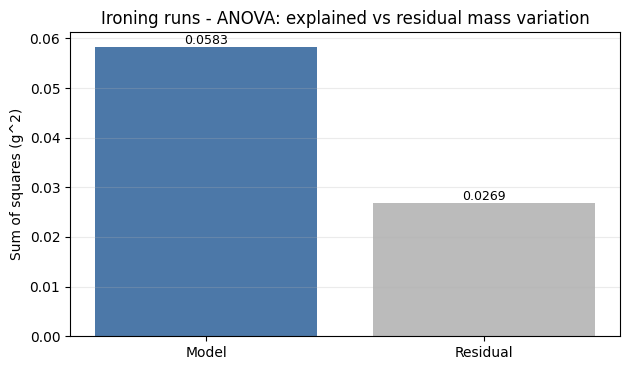

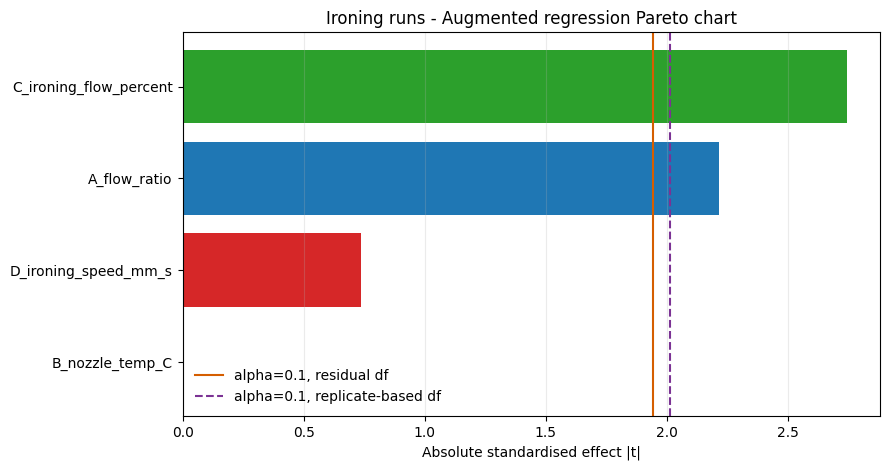

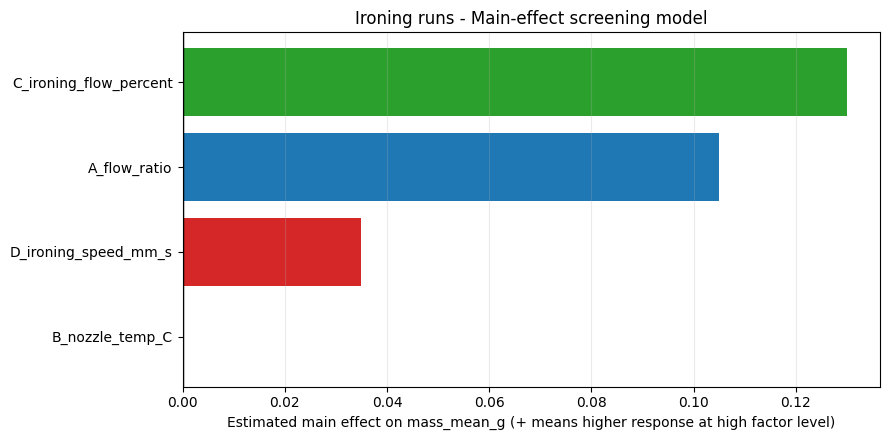

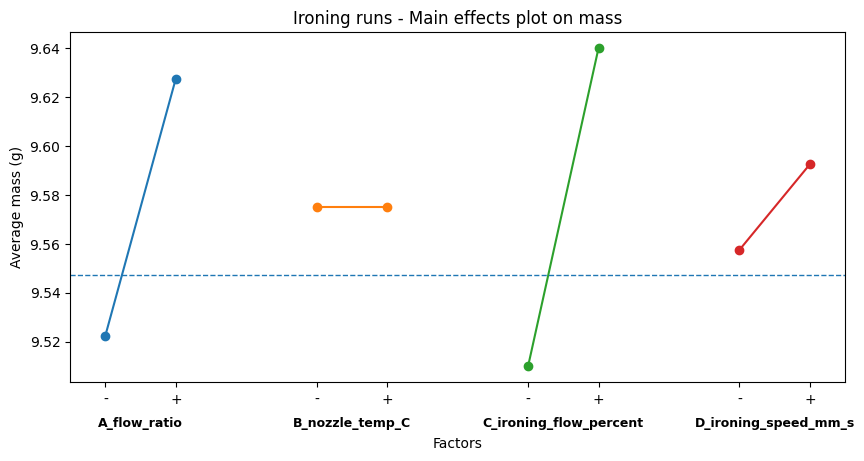

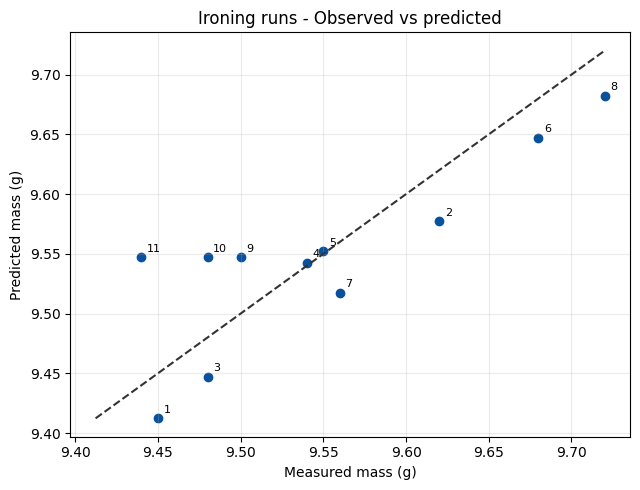

In [67]:
ironing_main_effect_model = fit_main_effect_screening_model(
    ironing_result_matrix,
    response="mass_mean_g",
    factor_cols=list(IRONING_LEVELS),
)

display(ironing_main_effect_model["info_df"].round(4))
display(ironing_main_effect_model["statistics_df"].round(4))
display(ironing_main_effect_model["fitted_df"].round(3))
ironing_mass_replicate_observations, ironing_mass_pure_error_groups, ironing_mass_pure_error_summary = (
    calculate_pure_error_from_replicates(
        ironing_result_matrix,
        response="mass_mean_g",
        factor_cols=list(IRONING_LEVELS),
        repeat_measurements_g=ironing_repeat_mass_measurements_g,
    )
)
display(ironing_mass_pure_error_groups.round(4))
display(ironing_mass_pure_error_summary.round(4))
display(build_error_comparison_table(
    ironing_main_effect_model,
    ironing_mass_pure_error_summary,
).round(4))
ironing_mass_anova_table = build_model_anova_table(ironing_main_effect_model)
display(ironing_mass_anova_table.round(4))
display(
    build_term_significance_table(
        ironing_main_effect_model,
        pure_error_summary=ironing_mass_pure_error_summary,
    ).round(4)
)
plot_model_anova(
    ironing_mass_anova_table,
    response="mass_mean_g",
    experiment="Ironing runs",
)

if ironing_main_effect_model["info_df"].loc[0, "full_rank"]:
    plot_augmented_model_pareto(
        ironing_main_effect_model,
        experiment="Ironing runs",
        pure_error_summary=ironing_mass_pure_error_summary,
    )
    plot_screening_model_effects(
        ironing_main_effect_model,
        experiment="Ironing runs",
    )
    plot_main_effects_line(
        ironing_result_matrix_with_data,
        response="mass_mean_g",
        experiment="Ironing runs",
    )
    plot_screening_observed_vs_predicted(
        ironing_main_effect_model,
        experiment="Ironing runs",
    )
else:
    print(
        "The available measurements do not yet provide a full-rank main-effects model. "
        "Add runs with missing factor-level combinations."
    )


#### IA and IB Confirmation-Run Comparison


The fitted ironing main-effect model predicts IA and IB from their coded settings. `prediction_error = observed mass - predicted mass`; a small absolute error supports the additive model at these mixed-level settings. IB stringing is retained as a qualitative warning and is not converted into a blob score because no blob count was supplied.


In [68]:
ironing_confirmation_comparison = build_screening_confirmation_comparison(
    ironing_main_effect_model,
    ironing_confirmation_runs,
    IRONING_LEVELS,
    response="mass_mean_g",
)

display(ironing_confirmation_comparison.round(3))
# Append confirmation runs for comparison and future augmented modeling.
ironing_design_matrix_labeled = ironing_result_matrix.copy()
ironing_design_matrix_labeled.insert(0, "run", IRONING_RUN_LABELS)
ironing_design_matrix_labeled["quality_score"] = ironing_quality_table[
    "quality_score"
].to_numpy()
ironing_design_matrix_labeled["has_stringing"] = ironing_quality_table[
    "has_stringing"
].to_numpy()
ironing_design_matrix_labeled["design_role"] = "original half-fraction / center"

ironing_confirmation_matrix = pd.DataFrame({
    "run": ironing_confirmation_comparison["run"],
    **{
        factor: ironing_confirmation_comparison[f"{factor}_coded"]
        for factor in IRONING_LEVELS
    },
    "mass_mean_g": ironing_confirmation_comparison["mass_mean_g"],
    "quality_score": ironing_confirmation_comparison["quality_score"],
    "has_stringing": ironing_confirmation_comparison["has_stringing"],
    "design_role": "additional confirmation",
})

ironing_augmented_matrix = pd.concat(
    [ironing_design_matrix_labeled, ironing_confirmation_matrix],
    ignore_index=True,
    sort=False,
)
display(ironing_augmented_matrix)


,run,mass_g,responses,coded_parameters,parameters,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,C_ironing_line_spacing_mm,E_layer_height,F_line_width_mm,visual_defects,has_stringing,quality_score,notes,mass_mean_g,extra_extrusion,A_flow_ratio_coded,B_nozzle_temp_C_coded,C_ironing_flow_percent_coded,D_ironing_speed_mm_s_coded,predicted_response,prediction_error,abs_prediction_error
0,IA,[9.65],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': False, '...",False,2.5,,9.650,NaN,1.0,0.0,1.0,1.0,9.682,-0.032,0.032
1,IB,[9.627],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,45,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,8.0,,9.627,NaN,1.0,0.0,1.0,0.0,9.665,-0.038,0.038
2,I8-lowT,[9.67],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 215,...",1.01,215,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': None, 'q...",NaN,NaN,,9.670,NaN,1.0,-1.0,1.0,1.0,9.682,-0.012,0.012
3,I8-medT,[9.656],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': None, 'q...",NaN,NaN,,9.656,NaN,1.0,0.0,1.0,1.0,9.682,-0.026,0.026
4,I8-T1,[9.753],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 225,...",1.01,225,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,8.0,,9.753,True,1.0,1.0,1.0,1.0,9.682,0.071,0.071
5,I8-T2,[9.735],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 215,...",1.01,215,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,15.0,,9.735,True,1.0,-1.0,1.0,1.0,9.682,0.053,0.053
6,I8-T3,[9.688],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 225,...",1.01,225,2,45,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': False, '...",False,8.0,,9.688,True,1.0,1.0,1.0,0.0,9.665,0.023,0.023


,run,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g,quality_score,has_stringing,design_role
0,I1,-1.0,-1.0,-1.0,-1.0,9.450,7.0,False,original half-fraction / center
1,I2,-1.0,-1.0,1.0,1.0,9.620,11.0,False,original half-fraction / center
2,I3,-1.0,1.0,-1.0,1.0,9.480,2.0,False,original half-fraction / center
3,I4,-1.0,1.0,1.0,-1.0,9.540,3.0,False,original half-fraction / center
4,I5,1.0,-1.0,-1.0,1.0,9.550,6.0,False,original half-fraction / center
5,I6,1.0,-1.0,1.0,-1.0,9.680,15.0,True,original half-fraction / center
6,I7,1.0,1.0,-1.0,-1.0,9.560,1.0,False,original half-fraction / center
7,I8,1.0,1.0,1.0,1.0,9.720,1.0,False,original half-fraction / center
8,I9,0.0,0.0,0.0,0.0,9.500,2.0,False,original half-fraction / center
9,I10,0.0,0.0,0.0,0.0,9.480,2.0,False,original half-fraction / center


#### Ironing Visual-Quality Screening


This repeats the same screening analysis with `quality_score` as the response. For this response, positive effects are unfavorable because they mean more blobs/stringing at the high factor level; negative effects are favorable because they reduce the defect score.


The combined optimization below uses the weighted geometric mean of two desirabilities: mass is higher-is-better and visual defect score is lower-is-better. With equal weights, `D = sqrt(d_mass * d_quality)`. A zero desirability for either response makes the overall desirability zero. The current limits use the observed minimum and maximum and should later be replaced by engineering acceptance limits if available.


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,quality_score
Run,,,,,
1,-1,-1,-1,-1,7
2,-1,-1,1,1,11
3,-1,1,-1,1,2
4,-1,1,1,-1,3
5,1,-1,-1,1,6
6,1,-1,1,-1,15
7,1,1,-1,-1,1
8,1,1,1,1,1
9,0,0,0,0,2


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,11,5,5,True,6,0.7561,2.9051


,term,coefficient,effect,standard_error,t_value,F_value,p_value
0,Intercept,4.8182,4.8182,0.8759,5.5008,30.2585,0.0015
1,A_flow_ratio,0.0000,0.0000,1.0271,0.0000,0.0000,1.0000
2,B_nozzle_temp_C,-4.0000,-8.0000,1.0271,-3.8945,15.1670,0.0080
3,C_ironing_flow_percent,1.7500,3.5000,1.0271,1.7038,2.9031,0.1393
4,D_ironing_speed_mm_s,-0.7500,-1.5000,1.0271,-0.7302,0.5332,0.4928


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,quality_score,predicted_response,residual
Run,,,,,,,
1,-1,-1,-1,-1,7,7.818,-0.818
2,-1,-1,1,1,11,9.818,1.182
3,-1,1,-1,1,2,-1.682,3.682
4,-1,1,1,-1,3,3.318,-0.318
5,1,-1,-1,1,6,6.318,-0.318
6,1,-1,1,-1,15,11.318,3.682
7,1,1,-1,-1,1,-0.182,1.182
8,1,1,1,1,1,1.818,-0.818
9,0,0,0,0,2,4.818,-2.818


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
4,A_flow_ratio=0|B_nozzle_temp_C=0|C_ironing_flo...,3,2.3333,0.6667,2
8,A_flow_ratio=1|B_nozzle_temp_C=1|C_ironing_flo...,2,1.5000,0.5000,1


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,2,5,1.1667,3,0.3889,0.6236


,error_basis,SS,df,MSE,s
0,regression residual,50.6364,6.0,8.4394,2.9051
1,replicate pure error,1.1667,3.0,0.3889,0.6236


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,4,157.0000,39.2500,4.6508,0.0474
1,Residual,6,50.6364,8.4394,NaN,NaN
2,Total,10,207.6364,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.00,1.0271,0.0000,0.0000,1.0000,0.2205,0.0000,0.0000,1.0000,NaN,NaN,NaN,NaN
2,B_nozzle_temp_C,-4.00,1.0271,-3.8945,15.1670,0.0080,0.2205,-18.1423,329.1429,0.0004,NaN,NaN,NaN,NaN
3,C_ironing_flow_percent,1.75,1.0271,1.7038,2.9031,0.1393,0.2205,7.9373,63.0000,0.0042,NaN,NaN,NaN,NaN
4,D_ironing_speed_mm_s,-0.75,1.0271,-0.7302,0.5332,0.4928,0.2205,-3.4017,11.5714,0.0424,NaN,NaN,NaN,NaN


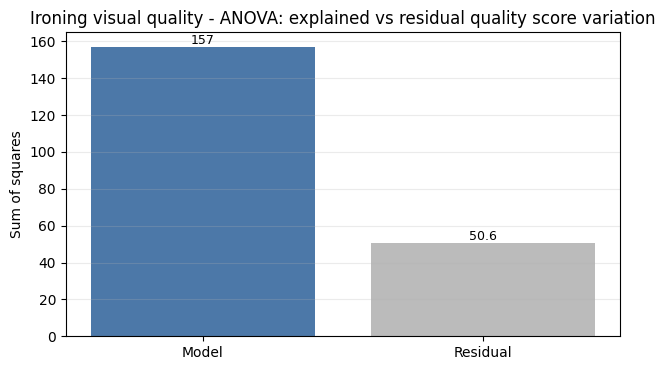

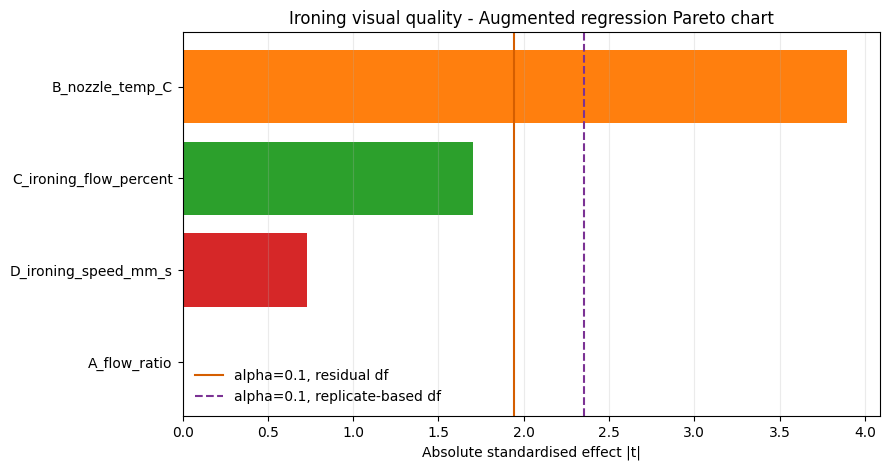

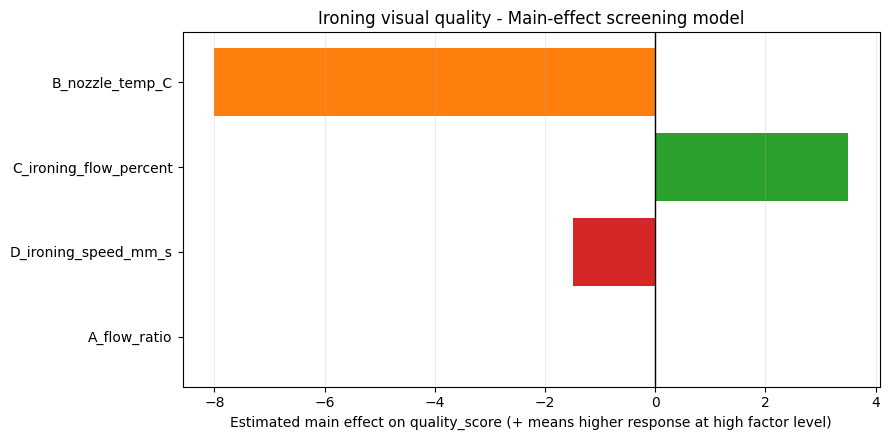

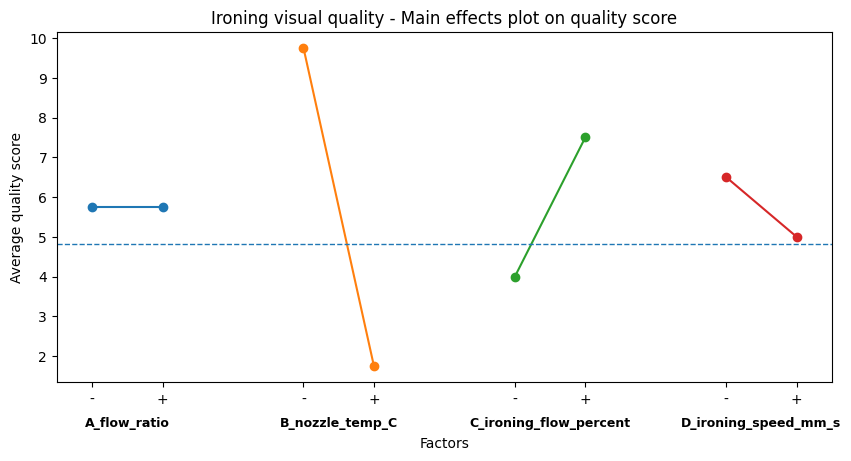

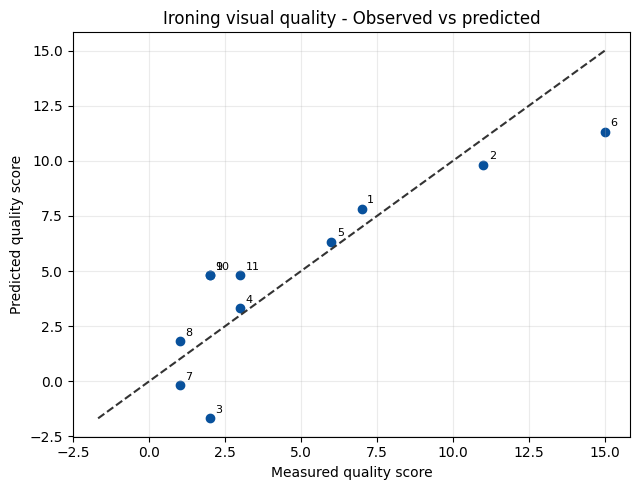

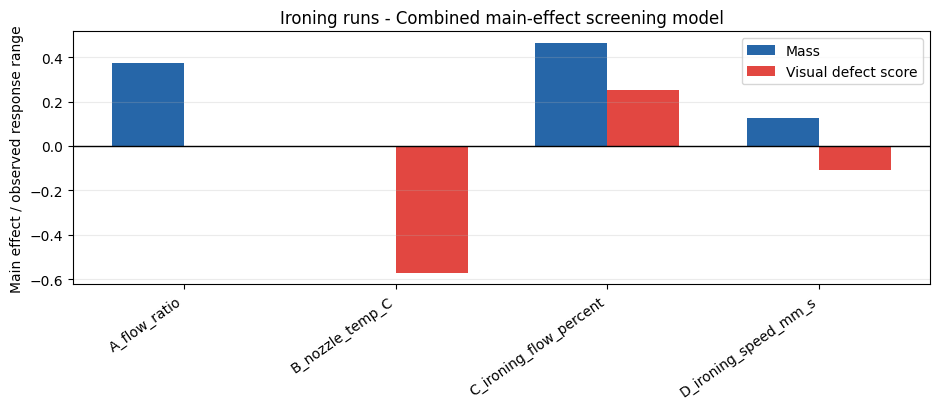

,run,mass_mean_g,quality_score,mass_desirability,quality_desirability,overall_desirability,desirability_rank
8,I8,9.720,1.0,0.895,1.000,0.946,1.0
11,IA,9.650,2.5,0.671,0.893,0.774,2.0
15,I8-T1,9.753,8.0,1.000,0.500,0.707,3.0
17,I8-T3,9.688,8.0,0.792,0.500,0.629,4.0
4,I7,9.560,1.0,0.383,1.000,0.619,5.0
12,IB,9.627,8.0,0.597,0.500,0.547,6.0
5,I4,9.540,3.0,0.319,0.857,0.523,7.0
7,I5,9.550,6.0,0.351,0.643,0.475,8.0
2,I9,9.500,2.0,0.192,0.929,0.422,9.0
9,I2,9.620,11.0,0.575,0.286,0.405,10.0


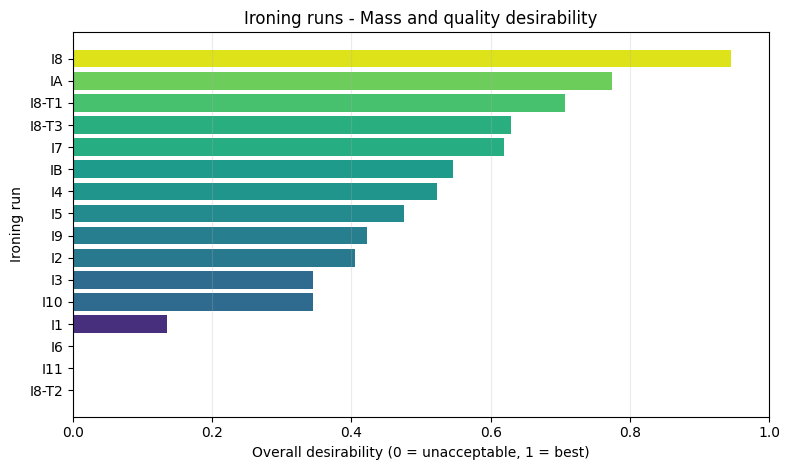

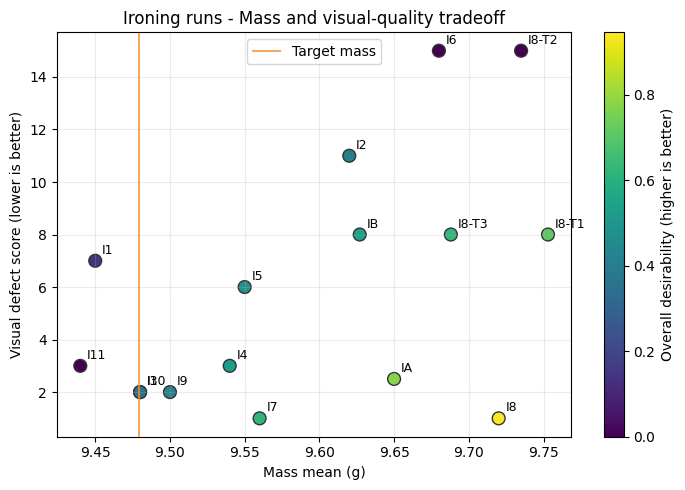

In [69]:
ironing_quality_result_matrix = build_result_matrix(
    ironing_coded,
    ironing_quality_table,
    response="quality_score",
)
ironing_quality_result_matrix_with_data = ironing_quality_result_matrix.dropna(
    subset=["quality_score"]
)

display(ironing_quality_result_matrix_with_data)

ironing_quality_model = fit_main_effect_screening_model(
    ironing_quality_result_matrix,
    response="quality_score",
    factor_cols=list(IRONING_LEVELS),
)

display(ironing_quality_model["info_df"].round(4))
display(ironing_quality_model["statistics_df"].round(4))
display(ironing_quality_model["fitted_df"].round(3))
ironing_quality_replicate_observations, ironing_quality_pure_error_groups, ironing_quality_pure_error_summary = (
    calculate_pure_error_from_replicates(
        ironing_quality_result_matrix,
        response="quality_score",
        factor_cols=list(IRONING_LEVELS),
        repeat_measurements_g=ironing_repeat_quality_table,
        repeat_response="quality_score",
    )
)
display(ironing_quality_pure_error_groups.round(4))
display(ironing_quality_pure_error_summary.round(4))
display(build_error_comparison_table(
    ironing_quality_model,
    ironing_quality_pure_error_summary,
).round(4))
ironing_quality_anova_table = build_model_anova_table(ironing_quality_model)
display(ironing_quality_anova_table.round(4))
display(
    build_term_significance_table(
        ironing_quality_model,
        pure_error_summary=ironing_quality_pure_error_summary,
    ).round(4)
)
plot_model_anova(
    ironing_quality_anova_table,
    response="quality_score",
    experiment="Ironing visual quality",
)

if ironing_quality_model["info_df"].loc[0, "full_rank"]:
    plot_augmented_model_pareto(
        ironing_quality_model,
        experiment="Ironing visual quality",
        pure_error_summary=ironing_quality_pure_error_summary,
    )
    plot_screening_model_effects(
        ironing_quality_model,
        experiment="Ironing visual quality",
    )
    plot_main_effects_line(
        ironing_quality_result_matrix_with_data,
        response="quality_score",
        experiment="Ironing visual quality",
    )
    plot_screening_observed_vs_predicted(
        ironing_quality_model,
        experiment="Ironing visual quality",
    )
else:
    print("The visual-quality measurements do not provide a full-rank main-effects model yet.")

if (
    ironing_main_effect_model["info_df"].loc[0, "full_rank"]
    and ironing_quality_model["info_df"].loc[0, "full_rank"]
):
    plot_combined_screening_model_effects(
        {
            "mass": ironing_main_effect_model,
            "visual quality": ironing_quality_model,
        },
        response_labels={
            "mass": "Mass",
            "visual quality": "Visual defect score",
        },
        normalize=True,
        experiment="Ironing runs",
    )

# Limits are based on the observed ironing runs and can be replaced by
# engineering acceptance limits when those are defined.
MASS_DESIRABILITY_LOW = ironing_mass_quality_tradeoff["mass_mean_g"].min()
MASS_DESIRABILITY_HIGH = ironing_mass_quality_tradeoff["mass_mean_g"].max()
QUALITY_DESIRABILITY_BEST = ironing_mass_quality_tradeoff["quality_score"].min()
QUALITY_DESIRABILITY_WORST = ironing_mass_quality_tradeoff["quality_score"].max()

ironing_desirability = build_desirability_table(
    ironing_mass_quality_tradeoff,
    mass_low=MASS_DESIRABILITY_LOW,
    mass_high=MASS_DESIRABILITY_HIGH,
    quality_best=QUALITY_DESIRABILITY_BEST,
    quality_worst=QUALITY_DESIRABILITY_WORST,
    mass_weight=1.0,
    quality_weight=1.0,
)

display(ironing_desirability[[
    "run",
    "mass_mean_g",
    "quality_score",
    "mass_desirability",
    "quality_desirability",
    "overall_desirability",
    "desirability_rank",
]].round(3))

plot_desirability_ranking(
    ironing_desirability,
    experiment="Ironing runs",
)
plot_mass_quality_tradeoff(
    ironing_desirability,
    target_mass_g=ideal_mass_ironing_g,
    experiment="Ironing runs",
)


,center_repeats_with_data,center_mean_g,between_print_std_g,center_range_g,max_pair_difference_g,max_pair_difference_percent,mean_within_print_std_g
0,3,9.473,0.031,0.06,0.06,0.63,NaN


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,run,mass_mean_g,mass_std_g,difference_from_center_mean_g,abs_difference_from_center_mean_g
Run,,,,,,,,,
9,0,0,0,0,I9,9.50,NaN,0.027,0.027
10,0,0,0,0,I10,9.48,NaN,0.007,0.007
11,0,0,0,0,I11,9.44,NaN,-0.033,0.033


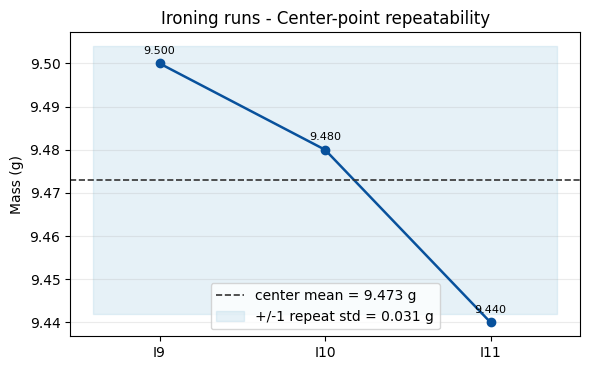

In [70]:
ironing_center_repeatability, ironing_center_repeatability_summary = (
    calculate_center_point_repeatability(
        ironing_coded,
        ironing_mass_measurements_g,
        response="mass_mean_g",
    )
)

display(ironing_center_repeatability_summary)
if not ironing_center_repeatability.empty:
    display(ironing_center_repeatability)
    plot_center_point_repeatability(
        ironing_center_repeatability,
        ironing_center_repeatability_summary,
        response="mass_mean_g",
        experiment="Ironing runs",
    )
else:
    print("Center-point repeatability will be available after measuring I9-I11.")


#### Ironing Overall Curvature Check


,factorial_runs_with_data,center_runs_with_data,factorial_mean_g,center_mean_g,overall_curvature_g,center_std_g
0,8,3,9.575,9.4733,-0.1017,0.0306


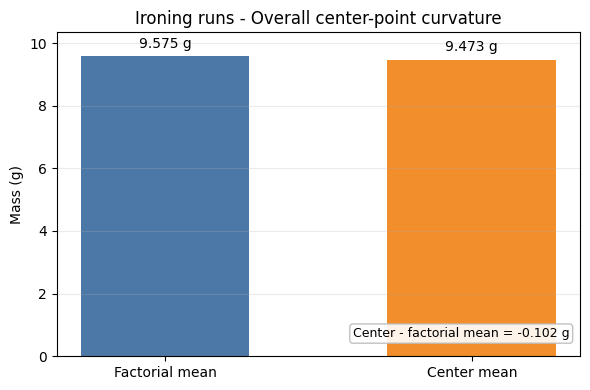

In [71]:
ironing_curvature_summary = calculate_center_curvature(
     ironing_coded,
     ironing_mass_measurements_g,
     response="mass_mean_g",
 )
display(ironing_curvature_summary.round(4))

if ironing_curvature_summary.loc[0, "center_runs_with_data"] > 0:
     plot_center_curvature(
         ironing_curvature_summary,
         experiment="Ironing runs",
     )
else:
     print(
         "Overall curvature will be available after at least one center run is measured. "
         "Measuring all I9-I11 is recommended so center repeatability can also be estimated."
     )


Measured factorial corners: 8/8


,Interaction,Alias / generator note,Effect
0,A_flow_ratio x B_nozzle_temp_C,,0.025
5,C_ironing_flow_percent x D_ironing_speed_mm_s,,0.025
3,B_nozzle_temp_C x C_ironing_flow_percent,,-0.020
2,A_flow_ratio x D_ironing_speed_mm_s,,-0.020
1,A_flow_ratio x C_ironing_flow_percent,,0.015
4,B_nozzle_temp_C x D_ironing_speed_mm_s,,0.015


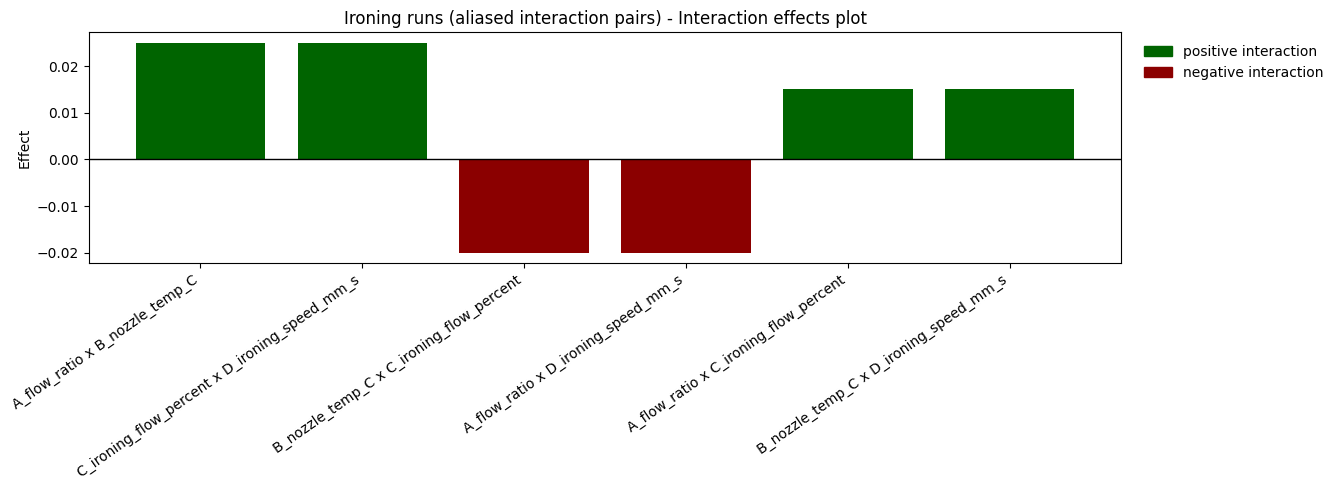

In [72]:
ironing_factorial_mask = ironing_result_matrix[list(IRONING_LEVELS)].abs().eq(1).all(axis=1)
ironing_factorial_with_data = ironing_result_matrix.loc[
    ironing_factorial_mask
].dropna(subset=["mass_mean_g"])

print(
    f"Measured factorial corners: {len(ironing_factorial_with_data)}/8"
)
if len(ironing_factorial_with_data) == 8:
    ironing_interaction_effects = compute_interaction_effects(
        ironing_factorial_with_data,
        response="mass_mean_g",
    )
    display(ironing_interaction_effects)
    plot_interaction_effects(
        ironing_interaction_effects,
        experiment="Ironing runs (aliased interaction pairs)",
    )
else:
    print(
        "Interaction estimates are deferred until all 8 factorial corners are measured. "
        "The interaction pairs will remain aliased: AB=CD, AC=BD, AD=BC."
    )
